In [308]:
'''
simultaneity criterion

so we want to say...transients are simultaneous if 
they are in the same file, and
no limit on snr for now, and
maybe we just subtract all the x's (star starting positions)
and then see what numbers end up the same?
or just do it on a case by case basis?
'''

"\nsimultaneity criterion\n\nso we want to say...transients are simultaneous if \nthey are in the same file, and\nno limit on snr for now, and\nmaybe we just subtract all the x's (star starting positions)\nand then see what numbers end up the same?\nor just do it on a case by case basis?\n"

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import os
import review_findings_functions as rff
import glob
import matplotlib.pyplot as plt

In [6]:
df_last = pd.read_csv("/home/3155/df_plus_snr")

/tmp/ipykernel_58352/2216848280.py:1: DtypeWarning: Columns (26,28) have mixed types. Specify dtype option on import or set low_memory=False.
  df_last = pd.read_csv("/home/3155/df_plus_snr")


(array([1.8521e+04, 1.5902e+04, 8.8900e+03, 4.7390e+03, 2.0700e+03,
        6.8700e+02, 2.0500e+02, 4.6000e+01, 2.0000e+01, 6.0000e+00,
        2.0000e+00, 2.0000e+00, 1.0000e+00, 1.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([2.50709635e-03, 1.39443566e-01, 2.76380036e-01, 4.13316506e-01,
        5.50252976e-01, 6.87189446e-01, 8.24125915e-01, 9.61062385e-01,
        1.09799886e+00, 1.23493533e+00, 1.37187179e+00, 1.50880826e+00,
        1.64574473e+00, 1.78268120e+00, 1.91961767e+00, 2.05655414e+00,
        2.19349061e+00, 2.33042708e+00, 2.46736355e+00, 2.60430002e+00,
        2.74123649e+00]),
 <BarContainer object of 20 artists>)

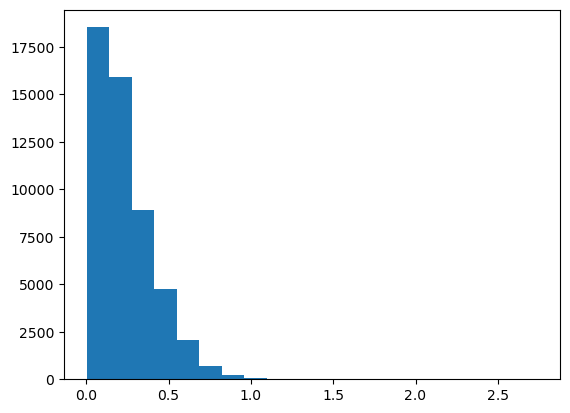

In [5]:
plt.hist(df_last['snr_local'], bins=20)

In [9]:
df_last.iloc[0]

Unnamed: 0.2                                                    0
Unnamed: 0.1                                                    0
Unnamed: 0                                                      0
0                                                               1
1                                                               1
2                                                               1
3                                                               4
4                                                               4
filename                 ztf_20221020297847_000449_zr_c05_x_0006.
type                                                          pos
row_from_nn                                               655.625
col_from_nn                                               1208.75
detection_size                                                8.0
quadrant                                                        4
sobel_ratio                                             12.620198
snr_center

In [35]:
our_cands = df_last[df_last['snr_local']>1]

In [2]:
def add_distance_from_start(df):
    '''
    difference between the star's starting position
    along the streak 
    and the transient candidate's position
    essentially a time delay
    '''
    df['distance_from_start'] = df['closest_y']-(df['row_from_nn']+10)
    return df

In [9]:
df_last = add_distance_from_start(df_last)

In [24]:
same_file = df_last[df_last['filename']=='ztf_20221020163819_000640_zg_c16_x_0025.']

In [ ]:
def get_num_simultaneous(same_file_df, tolerance):
    

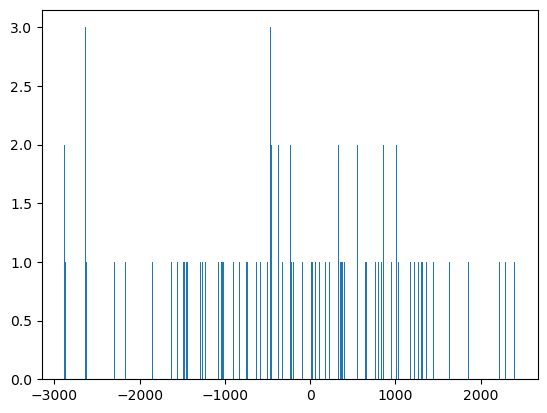

In [33]:
data = same_file['distance_from_start']
n, bins, third_thing = plt.hist(data, bins=np.arange(min(data), max(data) + binwidth, binwidth))

In [45]:
our_cands

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,in_vari_summary,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,num_simultaneous
776,776,776,776,9074,2,2,11,11,ztf_20221020297847_000449_zr_c01_x_0008.,pos,...,NaN,1.110102,0.782343,22.590435,32.054603,766.986678,108.024735,9.0,25.077692,12
1389,1389,1389,1389,16380,309,309,636,636,ztf_20221020148032_000686_zg_c16_x_0005.,neg,...,False,1.032185,0.910907,33.465428,37.921016,1151.866137,188.627551,10.0,34.542521,12
2018,2018,2018,2018,24274,2,2,23,23,ztf_20221020163819_000640_zg_c16_x_0025.,pos,...,False,1.249588,1.050896,23.332121,27.743484,790.377811,93.505917,12.0,29.155529,12
2022,2022,2022,2022,24294,22,22,79,79,ztf_20221020163819_000640_zg_c16_x_0025.,neg,...,False,1.217411,0.967004,29.931357,37.682118,1267.977484,135.349310,13.0,36.438755,12
3935,3935,3935,3935,47566,23,23,110,110,ztf_20221020148032_000686_zg_c05_x_0006.,neg,...,False,1.006164,0.869902,34.929113,40.400426,1422.732745,110.330402,14.0,35.144413,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46783,46783,46783,46783,559047,76,76,151,151,ztf_20221020154120_000640_zi_c11_x_0011.,neg,...,False,1.068315,0.883177,69.766877,84.391967,1775.956407,375.179674,19.0,74.533007,12
47083,47083,47083,47083,562662,1,1,6,6,ztf_20221020297847_000449_zr_c11_x_0001.,neg,...,False,1.016414,0.895957,33.783140,38.325107,1222.968342,115.624714,15.0,34.337656,12
47176,47176,47176,47176,563723,2,2,7,7,ztf_20221020294271_000449_zr_c14_x_0006.,neg,...,False,1.187467,0.765152,40.767467,63.268503,1762.204564,176.759618,19.0,48.410012,12
47177,47177,47177,47177,563724,3,3,8,8,ztf_20221020294271_000449_zr_c14_x_0006.,neg,...,False,1.242942,0.762671,38.201527,62.257870,1773.873260,261.594695,12.0,47.482271,12


In [48]:
df_last

/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/IPython/lib/pretty.py:778: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  output = repr(obj)
/lustre/lrspec/users/3155/anaconda3/envs/trans/lib/python3.11/site-packages/IPython/core/formatters.py:344: FutureWarning: In a future version, object-dtype columns with all-bool values will not be included in reductions with bool_only=True. Explicitly cast to bool dtype instead.
  return method()


,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,in_vari_summary,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,distance_from_start
0,0,0,0,1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,...,False,0.561214,0.467633,30.341491,36.413309,943.401942,86.507360,5.0,17.028074,1543.375000
1,1,1,1,3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,...,False,0.620627,0.620049,36.286720,36.320508,943.886565,107.039582,7.0,22.520506,-144.333333
2,2,2,2,4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,...,False,0.568131,0.496890,31.895010,36.467898,946.518128,89.411744,6.0,18.120534,1552.000000
3,3,3,3,24,0,0,3,3,ztf_20221020163819_000640_zg_c01_x_0021.,pos,...,False,0.187912,0.140407,323.398782,432.817956,18434.581445,990.461523,6.0,60.770618,2177.272727
4,4,4,4,25,1,1,28,28,ztf_20221020163819_000640_zg_c01_x_0021.,pos,...,False,0.070187,0.055700,344.321438,433.877089,18118.672705,460.354346,3.0,24.166964,1929.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51088,51088,51088,51088,610705,70,70,171,171,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,NaN,0.060841,0.042777,134.400807,191.155077,4215.145792,139.619344,2.0,8.177057,-281.000000
51089,51089,51089,51089,610710,75,75,176,176,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,NaN,0.054796,0.050992,177.336920,190.564873,4178.635997,252.517323,2.0,9.717292,-397.300000
51090,51090,51090,51090,610739,104,104,231,231,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,NaN,0.368725,0.304254,157.331949,190.670680,4111.105854,380.991597,12.0,58.012239,-1311.777778
51091,51091,51091,51091,610746,111,111,243,243,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,NaN,0.389052,0.360172,174.913743,188.939144,4105.894153,532.613391,12.0,68.050614,-1520.500000


In [54]:
num_simultaneous = []

In [56]:
num_simultaneous.append(1)

In [57]:
num_simultaneous

[1]

ztf_20221020297847_000449_zr_c01_x_0008.


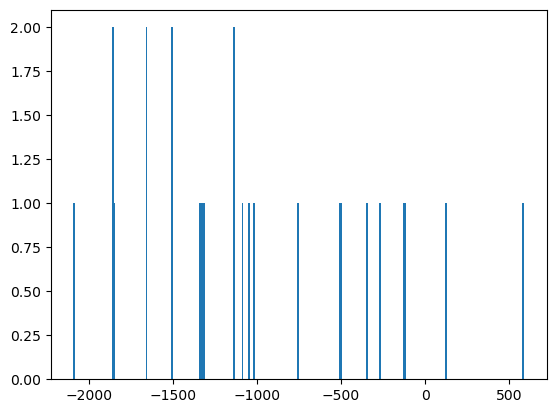

ztf_20221020148032_000686_zg_c16_x_0005.


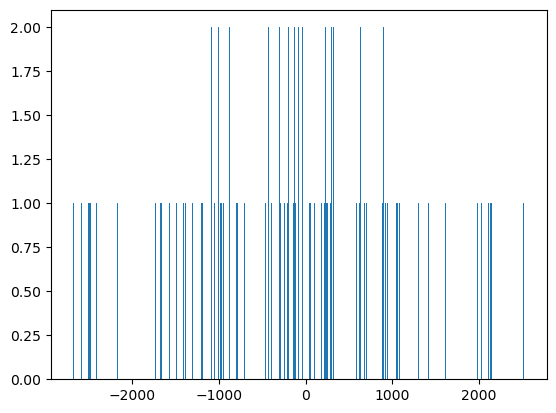

ztf_20221020163819_000640_zg_c16_x_0025.


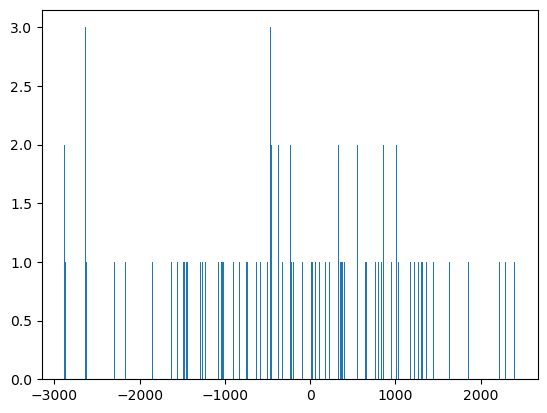

ztf_20221020163819_000640_zg_c16_x_0025.


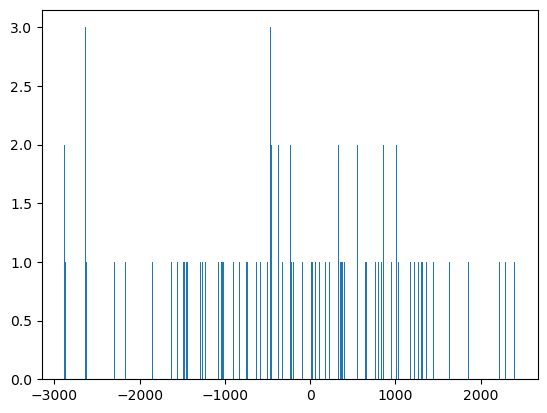

ztf_20221020148032_000686_zg_c05_x_0006.


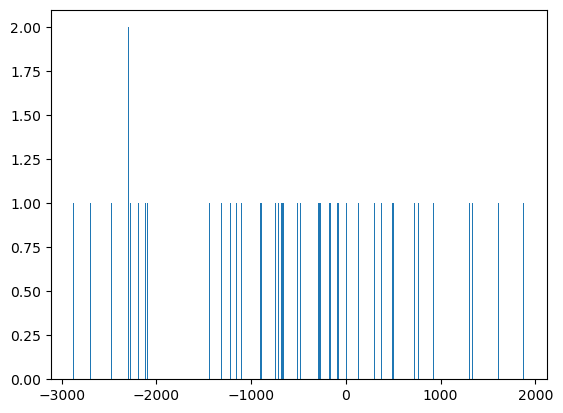

ztf_20221020148032_000686_zg_c16_x_0014.


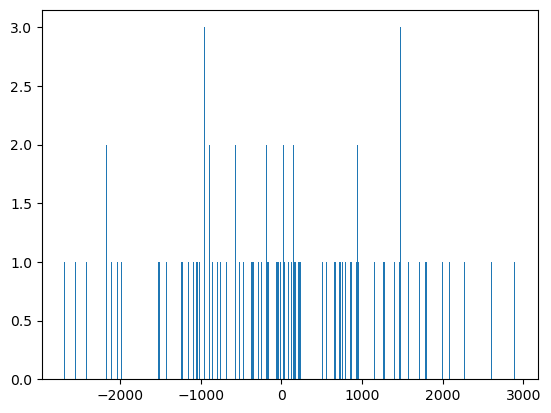

ztf_20221020154120_000640_zi_c04_x_0018.


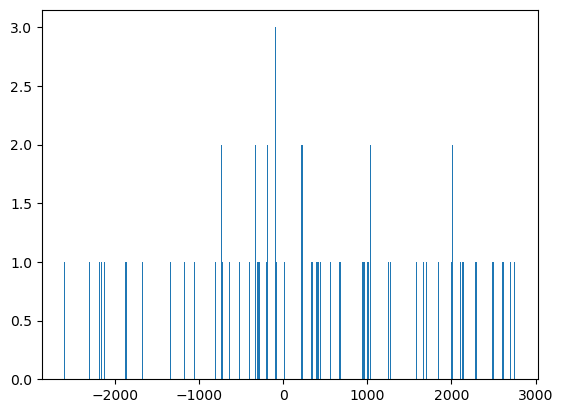

ztf_20221020294271_000449_zr_c09_x_0009.


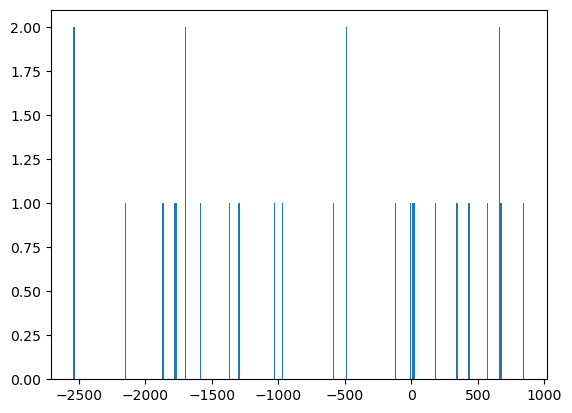

ztf_20221020157697_000640_zi_c04_x_0022.


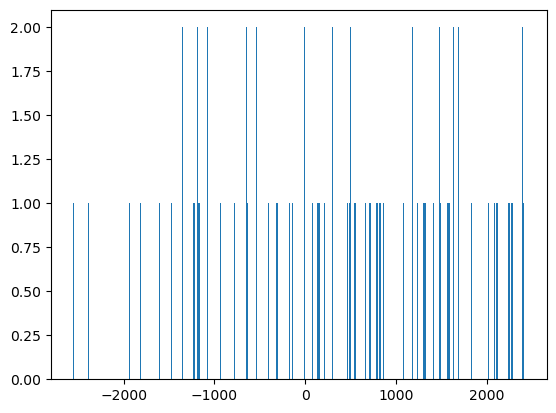

ztf_20221020157697_000640_zi_c04_x_0022.


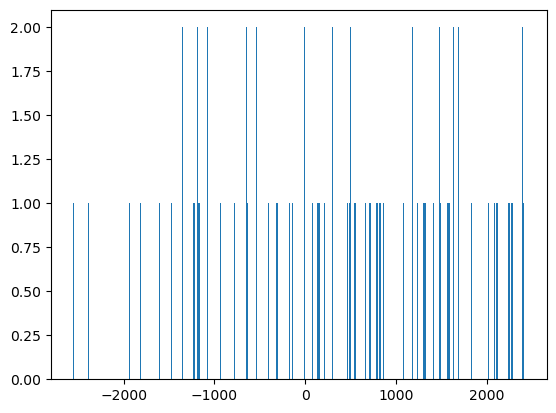

ztf_20221020294271_000449_zr_c14_x_0017.


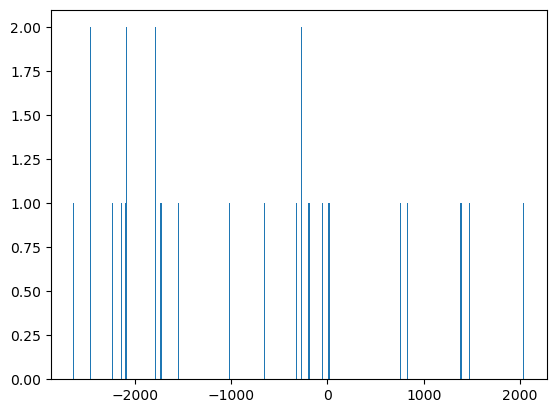

ztf_20221020141806_000686_zi_c14_x_0013.


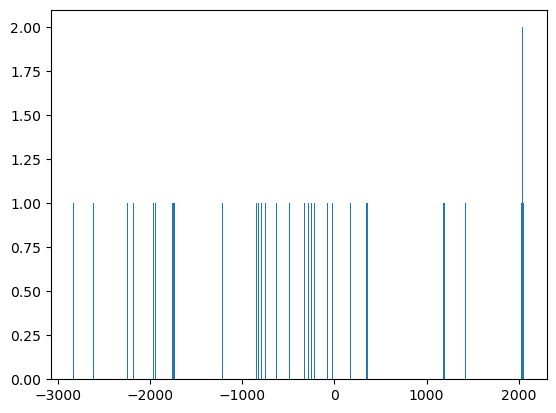

ztf_20221020294271_000449_zr_c09_x_0011.


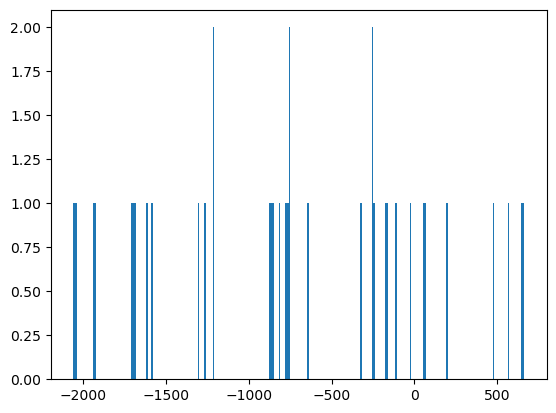

ztf_20221020148032_000686_zg_c11_x_0026.


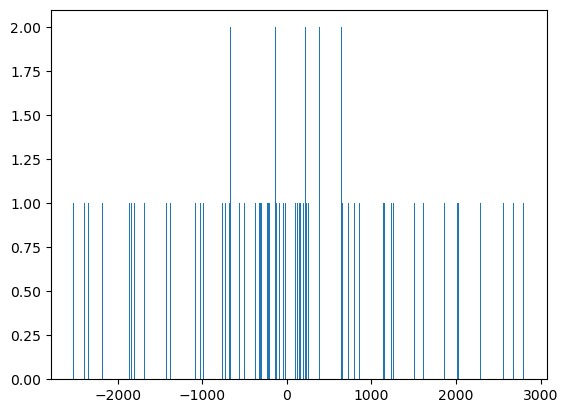

ztf_20221020294271_000449_zr_c09_x_0018.


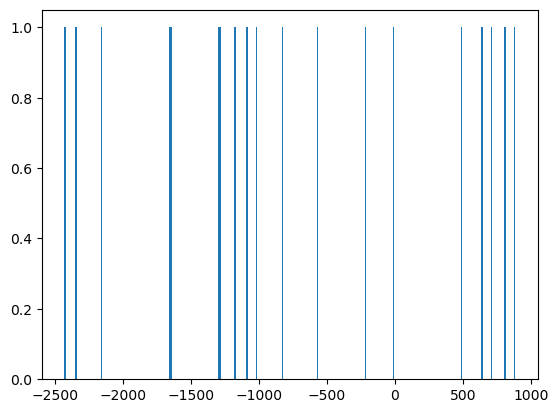

ztf_20221020148032_000686_zg_c16_x_0010.


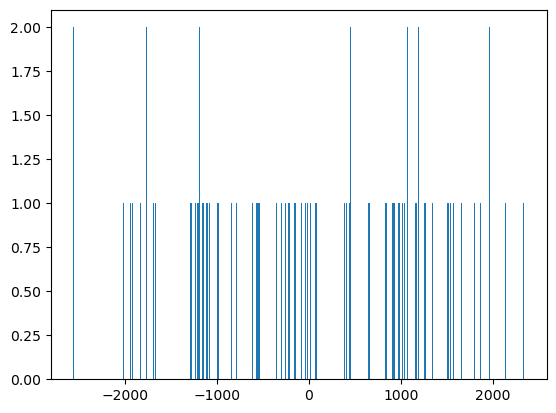

ztf_20221020154120_000640_zi_c13_x_0018.


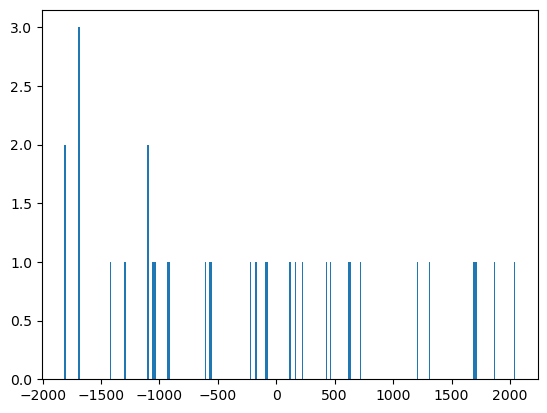

ztf_20221020297847_000449_zr_c09_x_0012.


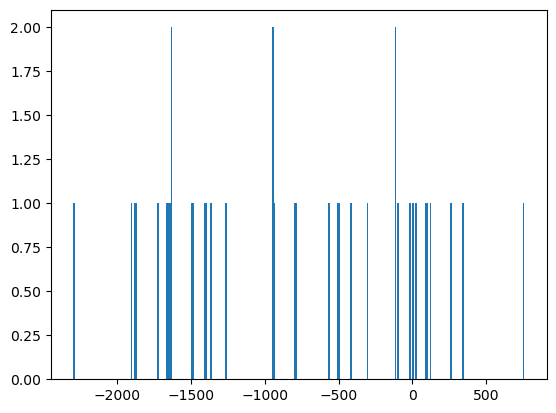

ztf_20221020154120_000640_zi_c08_x_0014.


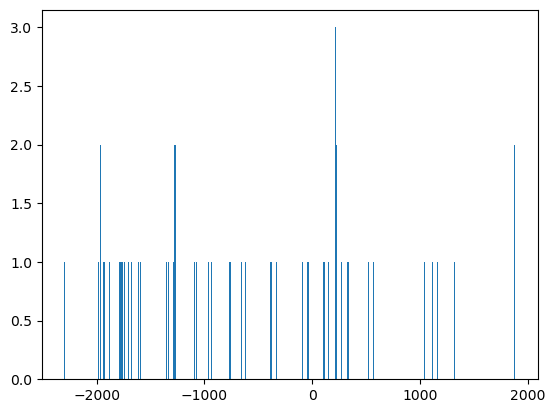

ztf_20221020154120_000640_zi_c08_x_0014.


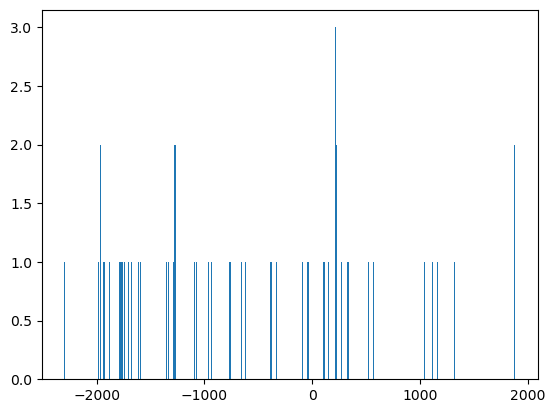

ztf_20221020154120_000640_zi_c08_x_0014.


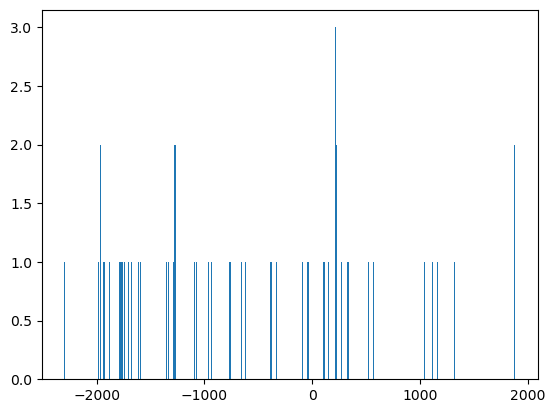

ztf_20221020138241_000686_zi_c08_x_0000.


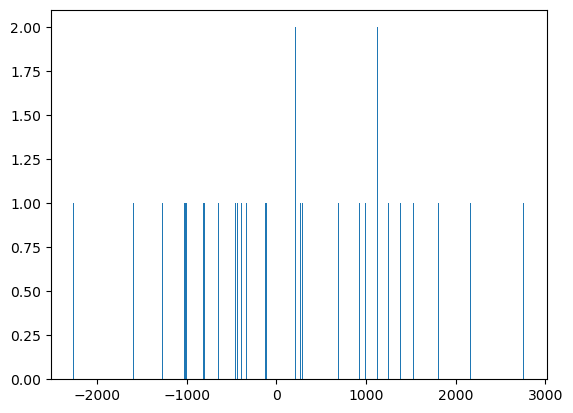

ztf_20221020157697_000640_zi_c16_x_0005.


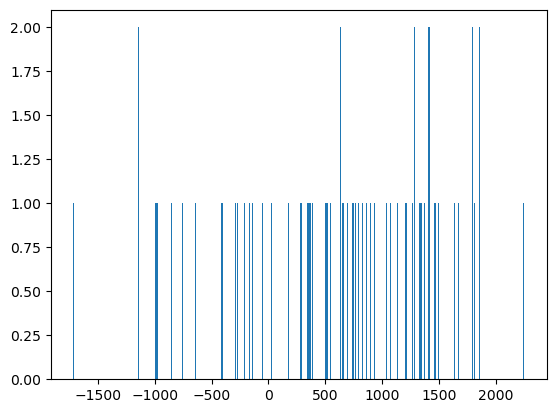

ztf_20221020163819_000640_zg_c10_x_0011.


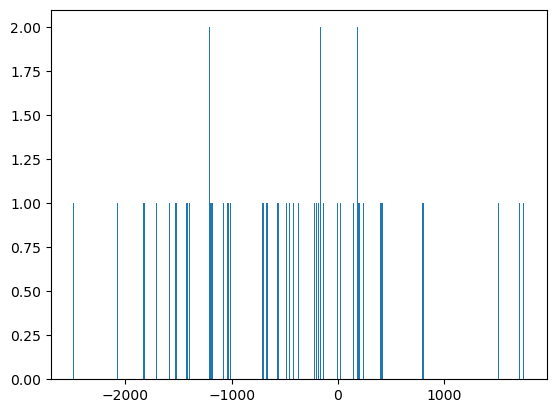

ztf_20221020297847_000449_zr_c14_x_0019.


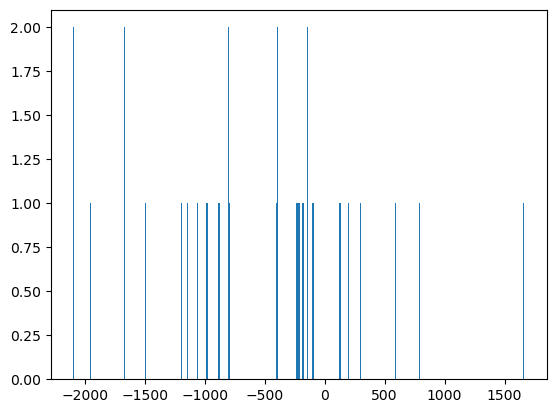

ztf_20221020294271_000449_zr_c12_x_0023.


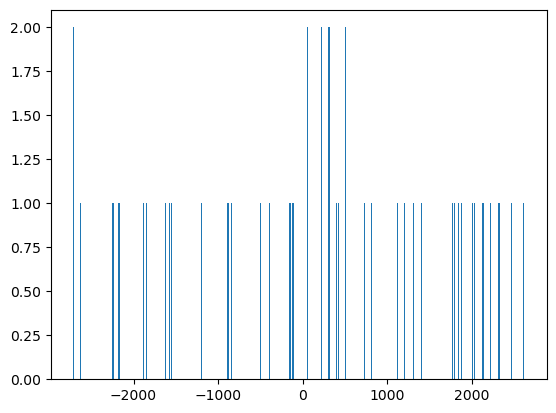

ztf_20221020148032_000686_zg_c09_x_0007.


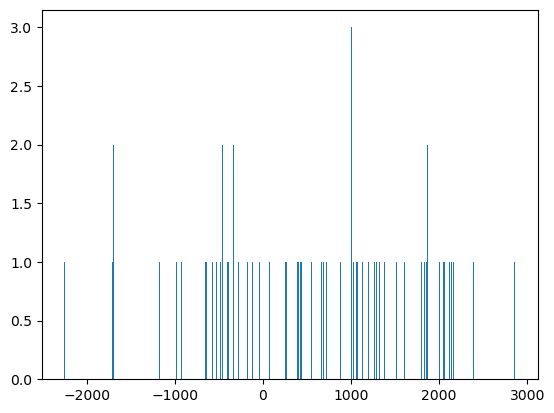

ztf_20221020297847_000449_zr_c09_x_0016.


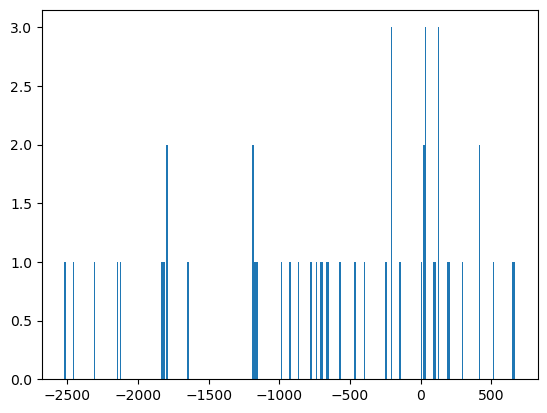

ztf_20221020154120_000640_zi_c11_x_0019.


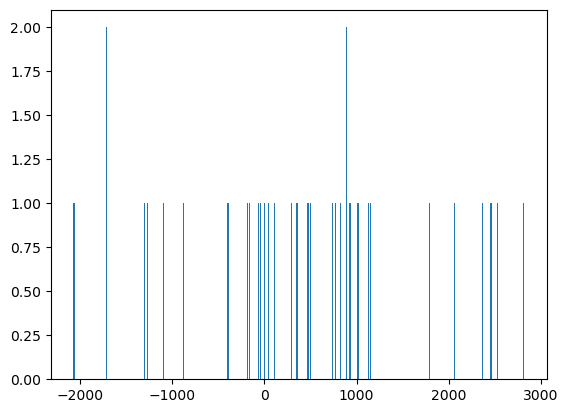

ztf_20221020297847_000449_zr_c03_x_0015.


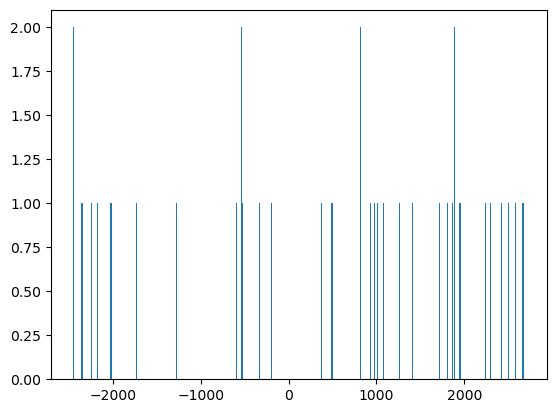

ztf_20221020297847_000449_zr_c03_x_0015.


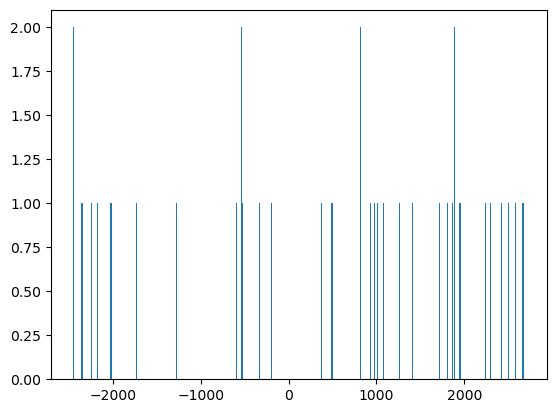

ztf_20221020148032_000686_zg_c03_x_0019.


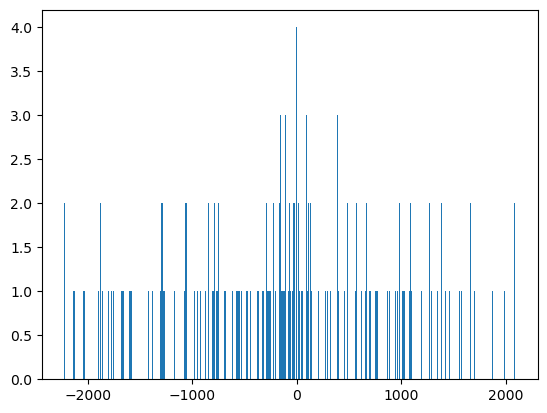

ztf_20221020154120_000640_zi_c11_x_0008.


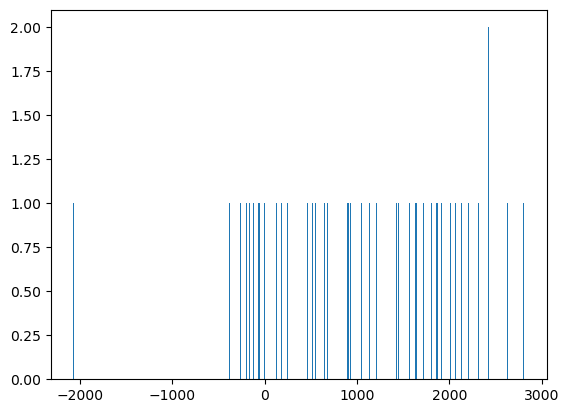

ztf_20221020297847_000449_zr_c03_x_0004.


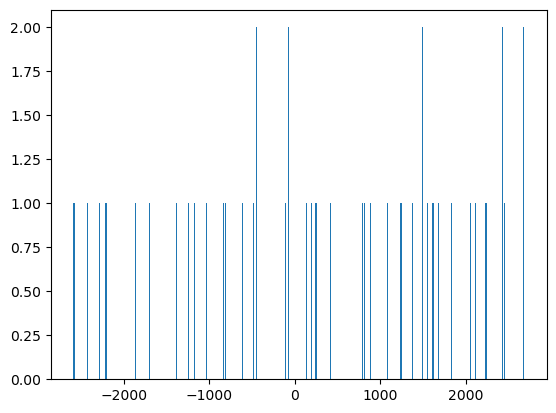

ztf_20221020138241_000686_zi_c02_x_0029.


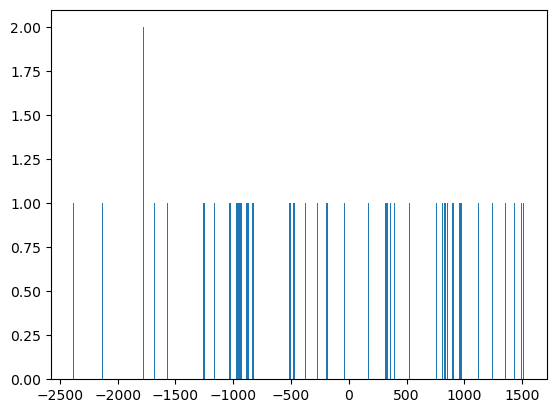

ztf_20221020138241_000686_zi_c02_x_0029.


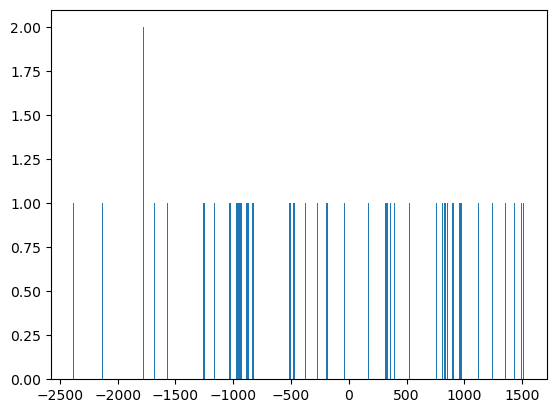

ztf_20221020163819_000640_zg_c07_x_0000.


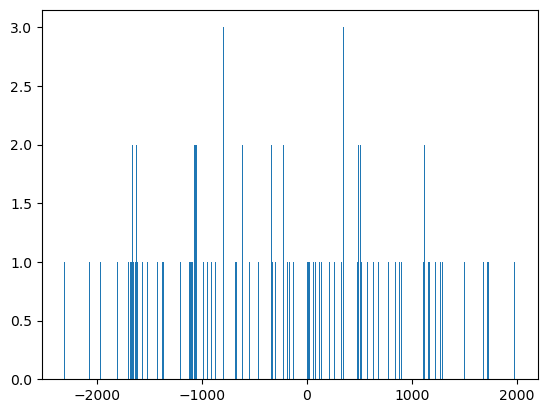

ztf_20221020148032_000686_zg_c01_x_0018.


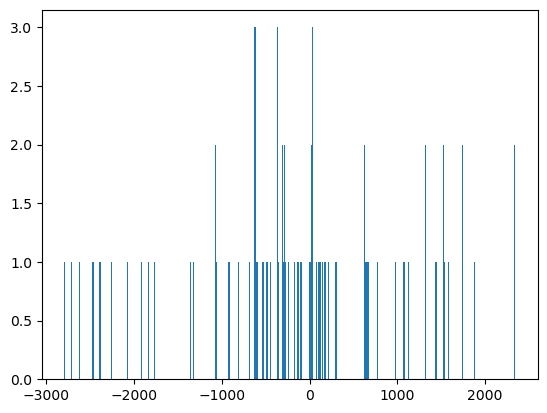

ztf_20221020297847_000449_zr_c14_x_0015.


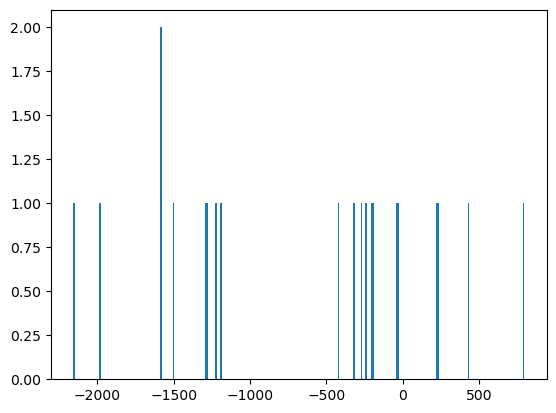

ztf_20221020163819_000640_zg_c06_x_0025.


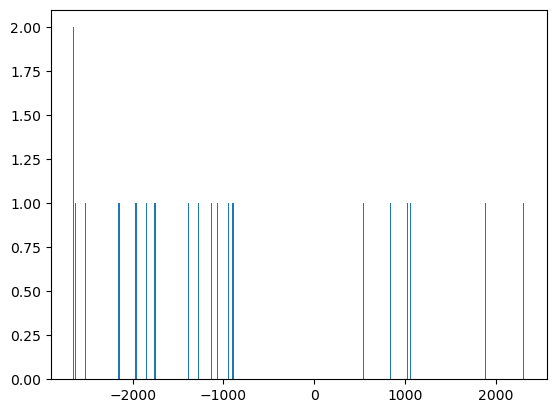

ztf_20221020138241_000686_zi_c08_x_0001.


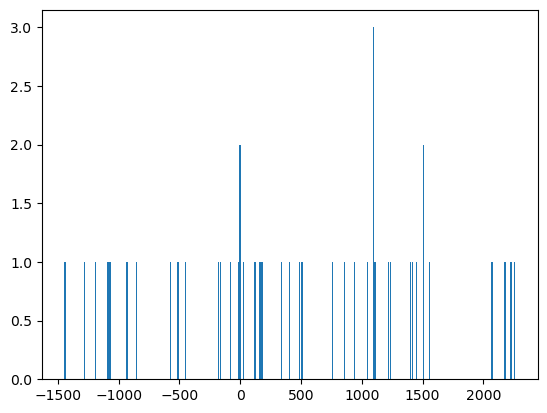

ztf_20221020297847_000449_zr_c14_x_0019.


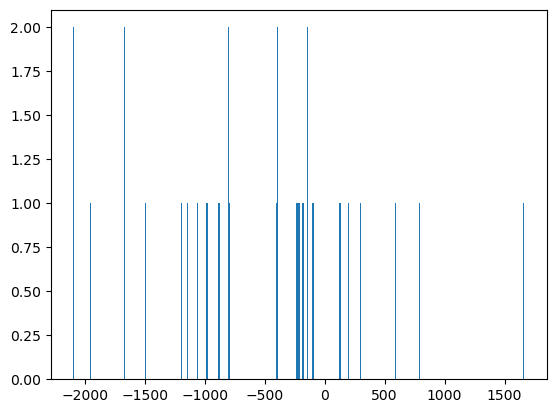

ztf_20221020148032_000686_zg_c07_x_0016.


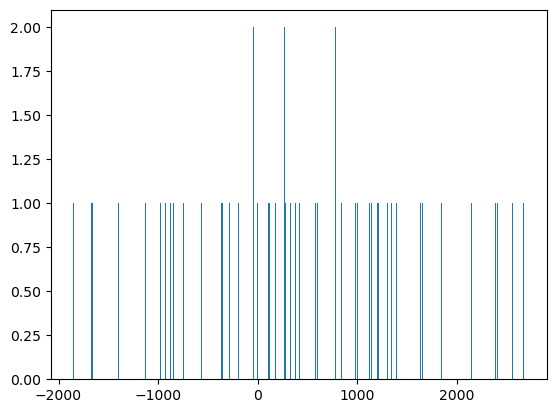

ztf_20221020148032_000686_zg_c03_x_0004.


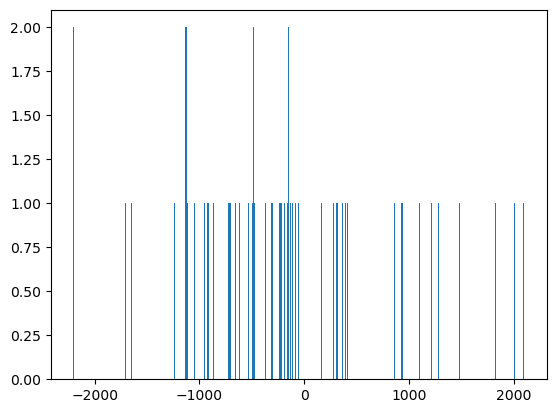

ztf_20221020148032_000686_zg_c03_x_0023.


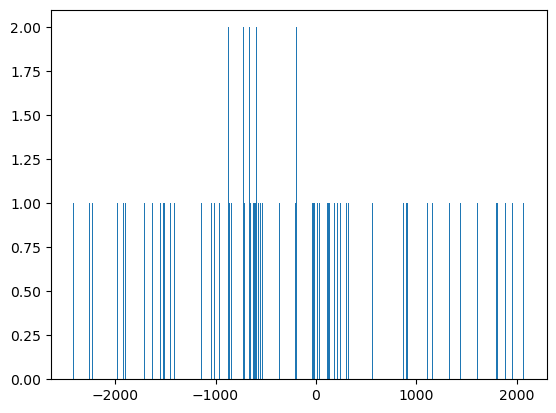

ztf_20221020297847_000449_zr_c15_x_0013.


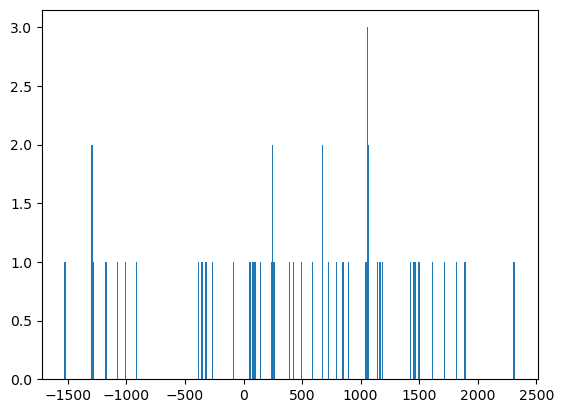

ztf_20221020148032_000686_zg_c16_x_0014.


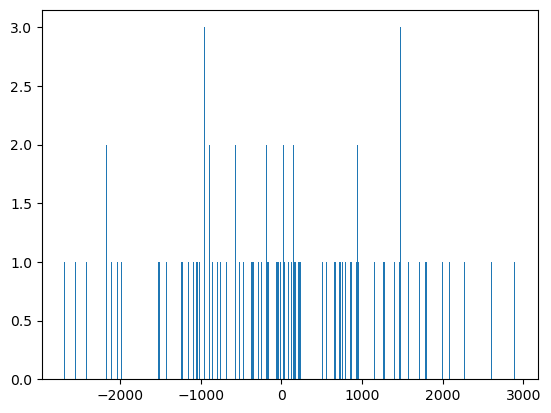

ztf_20221020154120_000640_zi_c11_x_0004.


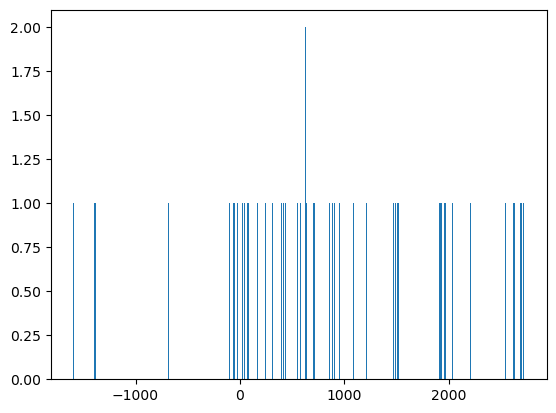

ztf_20221020154120_000640_zi_c11_x_0004.


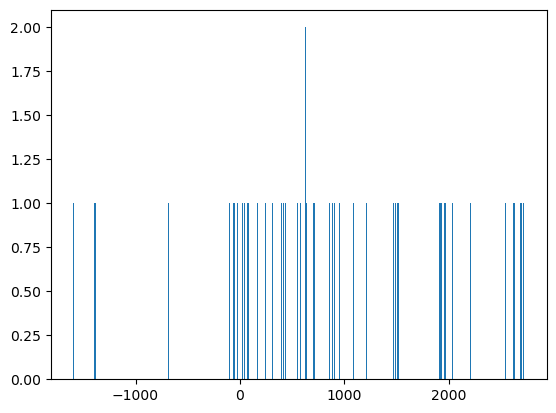

ztf_20221020148032_000686_zg_c03_x_0008.


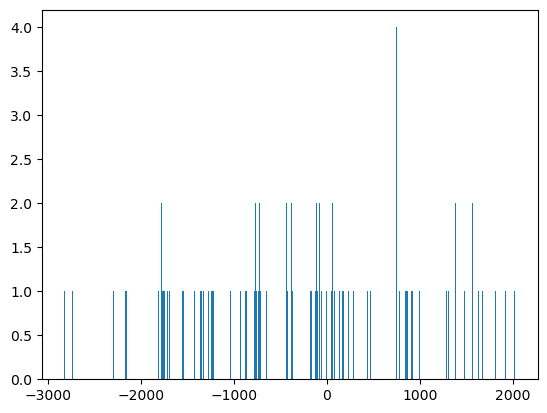

ztf_20221020138241_000686_zi_c16_x_0010.


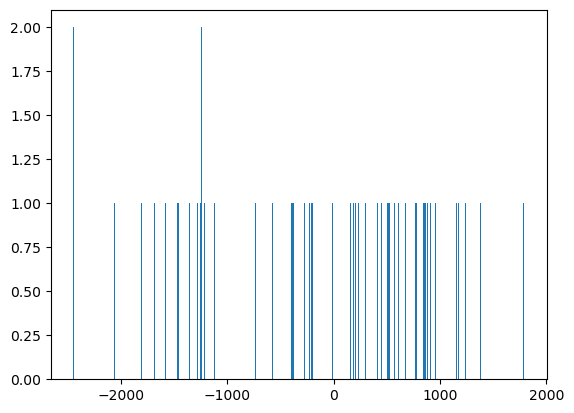

ztf_20221020154120_000640_zi_c11_x_0015.


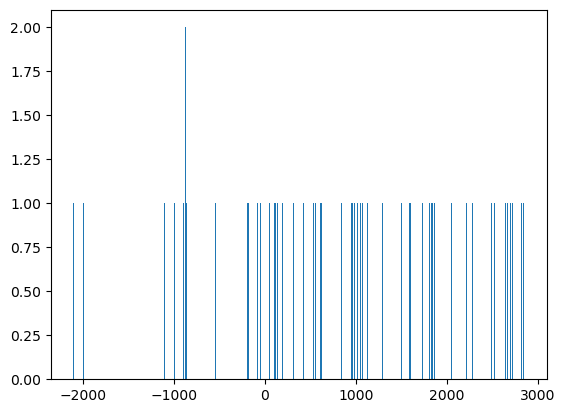

ztf_20221020154120_000640_zi_c11_x_0015.


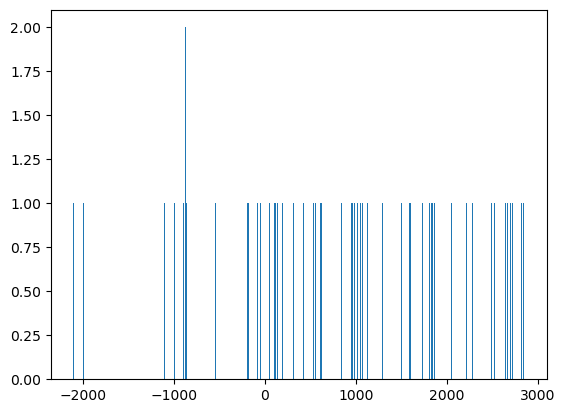

ztf_20221020141806_000686_zi_c16_x_0028.


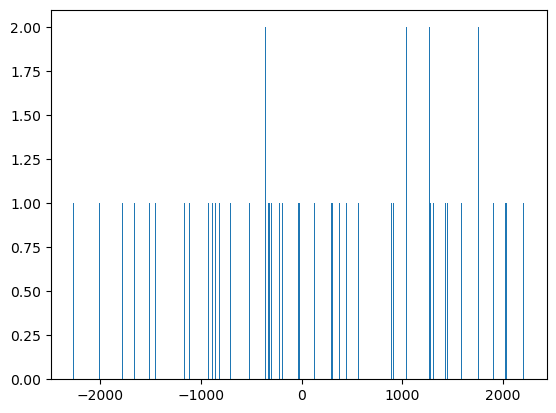

ztf_20221020148032_000686_zg_c12_x_0017.


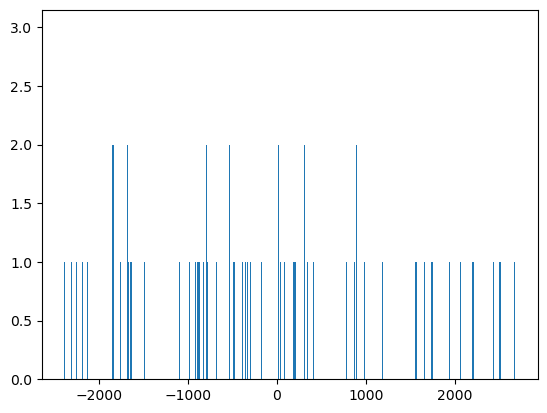

ztf_20221020148032_000686_zg_c03_x_0011.


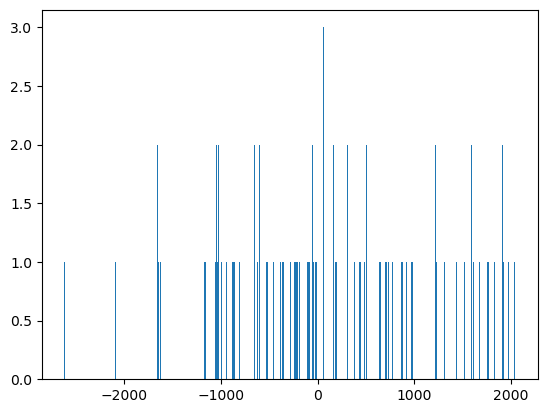

ztf_20221020163819_000640_zg_c04_x_0007.


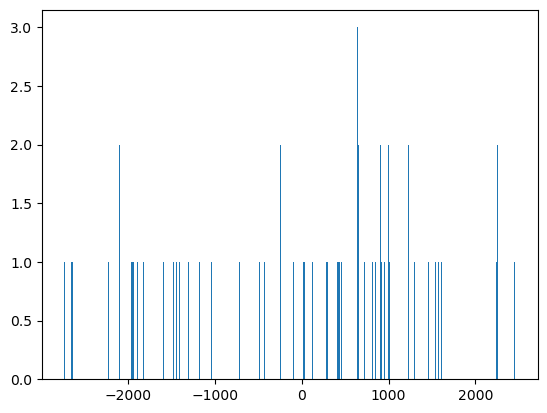

ztf_20221020138241_000686_zi_c14_x_0018.


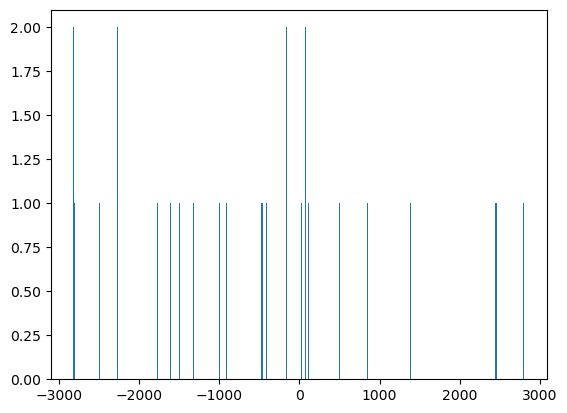

ztf_20221020163819_000640_zg_c04_x_0016.


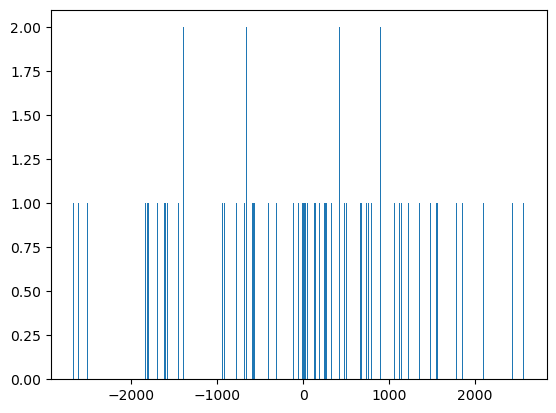

ztf_20221020163819_000640_zg_c04_x_0016.


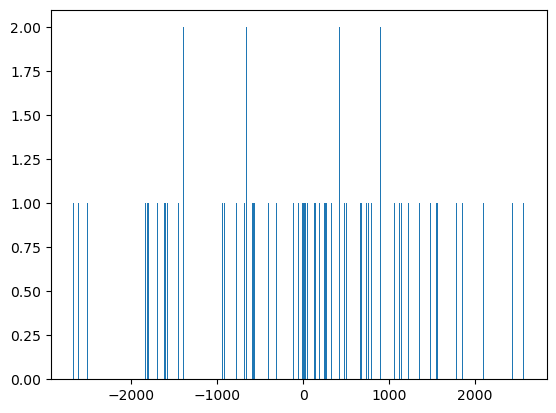

ztf_20221020154120_000640_zi_c11_x_0011.


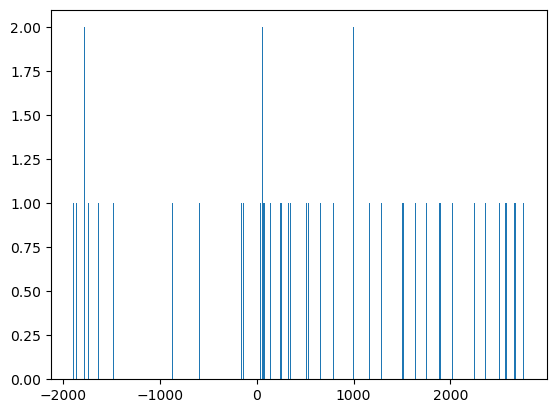

ztf_20221020297847_000449_zr_c11_x_0001.


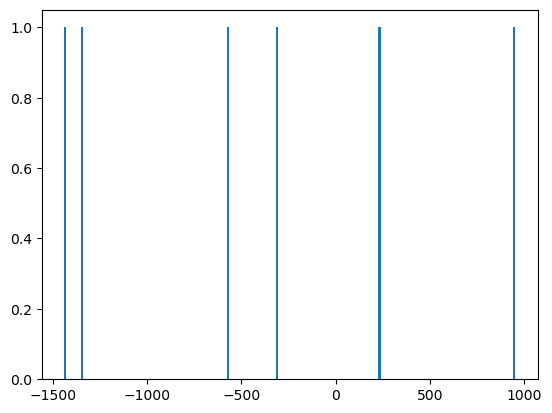

ztf_20221020294271_000449_zr_c14_x_0006.


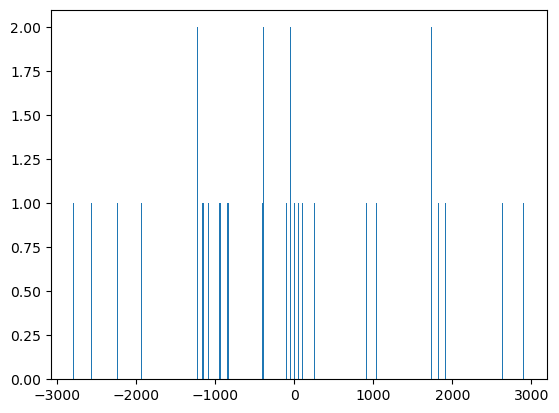

ztf_20221020294271_000449_zr_c14_x_0006.


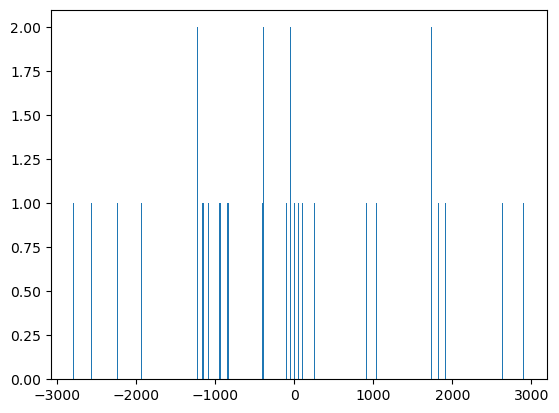

ztf_20221020157697_000640_zi_c11_x_0004.


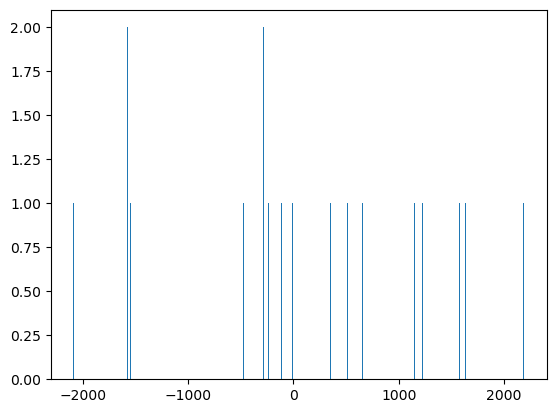

In [58]:
#so let's get some numbers
num_simultaneous = []
for i, row in our_cands.iterrows():
    same_file_df = df_last[df_last['filename']==row['filename']]
    print(row['filename'])
    binwidth = 10
    data = same_file_df['distance_from_start']
    n, bins, third_thing = plt.hist(data, bins=np.arange(min(data), max(data) + binwidth, binwidth))
    np.sum(n>1)
    num_simultaneous.append(np.sum(n>1))
    plt.show()

ztf_20221020297847_000449_zr_c01_x_0008.


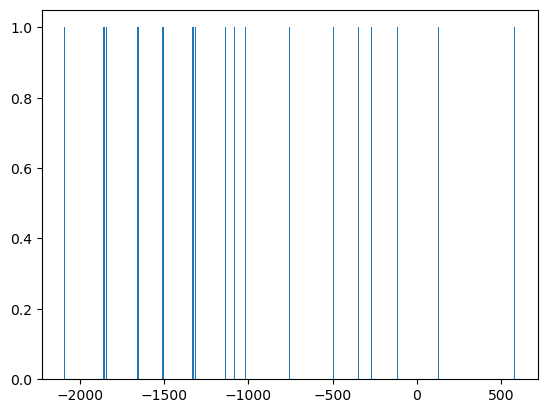

ztf_20221020148032_000686_zg_c16_x_0005.


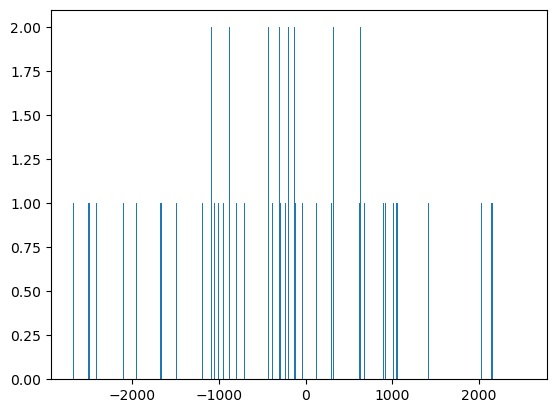

ztf_20221020163819_000640_zg_c16_x_0025.


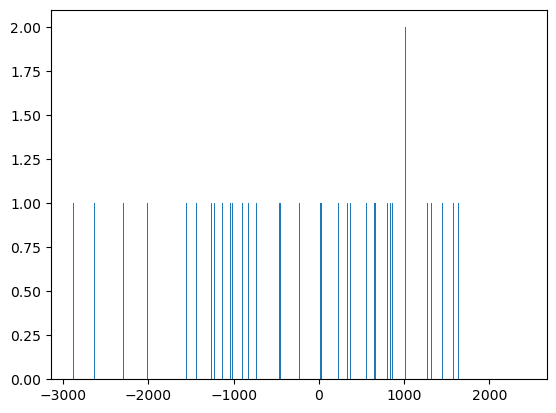

ztf_20221020163819_000640_zg_c16_x_0025.


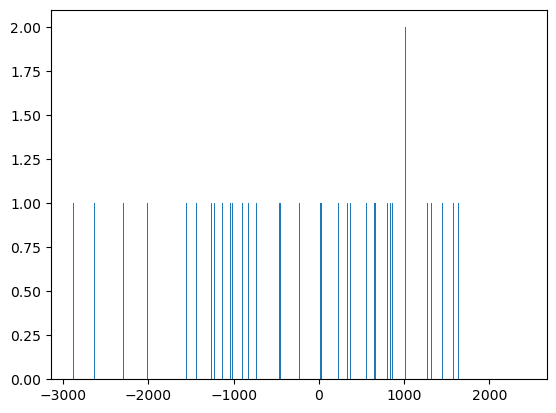

ztf_20221020148032_000686_zg_c05_x_0006.


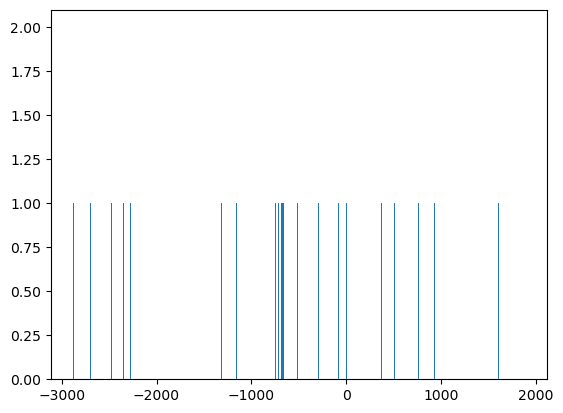

ztf_20221020148032_000686_zg_c16_x_0014.


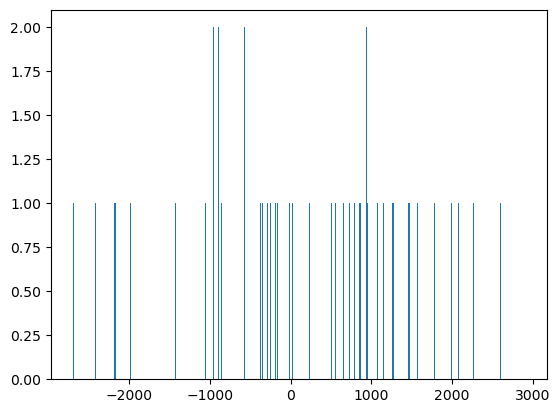

ztf_20221020154120_000640_zi_c04_x_0018.


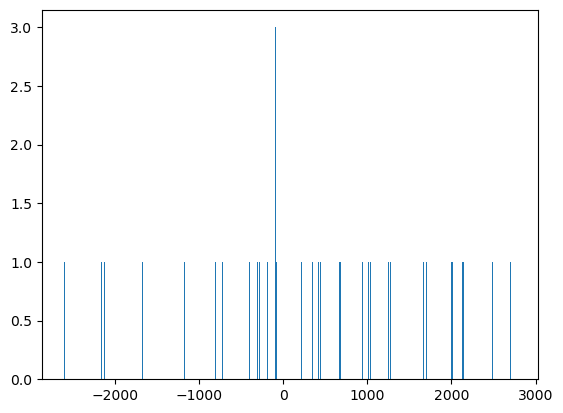

ztf_20221020294271_000449_zr_c09_x_0009.


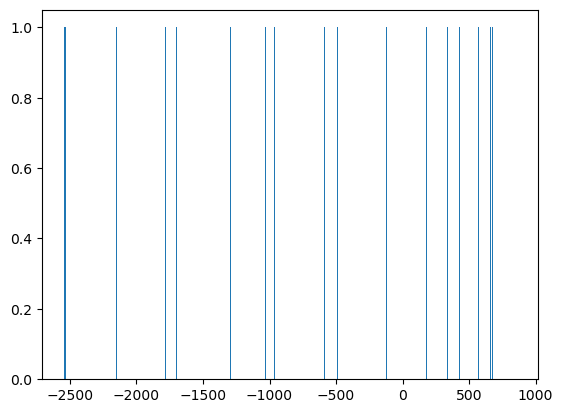

ztf_20221020157697_000640_zi_c04_x_0022.


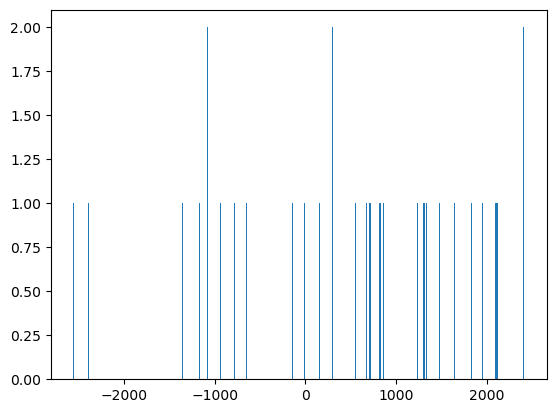

ztf_20221020157697_000640_zi_c04_x_0022.


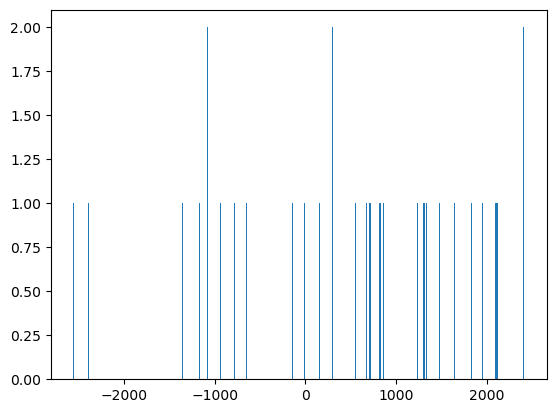

ztf_20221020294271_000449_zr_c14_x_0017.


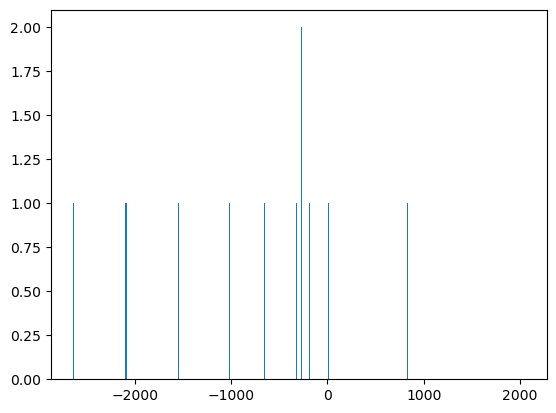

ztf_20221020141806_000686_zi_c14_x_0013.


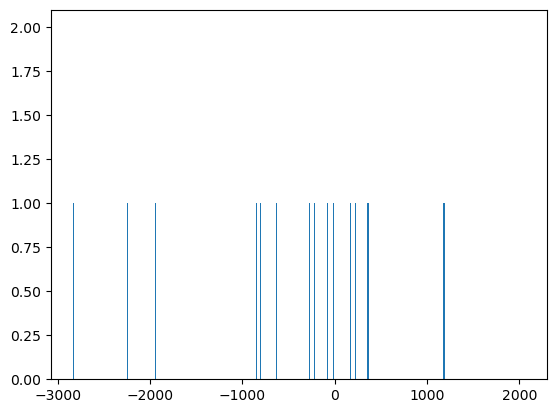

ztf_20221020294271_000449_zr_c09_x_0011.


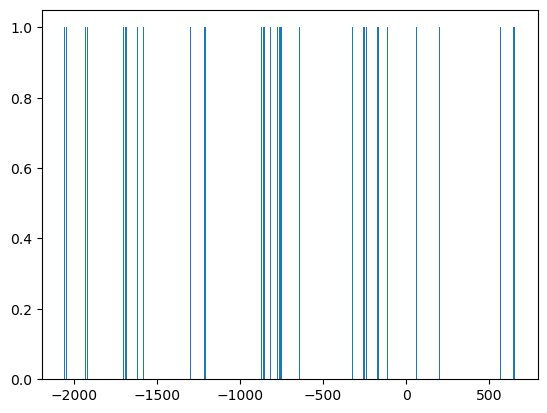

ztf_20221020148032_000686_zg_c11_x_0026.


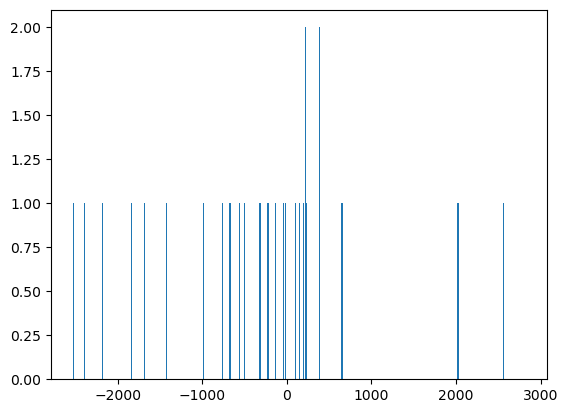

ztf_20221020294271_000449_zr_c09_x_0018.


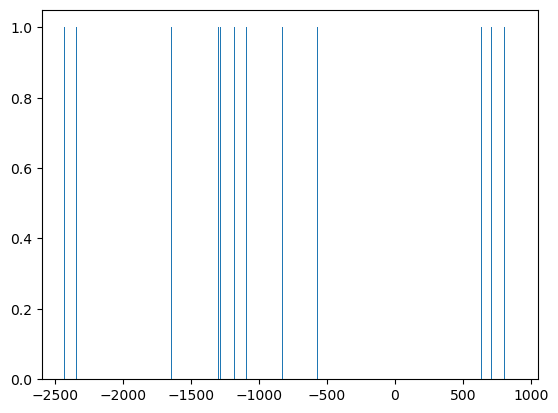

ztf_20221020148032_000686_zg_c16_x_0010.


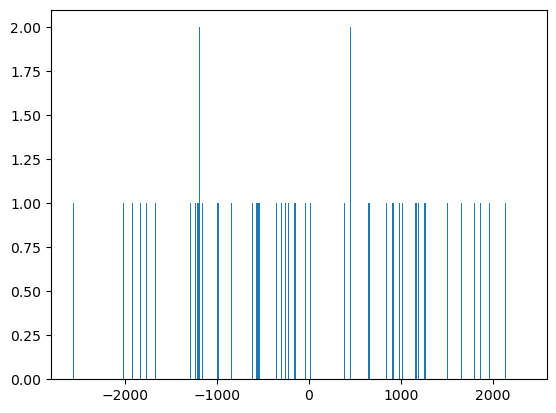

ztf_20221020154120_000640_zi_c13_x_0018.


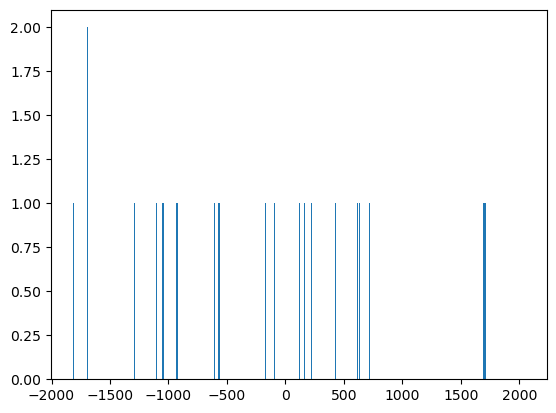

ztf_20221020297847_000449_zr_c09_x_0012.


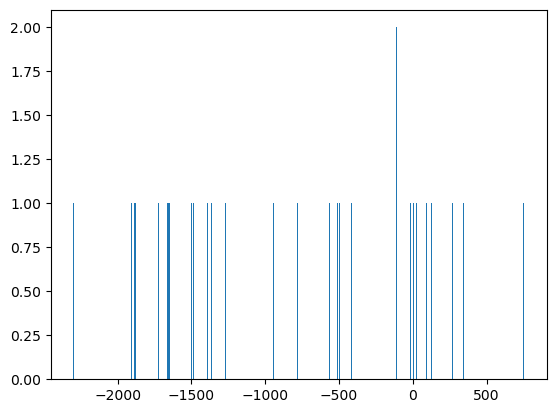

ztf_20221020154120_000640_zi_c08_x_0014.


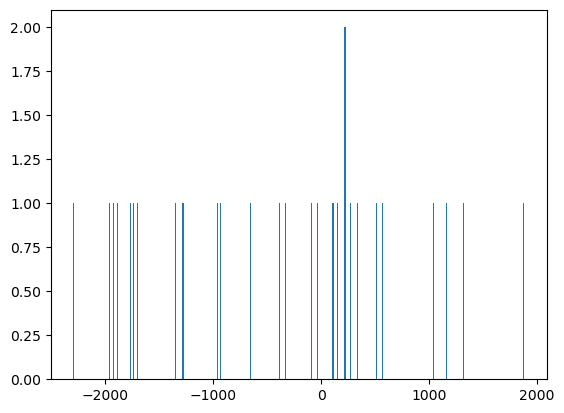

ztf_20221020154120_000640_zi_c08_x_0014.


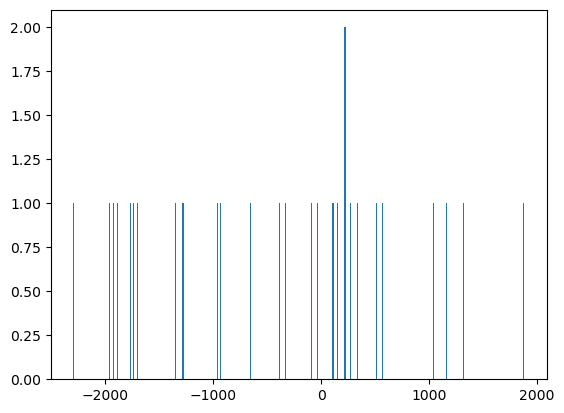

ztf_20221020154120_000640_zi_c08_x_0014.


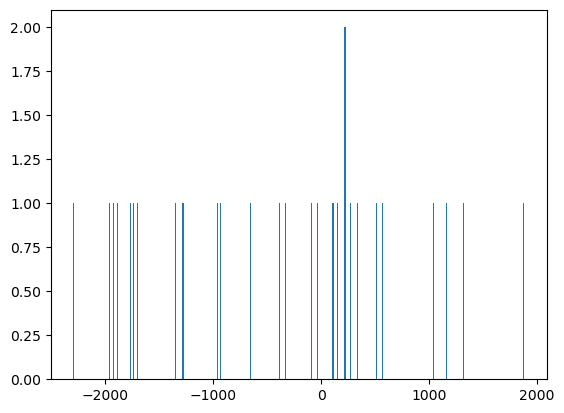

ztf_20221020138241_000686_zi_c08_x_0000.


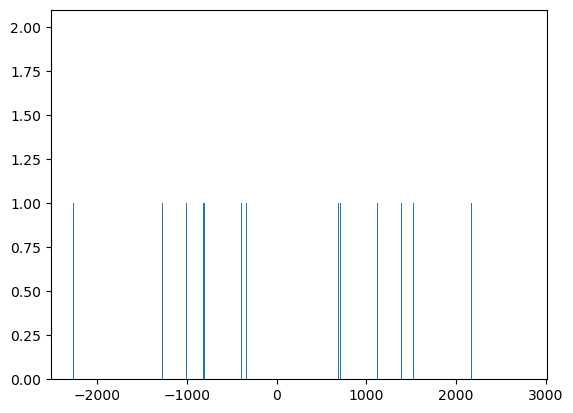

ztf_20221020157697_000640_zi_c16_x_0005.


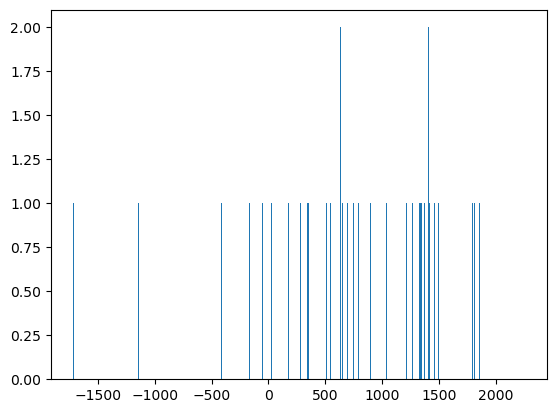

ztf_20221020163819_000640_zg_c10_x_0011.


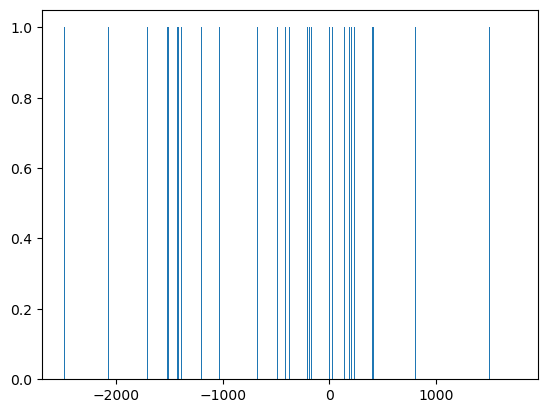

ztf_20221020297847_000449_zr_c14_x_0019.


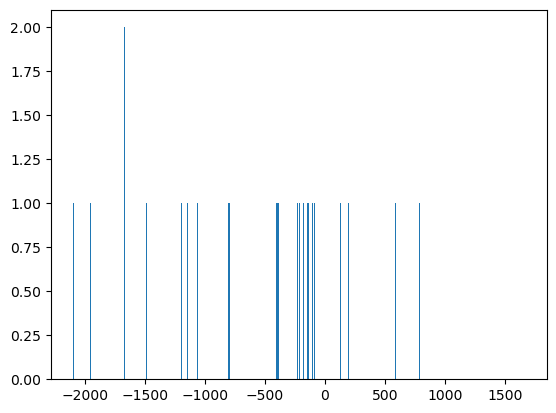

ztf_20221020294271_000449_zr_c12_x_0023.


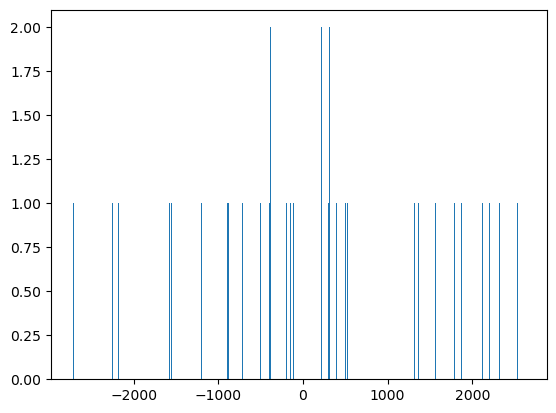

ztf_20221020148032_000686_zg_c09_x_0007.


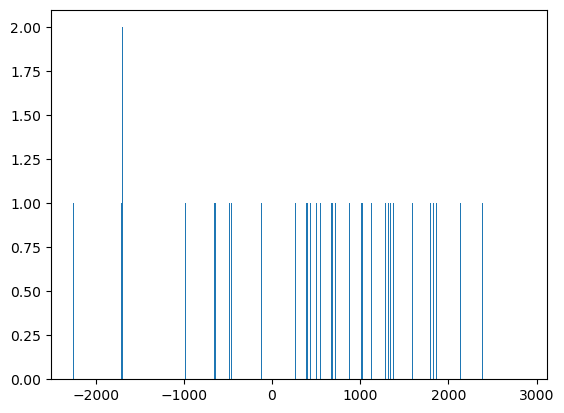

ztf_20221020297847_000449_zr_c09_x_0016.


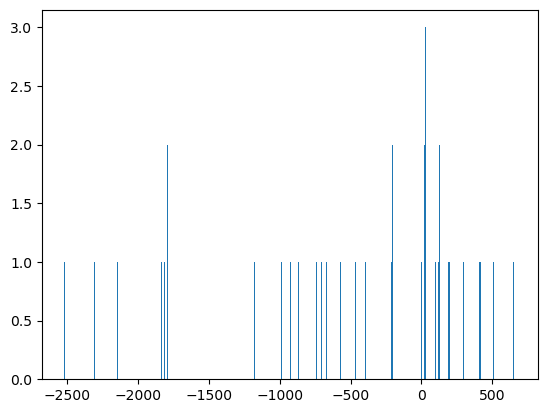

ztf_20221020154120_000640_zi_c11_x_0019.


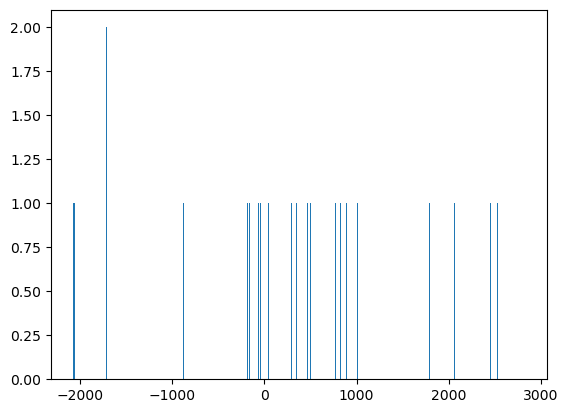

ztf_20221020297847_000449_zr_c03_x_0015.


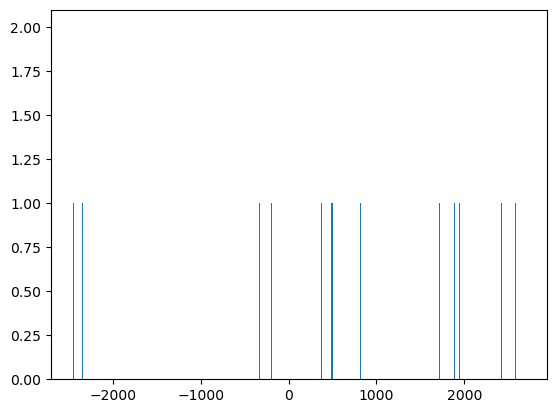

ztf_20221020297847_000449_zr_c03_x_0015.


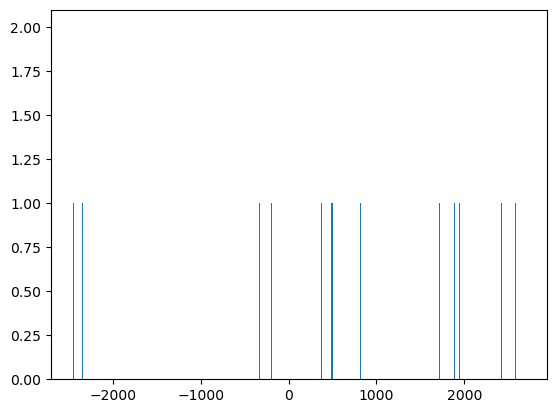

ztf_20221020148032_000686_zg_c03_x_0019.


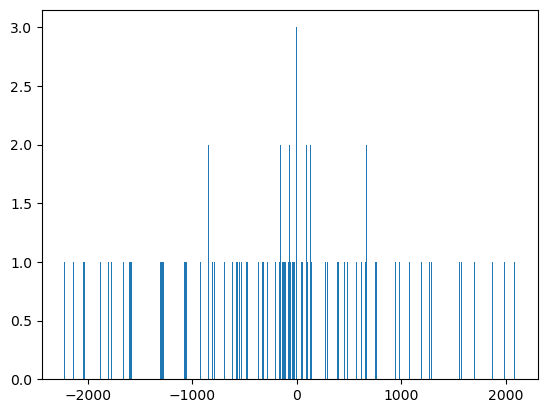

ztf_20221020154120_000640_zi_c11_x_0008.


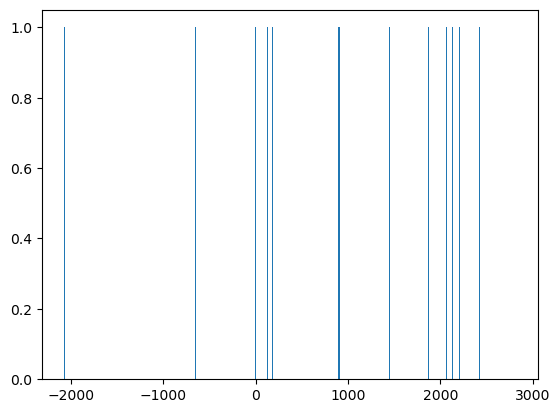

ztf_20221020297847_000449_zr_c03_x_0004.


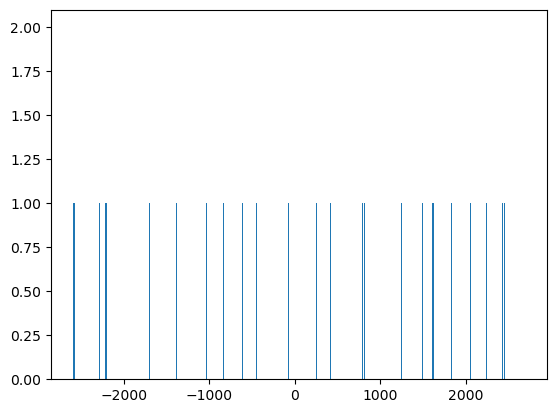

ztf_20221020138241_000686_zi_c02_x_0029.


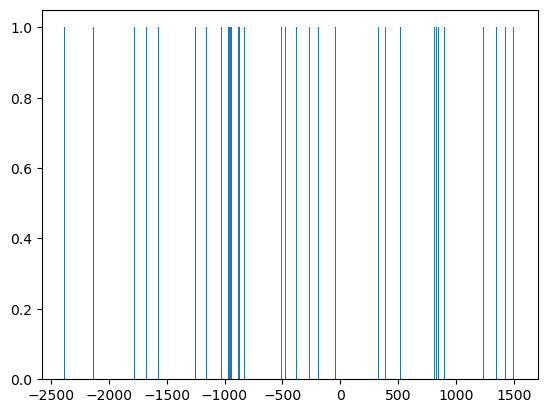

ztf_20221020138241_000686_zi_c02_x_0029.


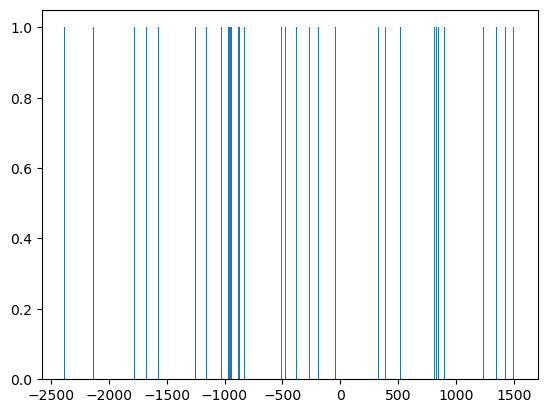

ztf_20221020163819_000640_zg_c07_x_0000.


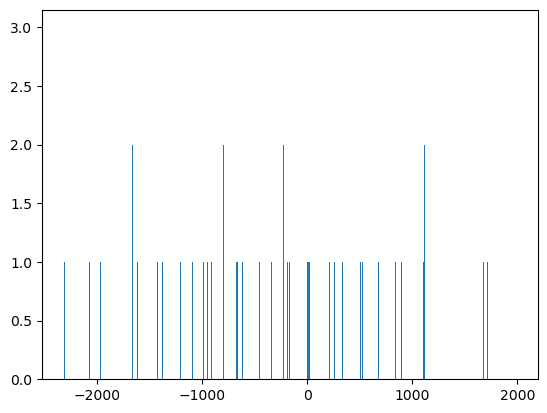

ztf_20221020148032_000686_zg_c01_x_0018.


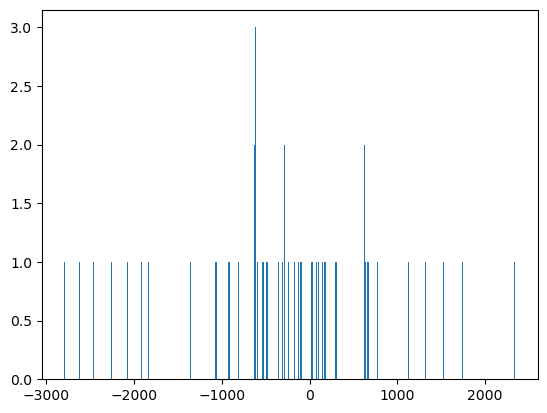

ztf_20221020297847_000449_zr_c14_x_0015.


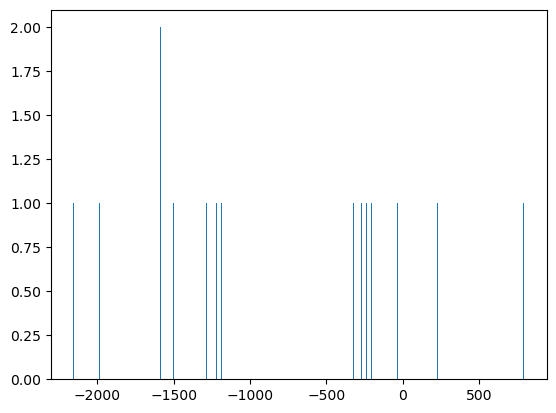

ztf_20221020163819_000640_zg_c06_x_0025.


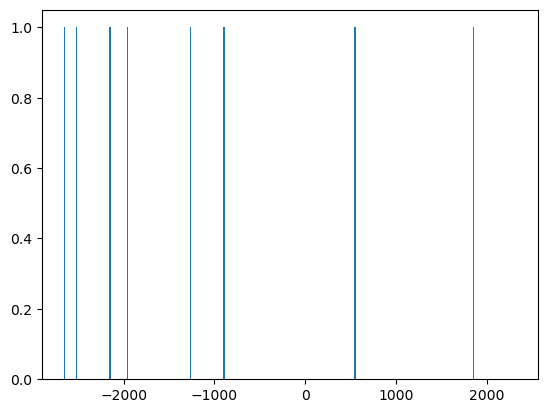

ztf_20221020138241_000686_zi_c08_x_0001.


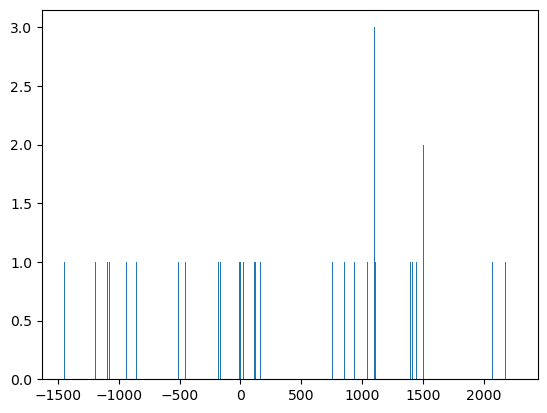

ztf_20221020297847_000449_zr_c14_x_0019.


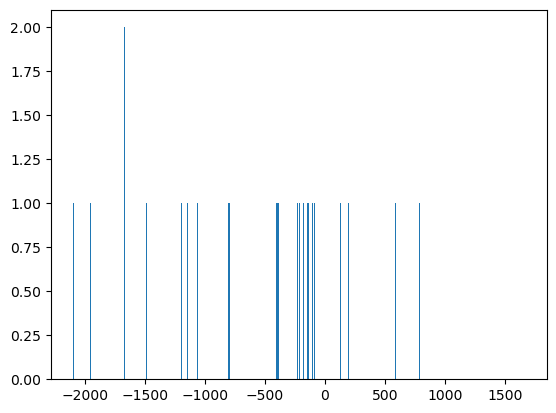

ztf_20221020148032_000686_zg_c07_x_0016.


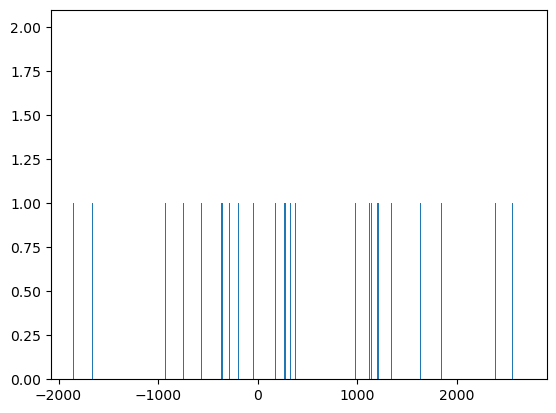

ztf_20221020148032_000686_zg_c03_x_0004.


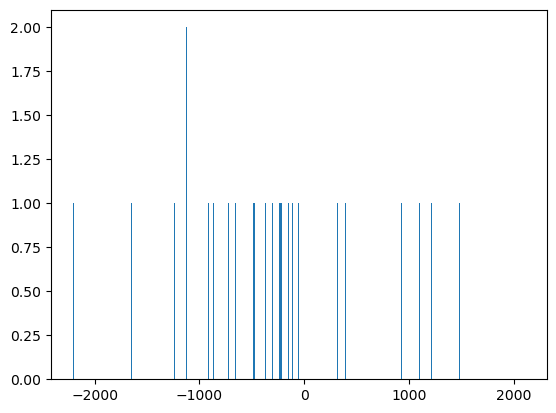

ztf_20221020148032_000686_zg_c03_x_0023.


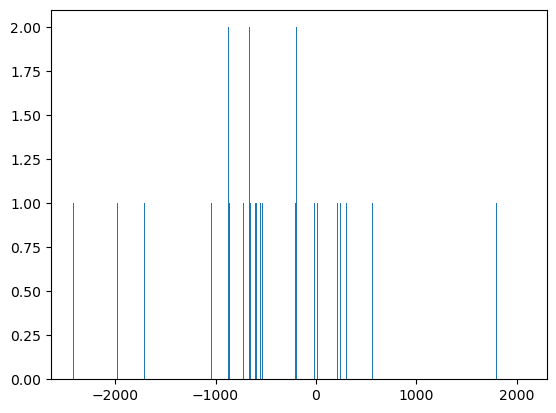

ztf_20221020297847_000449_zr_c15_x_0013.


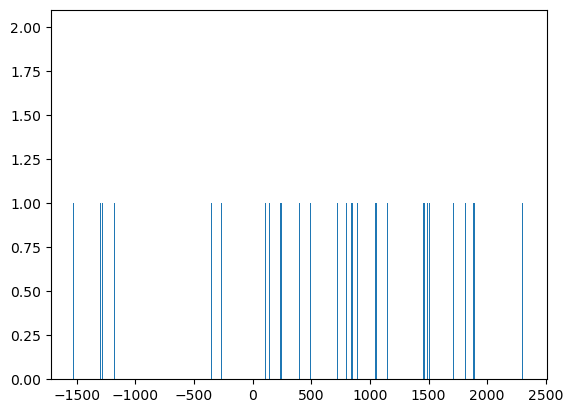

ztf_20221020148032_000686_zg_c16_x_0014.


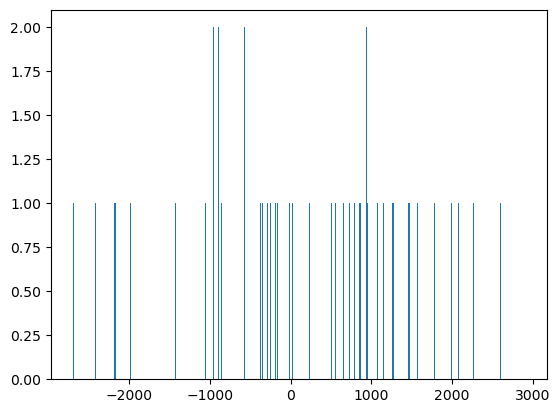

ztf_20221020154120_000640_zi_c11_x_0004.


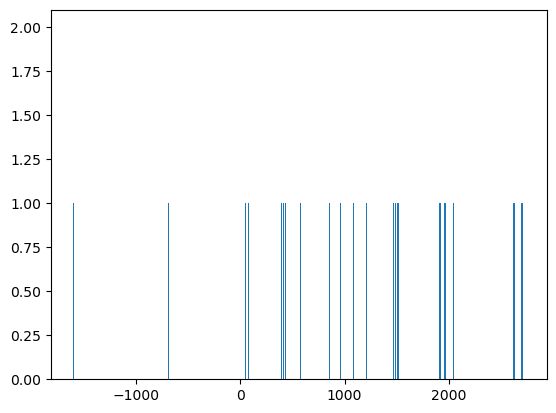

ztf_20221020154120_000640_zi_c11_x_0004.


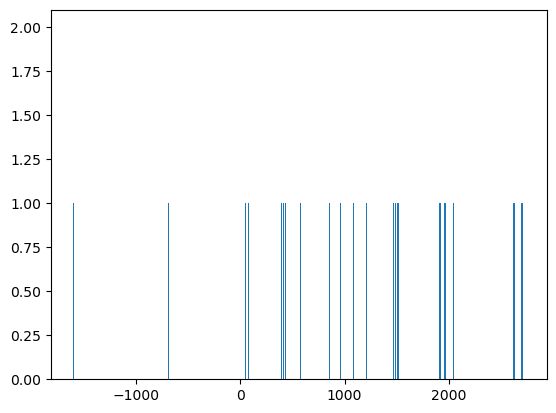

ztf_20221020148032_000686_zg_c03_x_0008.


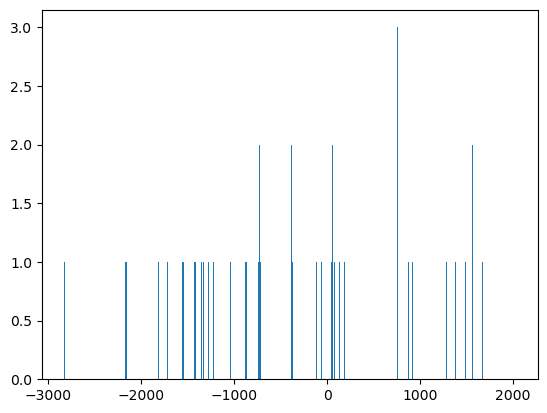

ztf_20221020138241_000686_zi_c16_x_0010.


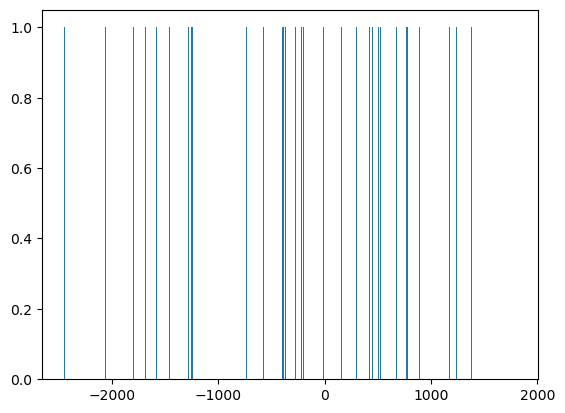

ztf_20221020154120_000640_zi_c11_x_0015.


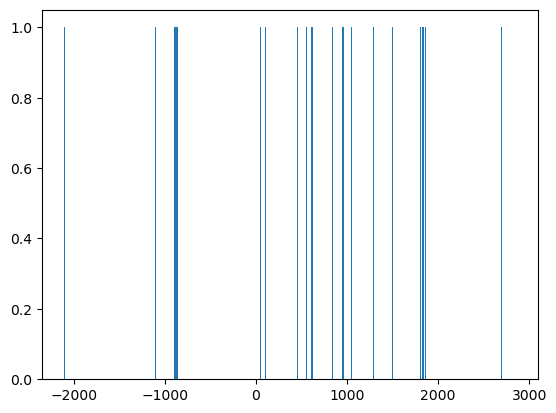

ztf_20221020154120_000640_zi_c11_x_0015.


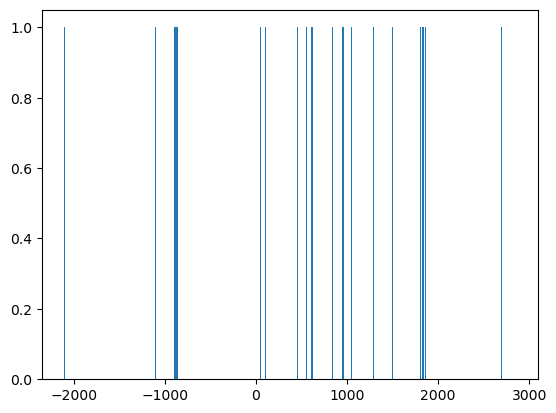

ztf_20221020141806_000686_zi_c16_x_0028.


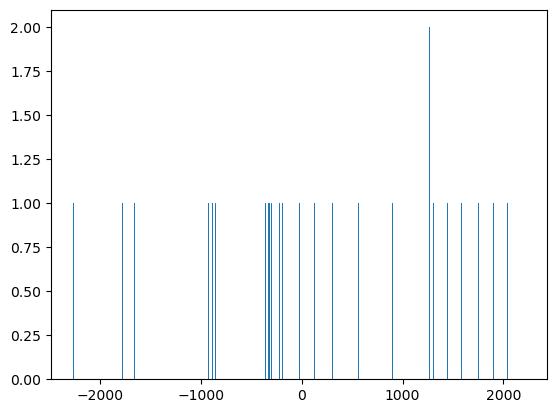

ztf_20221020148032_000686_zg_c12_x_0017.


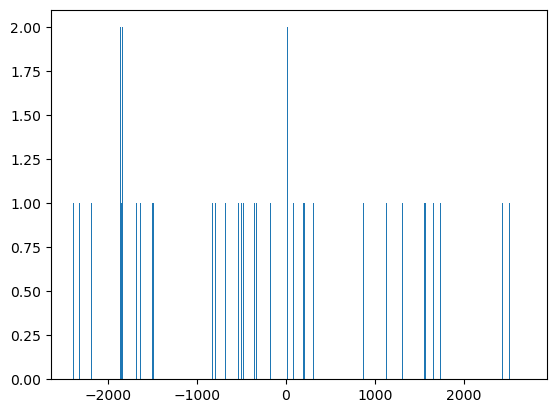

ztf_20221020148032_000686_zg_c03_x_0011.


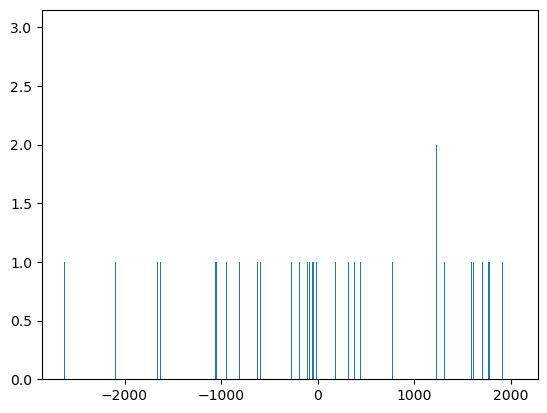

ztf_20221020163819_000640_zg_c04_x_0007.


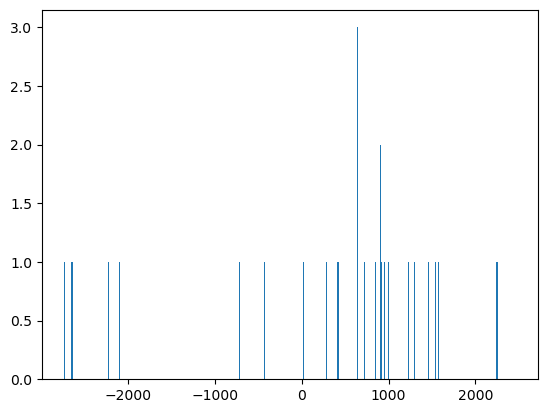

ztf_20221020138241_000686_zi_c14_x_0018.


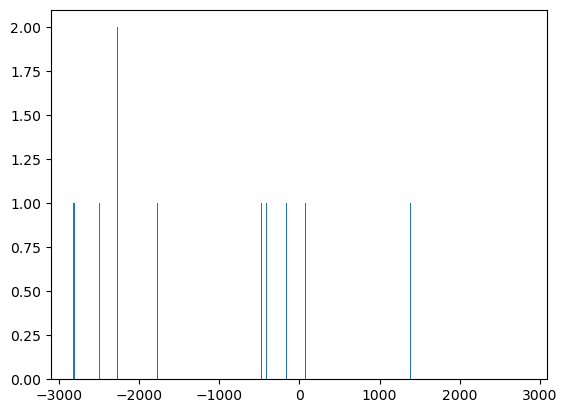

ztf_20221020163819_000640_zg_c04_x_0016.


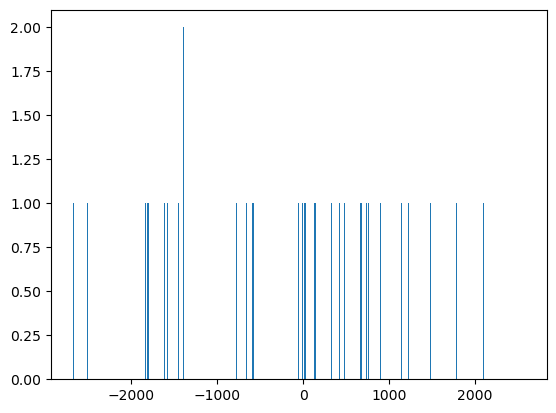

ztf_20221020163819_000640_zg_c04_x_0016.


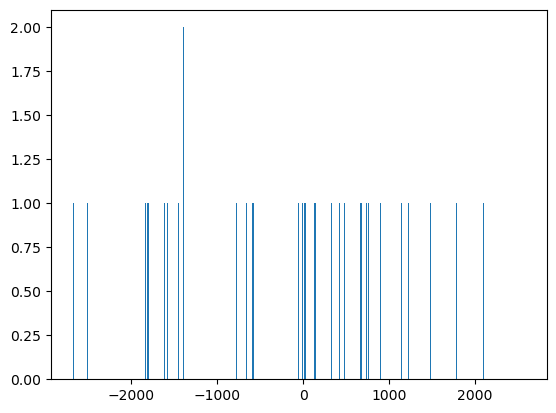

ztf_20221020154120_000640_zi_c11_x_0011.


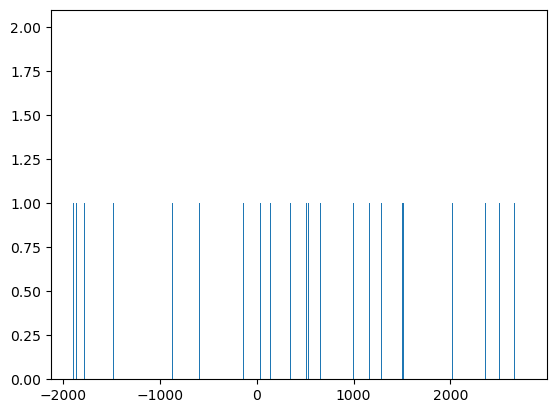

ztf_20221020297847_000449_zr_c11_x_0001.


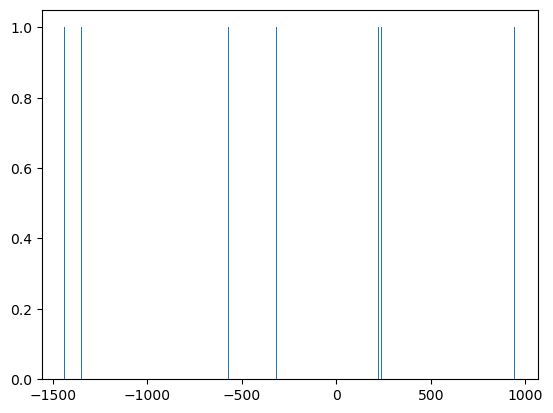

ztf_20221020294271_000449_zr_c14_x_0006.


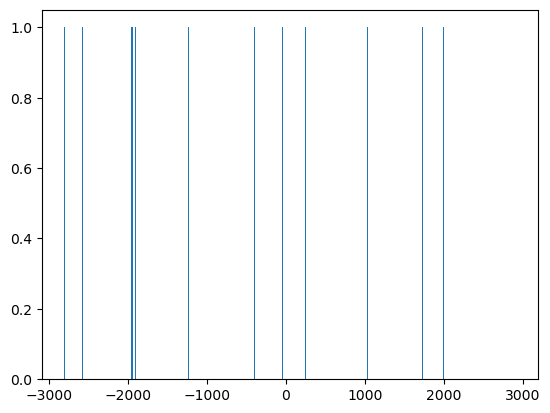

ztf_20221020294271_000449_zr_c14_x_0006.


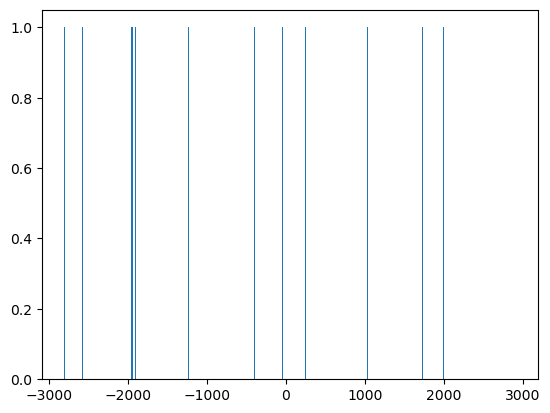

ztf_20221020157697_000640_zi_c11_x_0004.


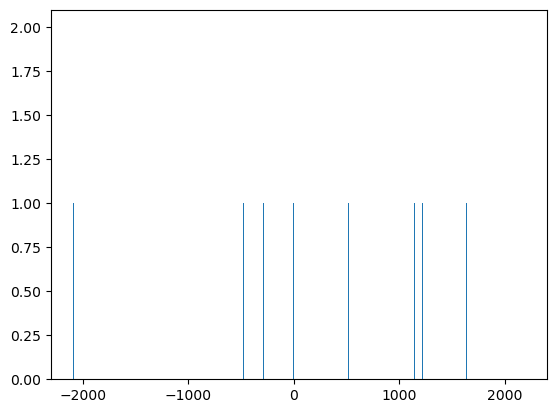

In [66]:
num_simultaneous_15_snr5 = []
for i, row in our_cands.iterrows():
    same_file_df = df_last[df_last['filename']==row['filename']]
    print(row['filename'])
    binwidth = 5
    data = same_file_df['distance_from_start']
    n, bins, third_thing = plt.hist(data, bins=np.arange(min(data), max(data) + binwidth, binwidth))
    np.sum(n>1)
    num_simultaneous_5.append(np.sum(n>1))
    plt.show()

In [67]:
our_cands['num_simultaneous_within_5'] = num_simultaneous_5

/tmp/ipykernel_11928/101760712.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_within_5'] = num_simultaneous_5


(array([3.000e+00, 2.000e+00, 6.000e+00, 3.000e+00, 7.000e+00, 1.500e+01,
        3.400e+01, 9.400e+01, 2.360e+02, 7.520e+02, 2.817e+03, 5.886e+03,
        5.252e+03, 5.281e+03, 5.866e+03, 6.083e+03, 5.146e+03, 3.865e+03,
        3.536e+03, 3.801e+03, 1.834e+03, 4.330e+02, 1.000e+02, 2.000e+01,
        7.000e+00, 3.000e+00, 1.000e+00, 3.000e+00, 4.000e+00, 3.000e+00]),
 array([-11.60055736, -10.8509827 , -10.10140804,  -9.35183337,
         -8.60225871,  -7.85268404,  -7.10310938,  -6.35353472,
         -5.60396005,  -4.85438539,  -4.10481073,  -3.35523606,
         -2.6056614 ,  -1.85608673,  -1.10651207,  -0.35693741,
          0.39263726,   1.14221192,   1.89178658,   2.64136125,
          3.39093591,   4.14051058,   4.89008524,   5.6396599 ,
          6.38923457,   7.13880923,   7.88838389,   8.63795856,
          9.38753322,  10.13710789,  10.88668255]),
 <BarContainer object of 30 artists>)

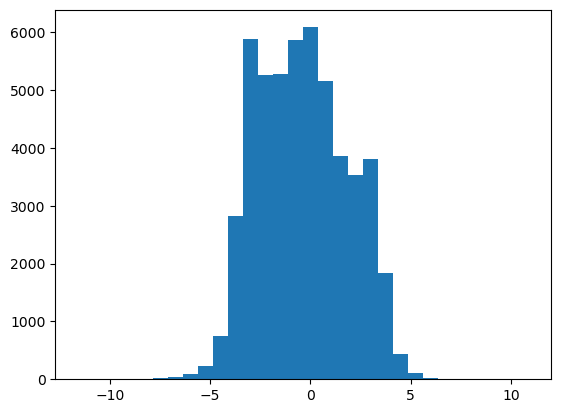

In [74]:
plt.hist(df_last['snr_center'], bins=30)

In [71]:
same_file_df[same_file_df['snr_center']>.1]

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,in_vari_summary,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,distance_from_start
24101,24101,24101,24101,293378,8,8,364,364,ztf_20221020157697_000640_zi_c11_x_0004.,pos,...,False,0.144834,0.140938,538.218272,553.096366,25584.656465,1839.333770,6.0,77.952291,-1541.250000
24105,24105,24105,24105,293421,51,51,515,515,ztf_20221020157697_000640_zi_c11_x_0004.,neg,...,False,0.071960,0.065512,503.939951,553.536885,25910.549512,410.991504,5.0,36.263501,-476.500000
24108,24108,24108,24108,293467,97,97,602,602,ztf_20221020157697_000640_zi_c11_x_0004.,neg,...,False,0.072788,0.061459,467.908763,554.162772,25905.086998,690.825279,4.0,34.058032,-2090.142857
49027,49027,49027,49027,585760,5,5,22,22,ztf_20221020157697_000640_zi_c11_x_0004.,neg,...,False,0.241865,0.199709,110.408408,133.713906,1797.752797,399.536611,4.0,26.703884,2182.700000
49028,49028,49028,49028,585771,16,16,46,46,ztf_20221020157697_000640_zi_c11_x_0004.,neg,...,False,0.059955,0.058310,130.396786,134.076959,1813.451870,138.856235,2.0,7.817975,1637.500000
49032,49032,49032,49032,585788,33,33,109,109,ztf_20221020157697_000640_zi_c11_x_0004.,neg,...,False,0.055374,0.043582,105.010930,133.422555,1778.743621,342.274382,2.0,5.814862,-5.000000


In [85]:
df_last = df_last[df_last['snr_center']>.5]

In [86]:
df_last

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,in_vari_summary,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,distance_from_start
0,0,0,0,1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,...,False,0.561214,0.467633,30.341491,36.413309,943.401942,86.507360,5.0,17.028074,1543.375000
1,1,1,1,3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,...,False,0.620627,0.620049,36.286720,36.320508,943.886565,107.039582,7.0,22.520506,-144.333333
3,3,3,3,24,0,0,3,3,ztf_20221020163819_000640_zg_c01_x_0021.,pos,...,False,0.187912,0.140407,323.398782,432.817956,18434.581445,990.461523,6.0,60.770618,2177.272727
6,6,6,6,45,21,21,236,236,ztf_20221020163819_000640_zg_c01_x_0021.,neg,...,False,0.118735,0.092966,339.158774,433.168678,18395.381172,847.777031,4.0,40.269948,2169.000000
13,13,13,13,148,124,124,377,377,ztf_20221020163819_000640_zg_c01_x_0021.,neg,...,False,0.047311,0.042632,389.203013,431.915787,18410.510273,626.519023,2.0,18.413410,-266.095238
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51081,51081,51081,51081,610647,12,12,37,37,ztf_20221020297847_000449_zr_c14_x_0026.,pos,...,NaN,0.291710,0.285577,186.477537,190.482157,4149.851165,536.219636,8.0,54.397299,-404.857143
51082,51082,51082,51082,610673,38,38,100,100,ztf_20221020297847_000449_zr_c14_x_0026.,pos,...,False,0.191221,0.179424,46.610557,49.675160,1271.899304,85.511829,2.0,8.912914,-1163.076923
51087,51087,51087,51087,610702,67,67,166,166,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,NaN,0.229025,0.120038,100.343446,191.448528,4235.181825,188.399230,5.0,22.981128,-166.166667
51088,51088,51088,51088,610705,70,70,171,171,ztf_20221020297847_000449_zr_c14_x_0026.,neg,...,NaN,0.060841,0.042777,134.400807,191.155077,4215.145792,139.619344,2.0,8.177057,-281.000000


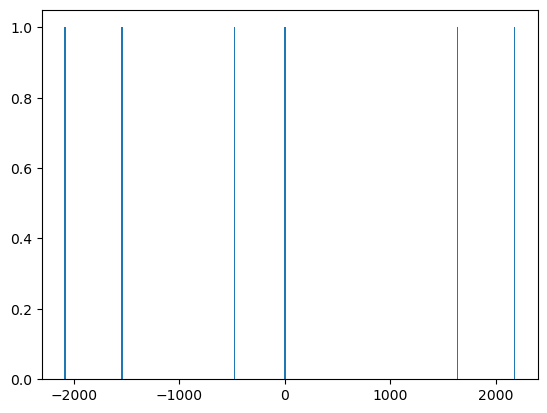

In [42]:
n, bins, third_thing = plt.hist(data, bins=np.arange(min(data), max(data) + binwidth, binwidth))

In [47]:
n

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0.

ztf_20221020297847_000449_zr_c01_x_0008.


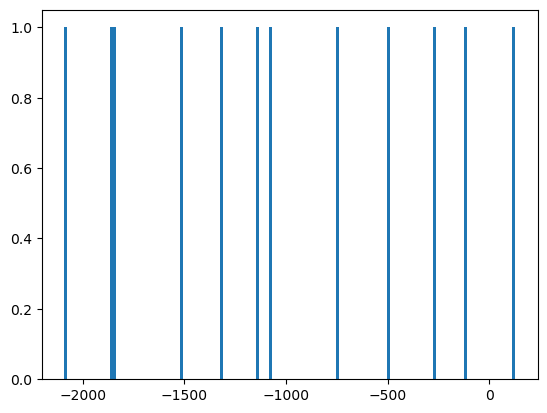

ztf_20221020148032_000686_zg_c16_x_0005.


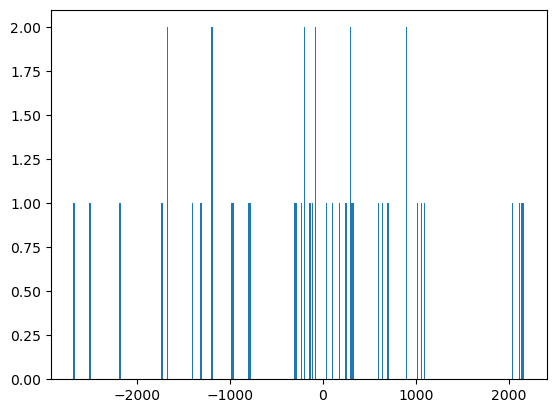

ztf_20221020163819_000640_zg_c16_x_0025.


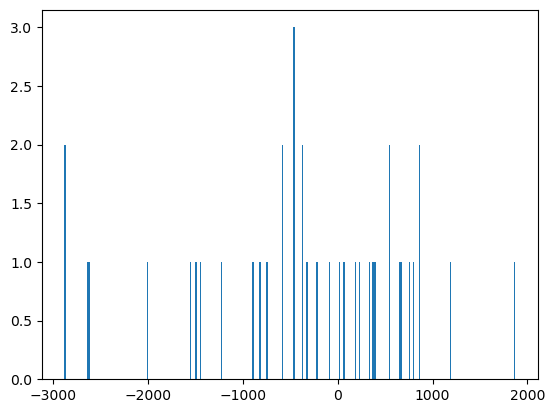

ztf_20221020163819_000640_zg_c16_x_0025.


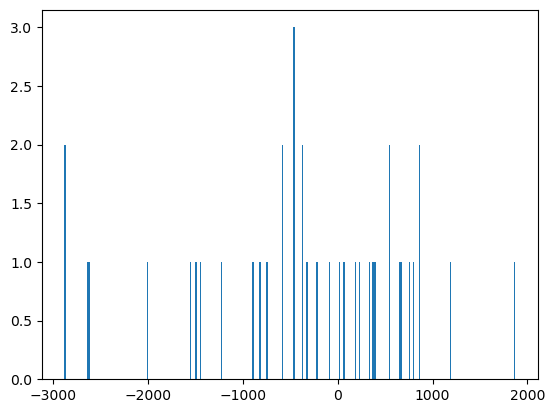

ztf_20221020148032_000686_zg_c05_x_0006.


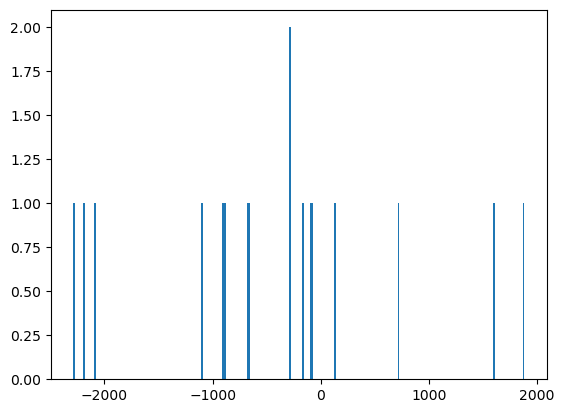

ztf_20221020148032_000686_zg_c16_x_0014.


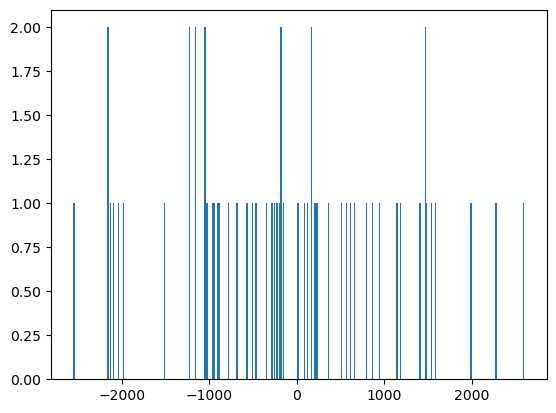

ztf_20221020154120_000640_zi_c04_x_0018.


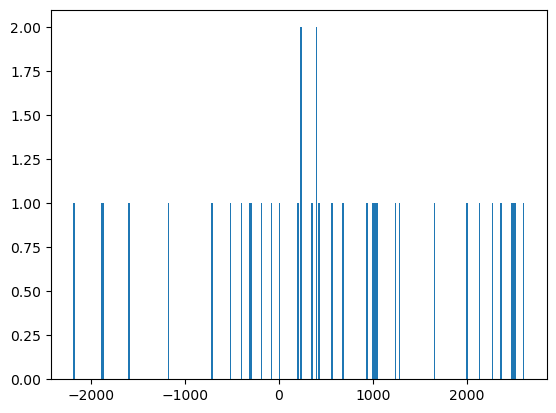

ztf_20221020294271_000449_zr_c09_x_0009.


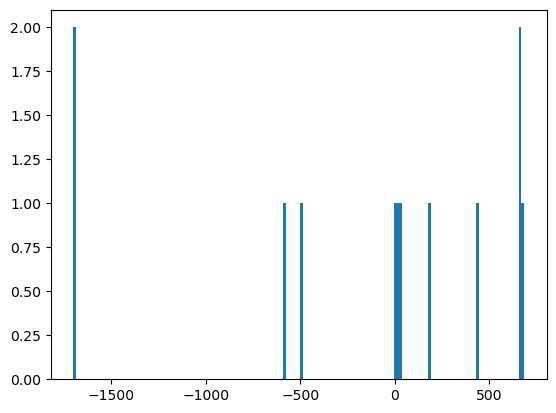

ztf_20221020157697_000640_zi_c04_x_0022.


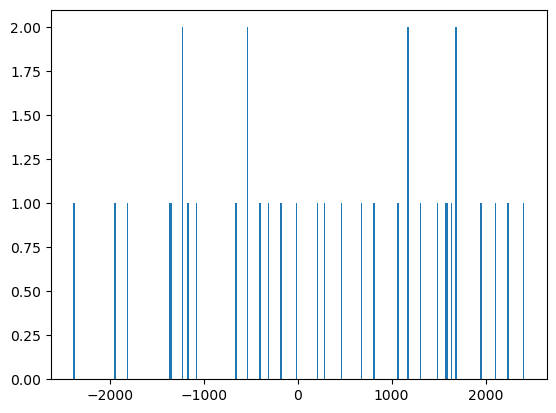

ztf_20221020157697_000640_zi_c04_x_0022.


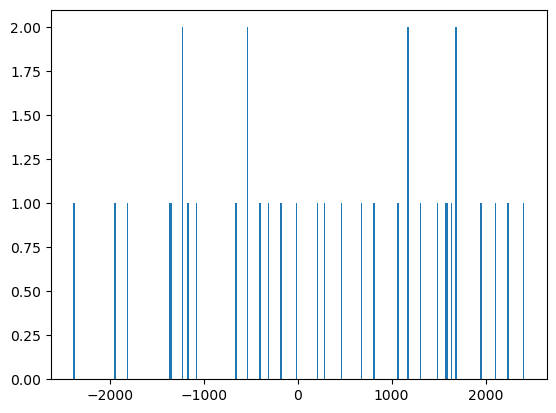

ztf_20221020294271_000449_zr_c14_x_0017.


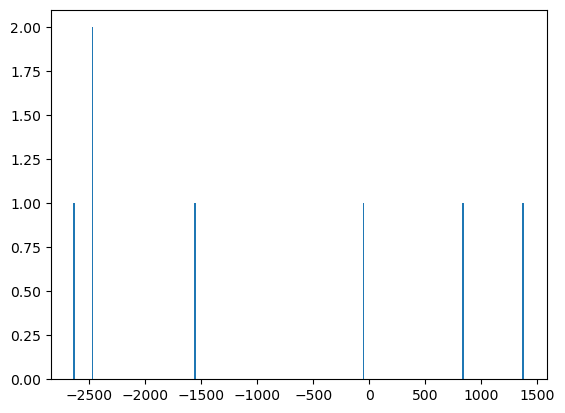

ztf_20221020141806_000686_zi_c14_x_0013.


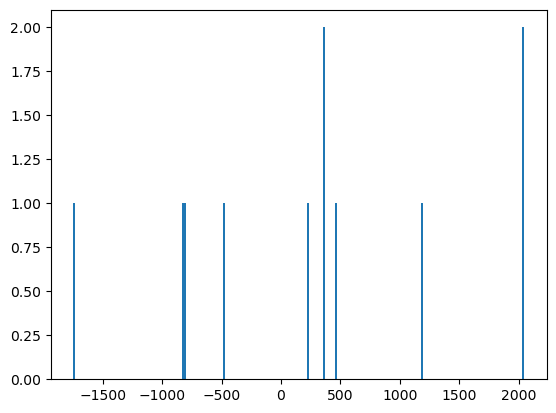

ztf_20221020294271_000449_zr_c09_x_0011.


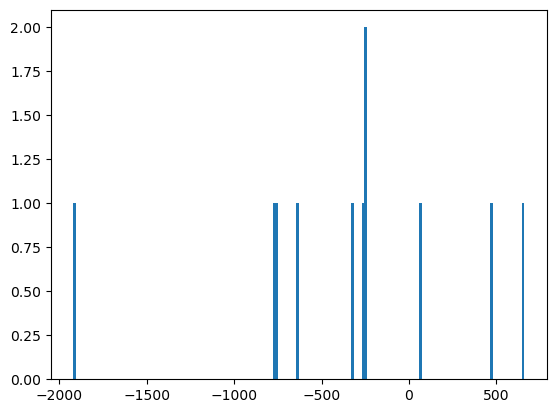

ztf_20221020148032_000686_zg_c11_x_0026.


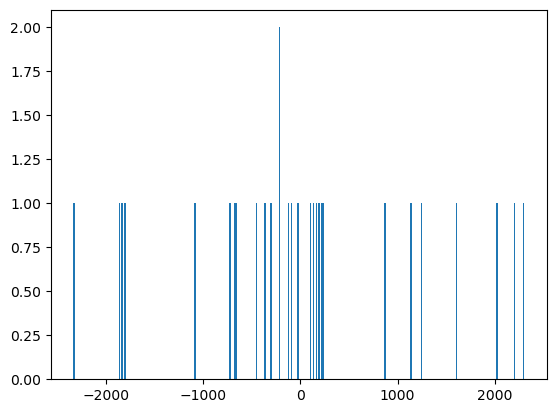

ztf_20221020294271_000449_zr_c09_x_0018.


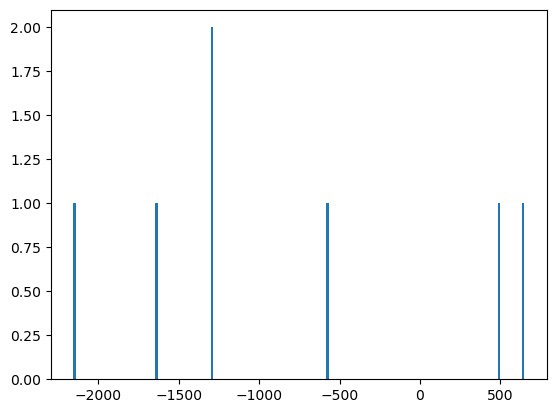

ztf_20221020148032_000686_zg_c16_x_0010.


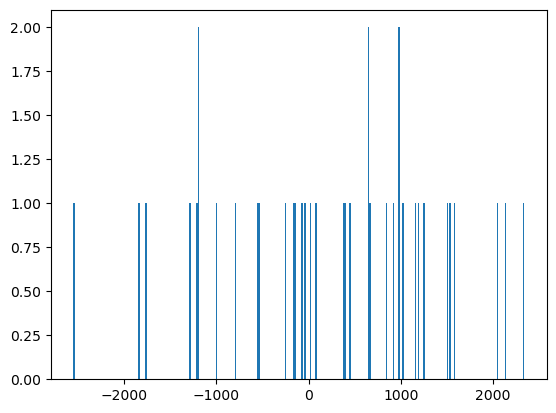

ztf_20221020154120_000640_zi_c13_x_0018.


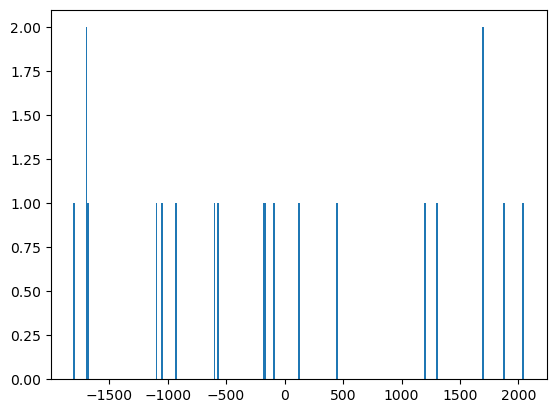

ztf_20221020297847_000449_zr_c09_x_0012.


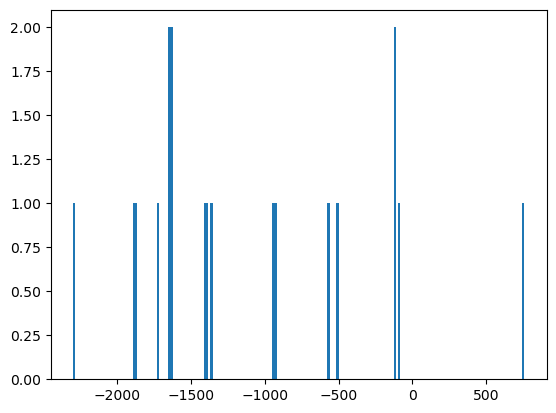

ztf_20221020154120_000640_zi_c08_x_0014.


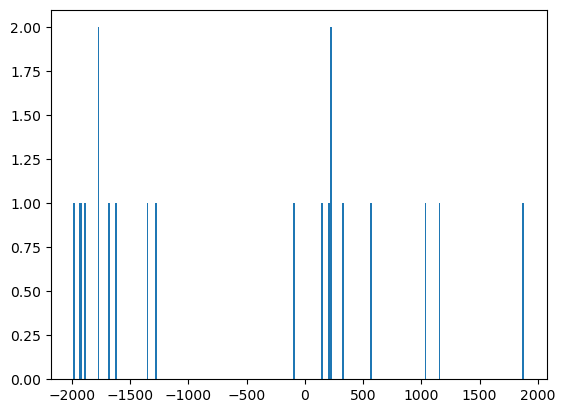

ztf_20221020154120_000640_zi_c08_x_0014.


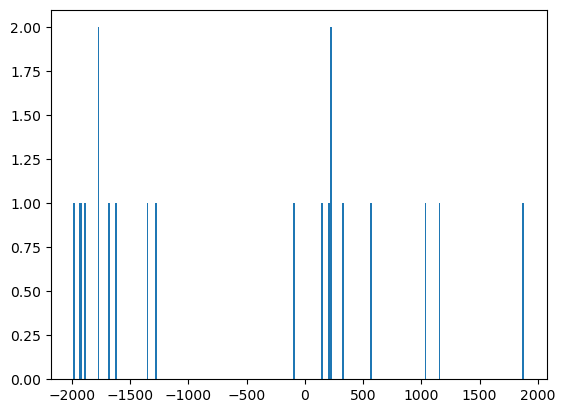

ztf_20221020154120_000640_zi_c08_x_0014.


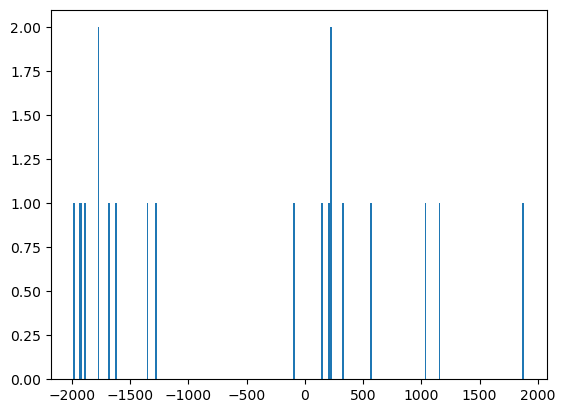

ztf_20221020138241_000686_zi_c08_x_0000.


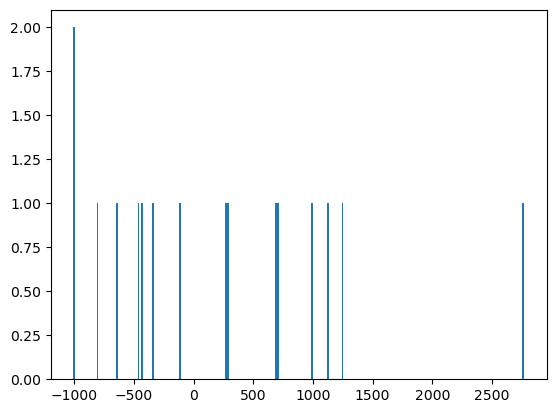

ztf_20221020157697_000640_zi_c16_x_0005.


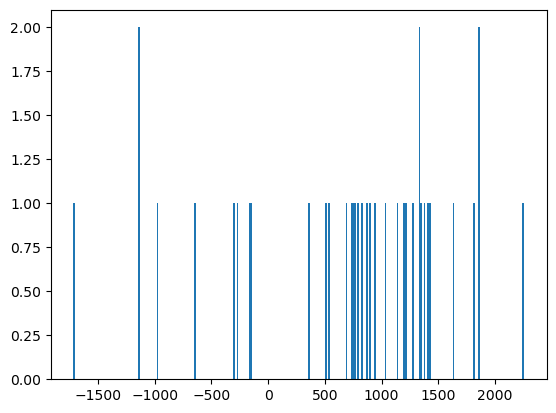

ztf_20221020163819_000640_zg_c10_x_0011.


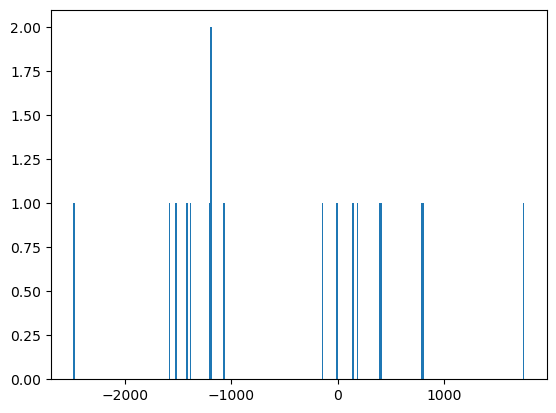

ztf_20221020297847_000449_zr_c14_x_0019.


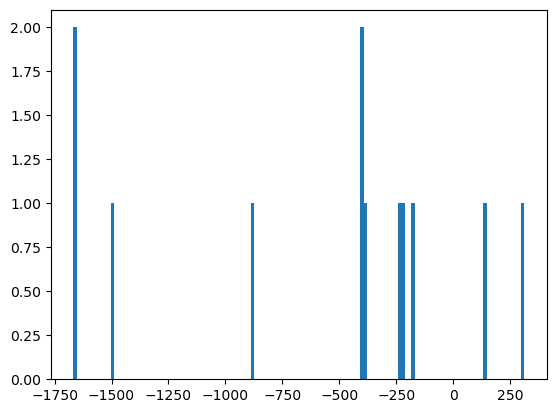

ztf_20221020294271_000449_zr_c12_x_0023.


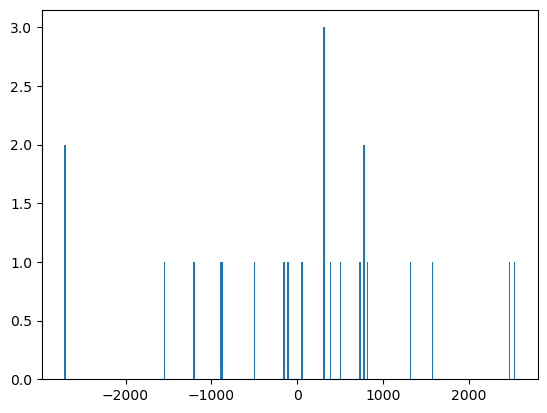

ztf_20221020148032_000686_zg_c09_x_0007.


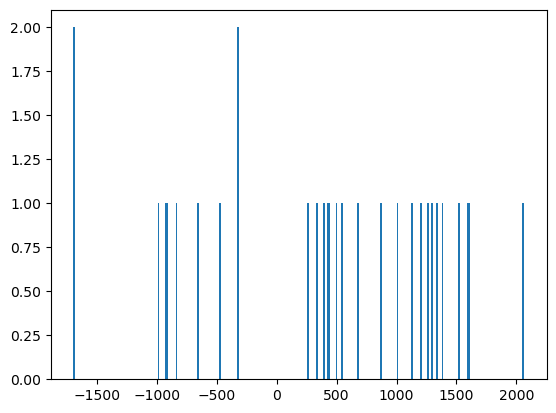

ztf_20221020297847_000449_zr_c09_x_0016.


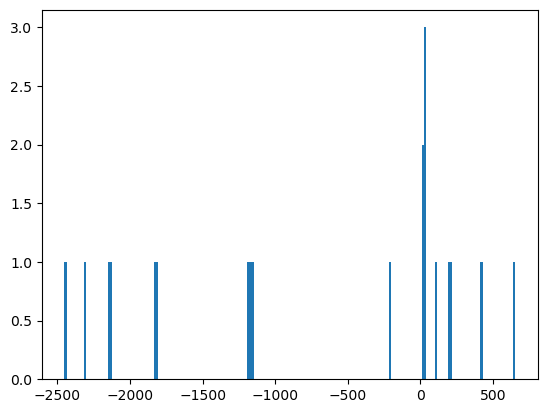

ztf_20221020154120_000640_zi_c11_x_0019.


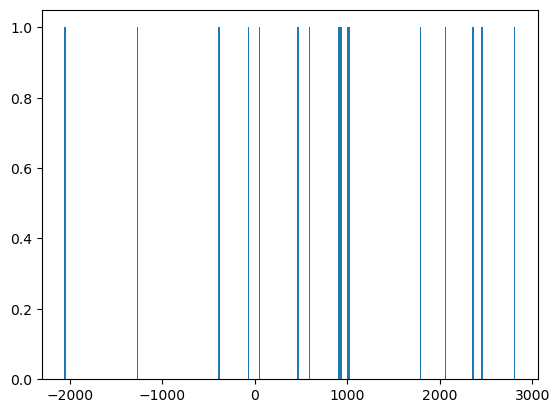

ztf_20221020297847_000449_zr_c03_x_0015.


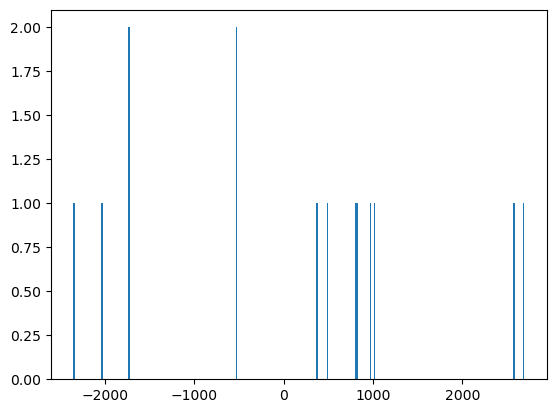

ztf_20221020297847_000449_zr_c03_x_0015.


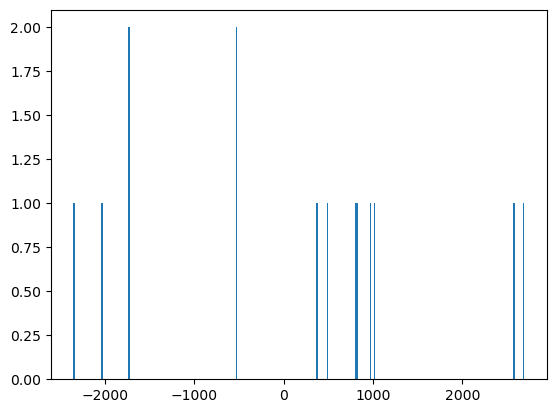

ztf_20221020148032_000686_zg_c03_x_0019.


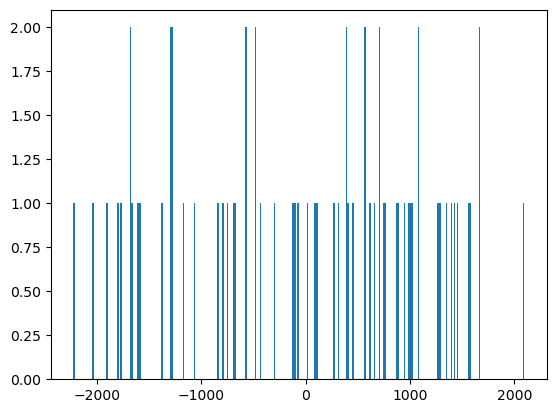

ztf_20221020154120_000640_zi_c11_x_0008.


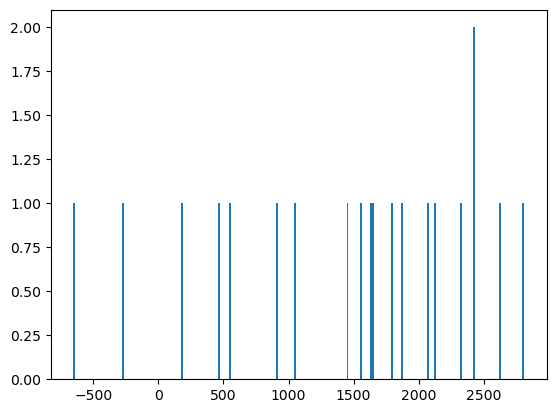

ztf_20221020297847_000449_zr_c03_x_0004.


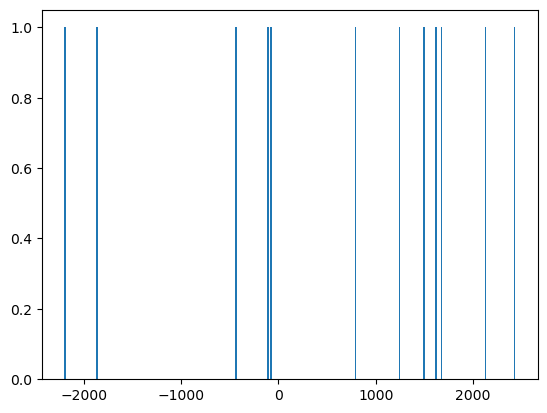

ztf_20221020138241_000686_zi_c02_x_0029.


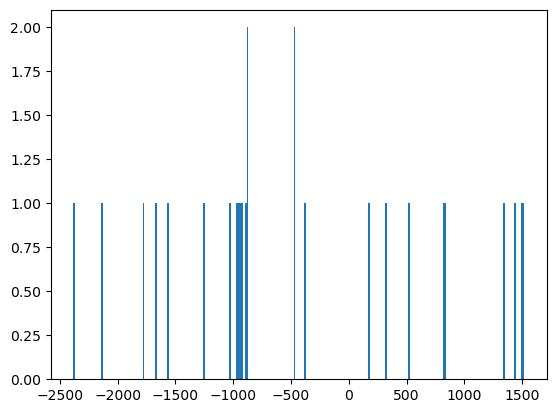

ztf_20221020138241_000686_zi_c02_x_0029.


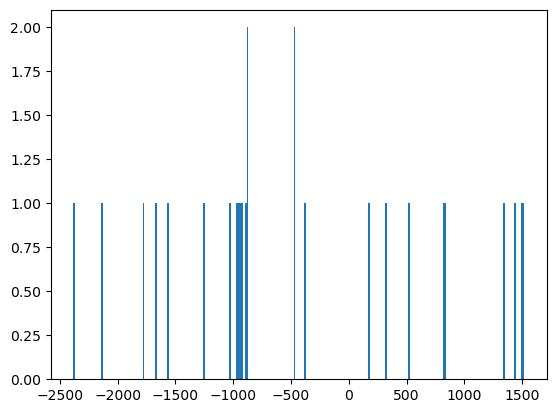

ztf_20221020163819_000640_zg_c07_x_0000.


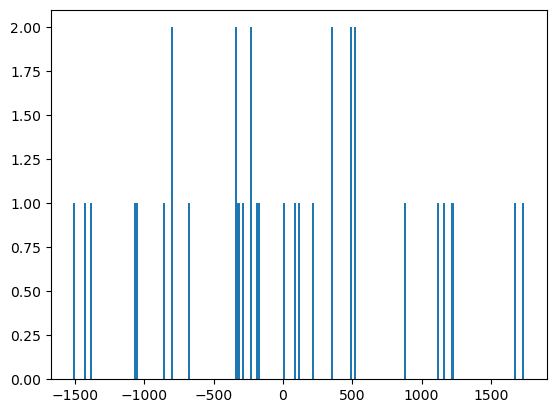

ztf_20221020148032_000686_zg_c01_x_0018.


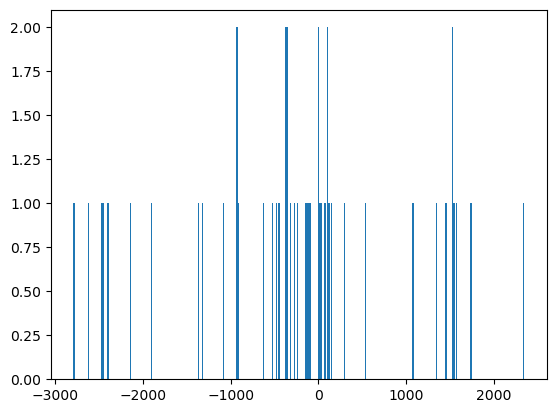

ztf_20221020297847_000449_zr_c14_x_0015.


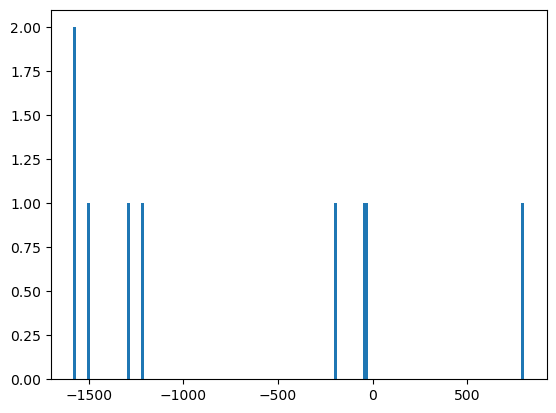

ztf_20221020163819_000640_zg_c06_x_0025.


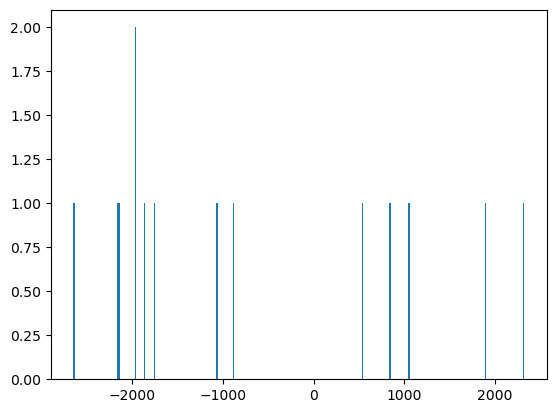

ztf_20221020138241_000686_zi_c08_x_0001.


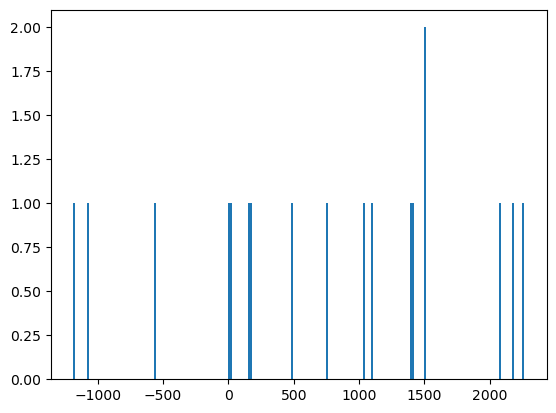

ztf_20221020297847_000449_zr_c14_x_0019.


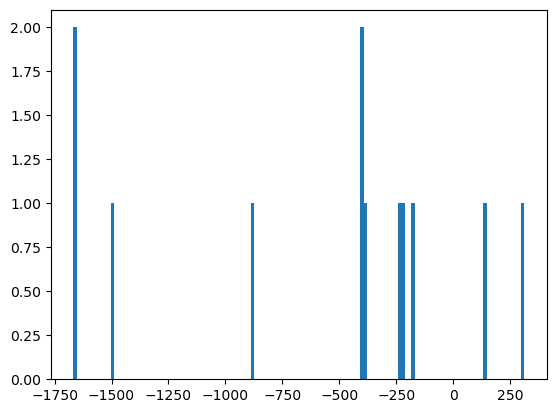

ztf_20221020148032_000686_zg_c07_x_0016.


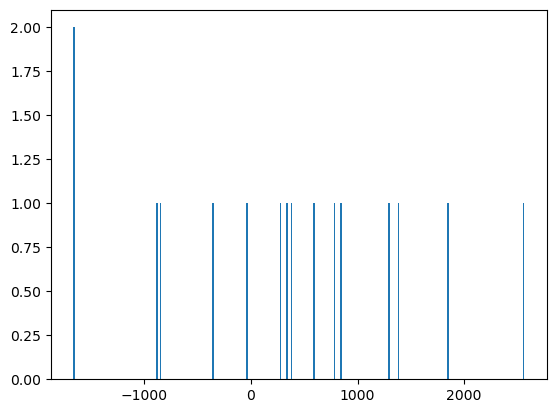

ztf_20221020148032_000686_zg_c03_x_0004.


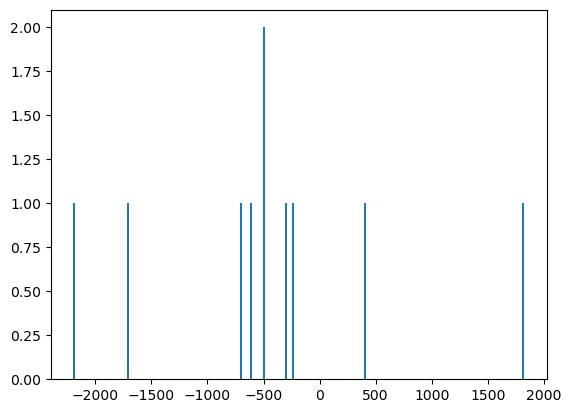

ztf_20221020148032_000686_zg_c03_x_0023.


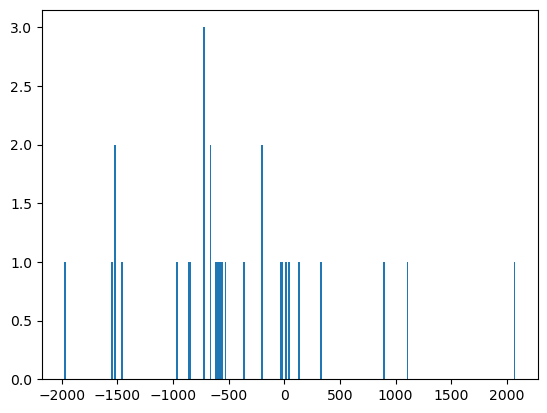

ztf_20221020297847_000449_zr_c15_x_0013.


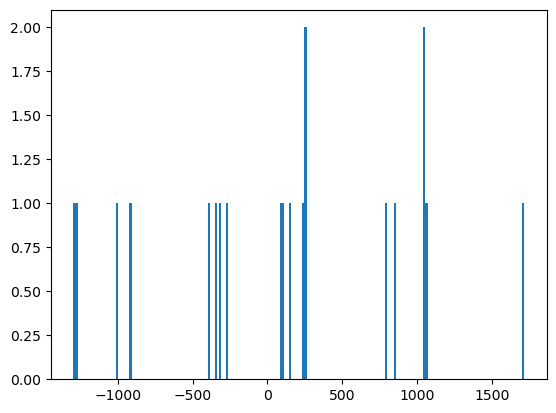

ztf_20221020148032_000686_zg_c16_x_0014.


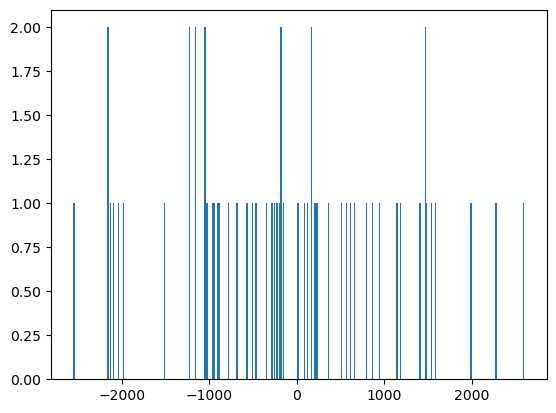

ztf_20221020154120_000640_zi_c11_x_0004.


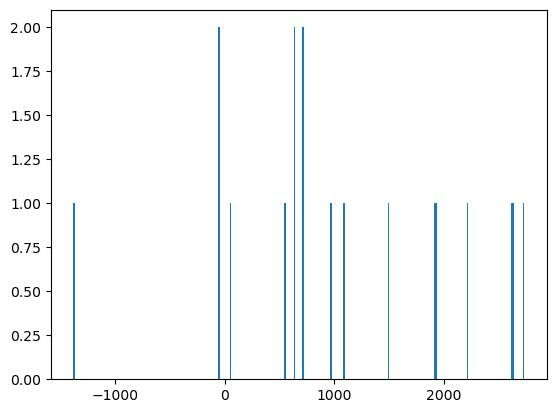

ztf_20221020154120_000640_zi_c11_x_0004.


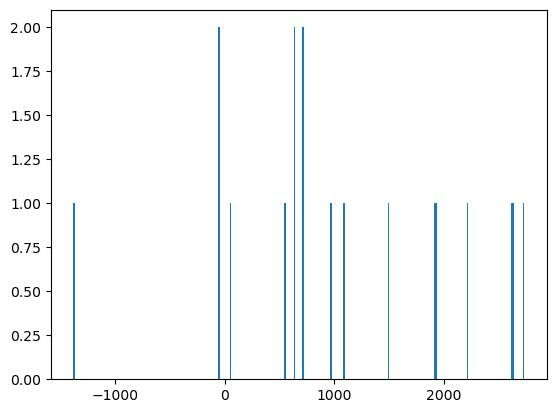

ztf_20221020148032_000686_zg_c03_x_0008.


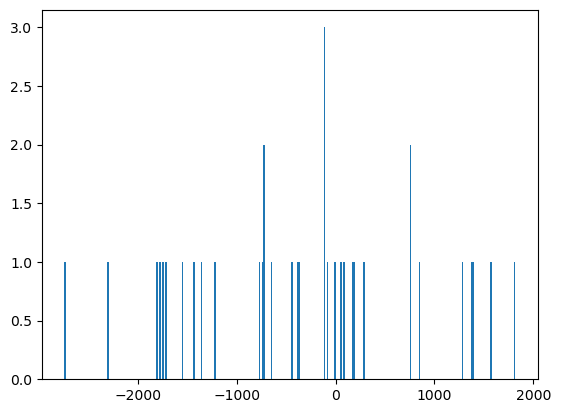

ztf_20221020138241_000686_zi_c16_x_0010.


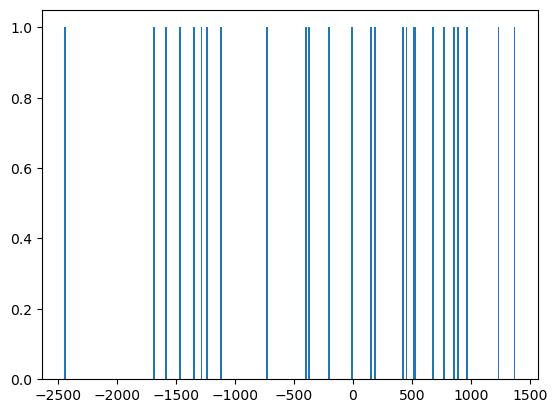

ztf_20221020154120_000640_zi_c11_x_0015.


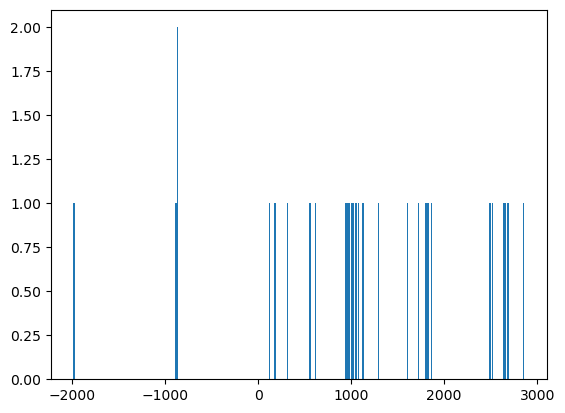

ztf_20221020154120_000640_zi_c11_x_0015.


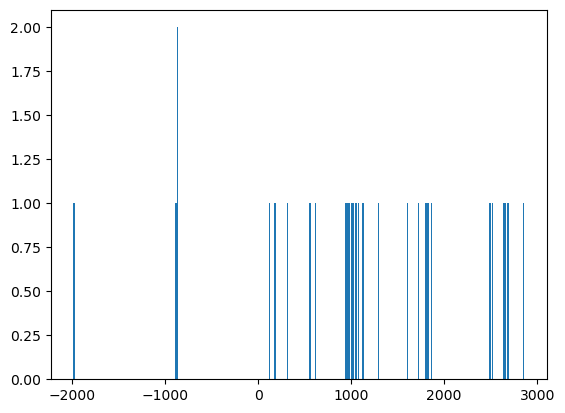

ztf_20221020141806_000686_zi_c16_x_0028.


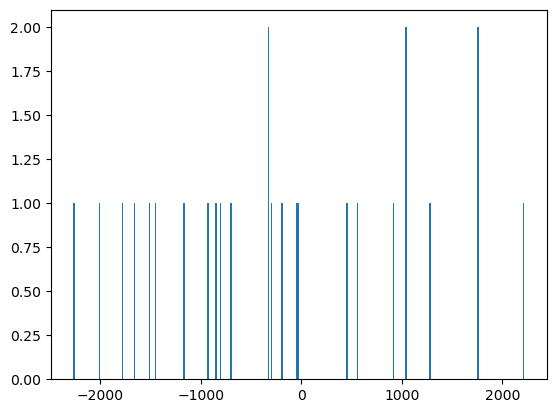

ztf_20221020148032_000686_zg_c12_x_0017.


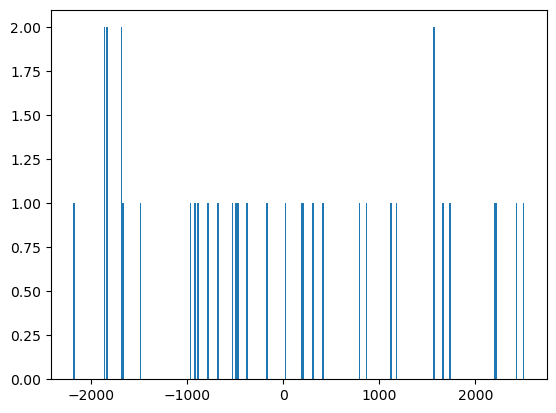

ztf_20221020148032_000686_zg_c03_x_0011.


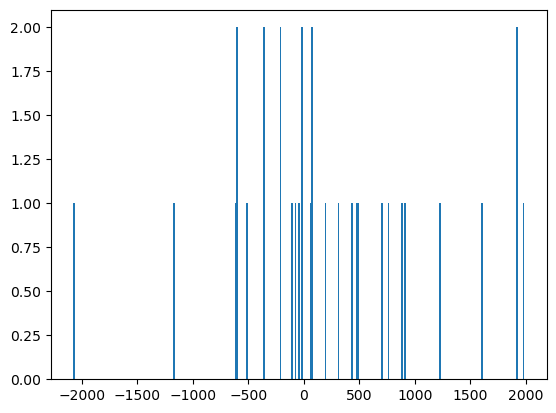

ztf_20221020163819_000640_zg_c04_x_0007.


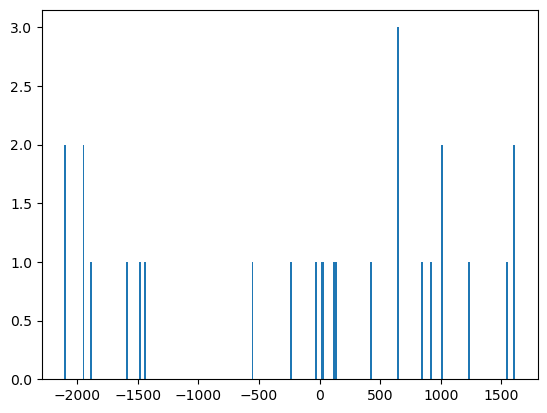

ztf_20221020138241_000686_zi_c14_x_0018.


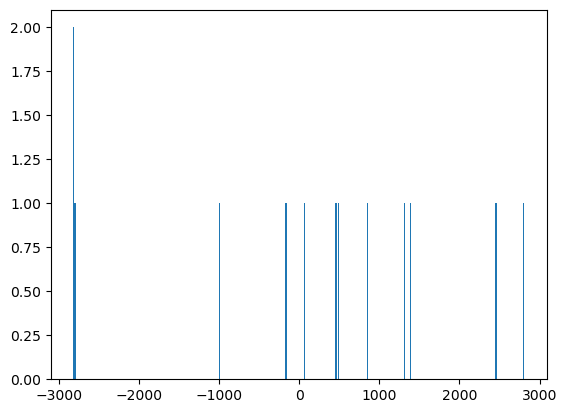

ztf_20221020163819_000640_zg_c04_x_0016.


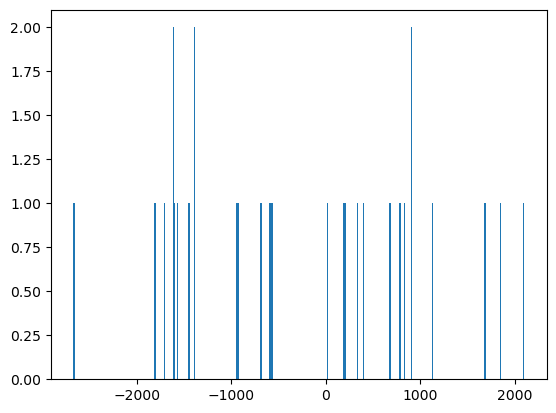

ztf_20221020163819_000640_zg_c04_x_0016.


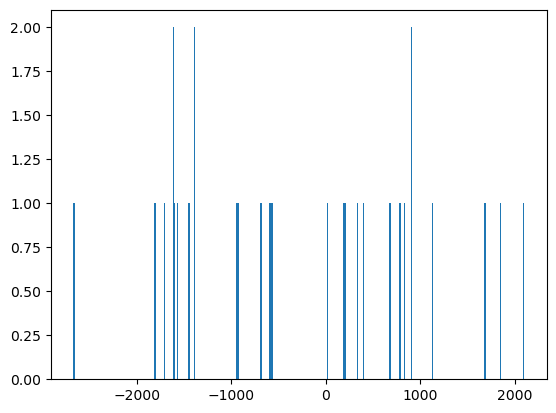

ztf_20221020154120_000640_zi_c11_x_0011.


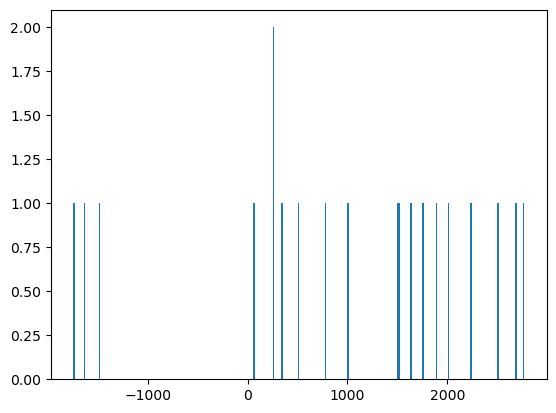

ztf_20221020297847_000449_zr_c11_x_0001.


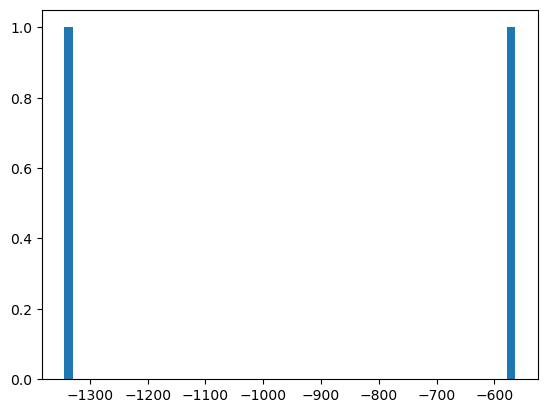

ztf_20221020294271_000449_zr_c14_x_0006.


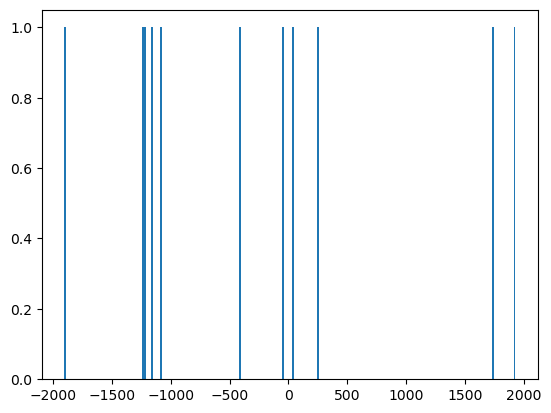

ztf_20221020294271_000449_zr_c14_x_0006.


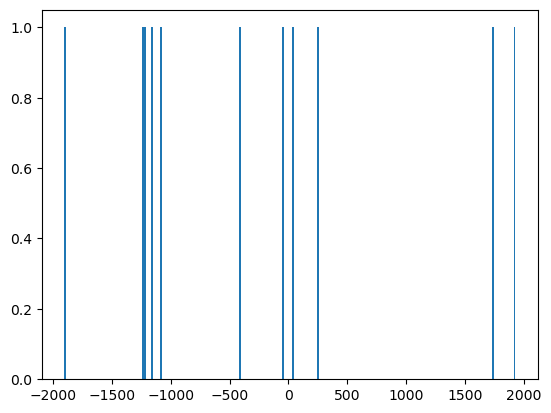

ztf_20221020157697_000640_zi_c11_x_0004.


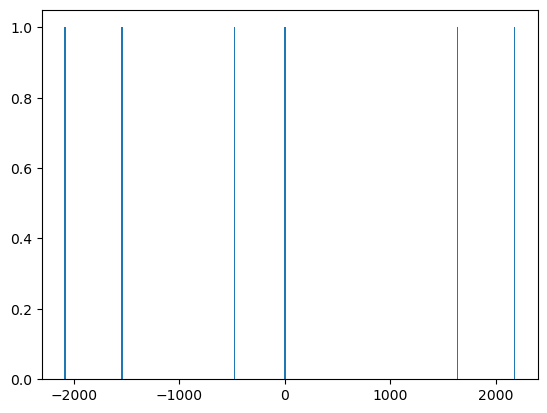

In [37]:
num_simultaneous_15_snr1 = []
df_last_ = df_last[df_last['snr_center']>.1]
for i, row in our_cands.iterrows():
    same_file_df = df_last_[df_last_['filename']==row['filename']]
    
    print(row['filename'])
    binwidth = 15
    data = same_file_df['distance_from_start']
    data = data[~data.isnull()]
    n, bins, third_thing = plt.hist(data, bins=np.arange(min(data), max(data) + binwidth, binwidth))
    np.sum(n>1)
    num_simultaneous_15_snr1.append(np.sum(n>1))
    plt.show()

In [38]:
our_cands['num_simultaneous_15_snr1'] = num_simultaneous_15_snr1

/tmp/ipykernel_393/1058693853.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_15_snr1'] = num_simultaneous_15_snr1


In [101]:
our_cands['num_simultaneous_15_snr1_fixed_crit'] = num_simultaneous_15_snr1_fixed_crit

/tmp/ipykernel_393/609488365.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  our_cands['num_simultaneous_15_snr1_fixed_crit'] = num_simultaneous_15_snr1_fixed_crit


Text(0, 0.5, 'how many candidates have that many simultaneous candidates')

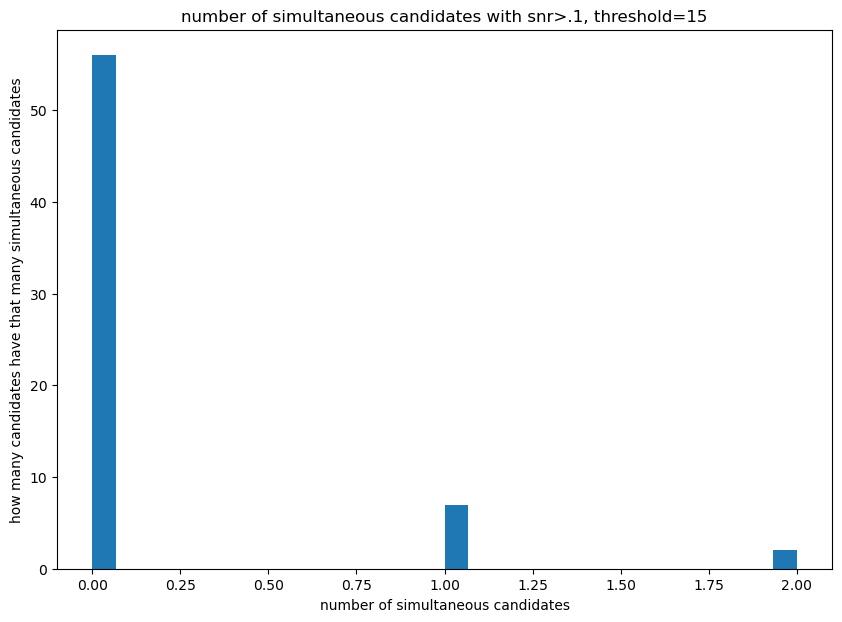

In [102]:
plt.hist(our_cands['num_simultaneous_15_snr1_fixed_crit'], bins=30)
plt.title("number of simultaneous candidates with snr>.1, threshold=15")
plt.xlabel("number of simultaneous candidates")
plt.ylabel("how many candidates have that many simultaneous candidates")

In [41]:
plt.hist(our_cands['num_simultaneous_15_snr2'], bins=30)
plt.title("number of simultaneous candidates with snr>.2, threshold=15")
plt.xlabel("number of simultaneous candidates")
plt.ylabel("how many candidates have that many simultaneous candidates")

KeyError: 'num_simultaneous_15_snr2'

In [ ]:
#okay so now we want to be able to actually see the simultaneous transients

In [49]:
data

24101   -1541.250000
24105    -476.500000
24108   -2090.142857
49027    2182.700000
49028    1637.500000
49032      -5.000000
Name: distance_from_start, dtype: float64

In [50]:
our_cands

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,distance_from_start,num_simultaneous_15_snr1
776,776,776,776,9074,2,2,11,11,ztf_20221020297847_000449_zr_c01_x_0008.,pos,...,1.110102,0.782343,22.590435,32.054603,766.986678,108.024735,9.0,25.077692,-1083.250000,0
1389,1389,1389,1389,16380,309,309,636,636,ztf_20221020148032_000686_zg_c16_x_0005.,neg,...,1.032185,0.910907,33.465428,37.921016,1151.866137,188.627551,10.0,34.542521,-879.363636,6
2018,2018,2018,2018,24274,2,2,23,23,ztf_20221020163819_000640_zg_c16_x_0025.,pos,...,1.249588,1.050896,23.332121,27.743484,790.377811,93.505917,12.0,29.155529,-573.142857,6
2022,2022,2022,2022,24294,22,22,79,79,ztf_20221020163819_000640_zg_c16_x_0025.,neg,...,1.217411,0.967004,29.931357,37.682118,1267.977484,135.349310,13.0,36.438755,1036.428571,6
3935,3935,3935,3935,47566,23,23,110,110,ztf_20221020148032_000686_zg_c05_x_0006.,neg,...,1.006164,0.869902,34.929113,40.400426,1422.732745,110.330402,14.0,35.144413,-2474.200000,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46783,46783,46783,46783,559047,76,76,151,151,ztf_20221020154120_000640_zi_c11_x_0011.,neg,...,1.068315,0.883177,69.766877,84.391967,1775.956407,375.179674,19.0,74.533007,992.000000,1
47083,47083,47083,47083,562662,1,1,6,6,ztf_20221020297847_000449_zr_c11_x_0001.,neg,...,1.016414,0.895957,33.783140,38.325107,1222.968342,115.624714,15.0,34.337656,-313.875000,0
47176,47176,47176,47176,563723,2,2,7,7,ztf_20221020294271_000449_zr_c14_x_0006.,neg,...,1.187467,0.765152,40.767467,63.268503,1762.204564,176.759618,19.0,48.410012,2904.833333,0
47177,47177,47177,47177,563724,3,3,8,8,ztf_20221020294271_000449_zr_c14_x_0006.,neg,...,1.242942,0.762671,38.201527,62.257870,1773.873260,261.594695,12.0,47.482271,2634.000000,0


In [100]:
num_simultaneous_15_snr1_fixed_crit = []
threshold=15
df_last_ = df_last[df_last['snr_local']>.1]
for i, row in our_cands.iterrows():
    same_file_df = df_last_[df_last_['filename']==row['filename']]
    
    print(row['filename'])
    binwidth = 15
    num = 0
    for i2, same_file_df_row in same_file_df.iterrows():
        num += np.abs(row['distance_from_start']-same_file_df_row['distance_from_start'])<threshold and row['closest_x']!=same_file_df_row['closest_x'] and row['type']==same_file_df_row['type']
    num_simultaneous_15_snr1_fixed_crit.append(num)

ztf_20221020297847_000449_zr_c01_x_0008.
ztf_20221020148032_000686_zg_c16_x_0005.
ztf_20221020163819_000640_zg_c16_x_0025.
ztf_20221020163819_000640_zg_c16_x_0025.
ztf_20221020148032_000686_zg_c05_x_0006.
ztf_20221020148032_000686_zg_c16_x_0014.
ztf_20221020154120_000640_zi_c04_x_0018.
ztf_20221020294271_000449_zr_c09_x_0009.
ztf_20221020157697_000640_zi_c04_x_0022.
ztf_20221020157697_000640_zi_c04_x_0022.
ztf_20221020294271_000449_zr_c14_x_0017.
ztf_20221020141806_000686_zi_c14_x_0013.
ztf_20221020294271_000449_zr_c09_x_0011.
ztf_20221020148032_000686_zg_c11_x_0026.
ztf_20221020294271_000449_zr_c09_x_0018.
ztf_20221020148032_000686_zg_c16_x_0010.
ztf_20221020154120_000640_zi_c13_x_0018.
ztf_20221020297847_000449_zr_c09_x_0012.
ztf_20221020154120_000640_zi_c08_x_0014.
ztf_20221020154120_000640_zi_c08_x_0014.
ztf_20221020154120_000640_zi_c08_x_0014.
ztf_20221020138241_000686_zi_c08_x_0000.
ztf_20221020157697_000640_zi_c16_x_0005.
ztf_20221020163819_000640_zg_c10_x_0011.
ztf_202210202978

In [73]:
num_simultaneous_15_snr1_fixed

[1,
 0,
 2,
 0,
 0,
 2,
 1,
 0,
 1,
 1,
 0,
 1,
 0,
 1,
 0,
 0,
 1,
 0,
 1,
 1,
 3,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 3,
 3,
 1,
 0,
 0,
 0,
 2,
 0,
 0,
 0,
 0,
 3,
 1,
 0,
 0,
 1,
 2,
 1,
 2,
 0,
 0,
 0,
 2,
 1,
 0,
 0,
 1,
 0,
 0,
 0,
 0]

In [84]:
def show_simultaneous_ones(index, df_last, our_cands=best_cands, snr_limit=.1, threshold=15):
    indices = []
    df_last_ = df_last[df_last['snr_local']>snr_limit]
    row = our_cands.loc[index]
    same_file_df = df_last_[df_last_['filename']==row['filename']]
    print(np.shape(same_file_df))
    # print(same_file_df)
    rff.plot_time_series_again_aperture(
        our_cands,
        index)
    for i, row2 in same_file_df.iterrows():
        # print(i)
        if np.abs(row['distance_from_start']-row2['distance_from_start'])<threshold and row['closest_x']!=row2['closest_x'] and row['type']==row2['type']:
            print(np.abs(row['distance_from_start']-row2['distance_from_start']))
            rff.plot_time_series_again_aperture(
        same_file_df,
        i,
        direcname="1020",
        half_aperture=2,
        tracking=True,
        title=None,
        plot_tracking=False,
        ylims=0)
            indices.append(i)
    return indices

In [91]:
our_cands.iloc[0]

Unnamed: 0.2                                                           776
Unnamed: 0.1                                                           776
Unnamed: 0                                                             776
0                                                                     9074
1                                                                        2
2                                                                        2
3                                                                       11
4                                                                       11
filename                          ztf_20221020297847_000449_zr_c01_x_0008.
type                                                                   pos
row_from_nn                                                        2210.25
col_from_nn                                                      1144.4375
detection_size                                                        16.0
quadrant                 

In [104]:
our_cands[our_cands['num_simultaneous_15_snr1_fixed_crit']>0]

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,distance_from_start,num_simultaneous_15_snr1,num_simultaneous_15_snr1_fixed,num_simultaneous_15_snr1_fixed_crit
2018,2018,2018,2018,24274,2,2,23,23,ztf_20221020163819_000640_zg_c16_x_0025.,pos,...,23.332121,27.743484,790.377811,93.505917,12.0,29.155529,-573.142857,6,2,1
4117,4117,4117,4117,49392,31,31,231,231,ztf_20221020148032_000686_zg_c16_x_0014.,pos,...,30.953517,34.980782,1119.936158,124.624388,11.0,32.072367,-955.333333,7,3,1
17027,17027,17027,17027,204603,23,23,155,155,ztf_20221020154120_000640_zi_c08_x_0014.,pos,...,38.400425,41.497217,1248.701556,423.935651,14.0,69.352371,224.106250,2,4,1
18463,18463,18463,18463,223248,104,104,191,191,ztf_20221020157697_000640_zi_c16_x_0005.,neg,...,49.279898,57.274357,1589.357128,594.738537,8.0,59.882802,-400.000000,3,2,1
33217,33217,33217,33217,399996,10,10,232,232,ztf_20221020138241_000686_zi_c02_x_0029.,pos,...,22.437786,21.343164,757.456614,219.535695,5.0,25.974844,-940.435897,2,4,1
33219,33219,33219,33219,399998,12,12,243,243,ztf_20221020138241_000686_zi_c02_x_0029.,pos,...,22.565355,25.897264,906.274684,183.650976,5.0,22.637941,-878.500000,2,3,2
38676,38676,38676,38676,464300,26,26,104,104,ztf_20221020138241_000686_zi_c08_x_0001.,pos,...,41.002080,51.208833,1522.483407,175.064567,15.0,42.855883,162.400000,1,3,1
40732,40732,40732,40732,488829,44,44,116,116,ztf_20221020148032_000686_zg_c03_x_0004.,neg,...,45.457485,58.379677,2269.428630,236.674358,13.0,46.287422,-1125.400000,1,3,2
45794,45794,45794,45794,546913,1,1,17,17,ztf_20221020163819_000640_zg_c04_x_0007.,neg,...,30.334606,43.593984,1476.192922,117.187551,14.0,33.555529,656.714286,5,4,1


In [ ]:
#possibly legit:
33219


In [150]:
same_file_df = df_last_[df_last_['filename']==our_cands.loc[33219]['filename']]

In [158]:
thr=100

In [149]:
our_cands.loc[33219]['distance_from_start']

-878.5

In [156]:
np.abs(same_file_df['distance_from_start']-our_cands.loc[33219]['distance_from_start'])<thr

5347     False
5348     False
5349     False
13854    False
13855    False
13856    False
13857    False
13858    False
13859    False
13860    False
13861    False
13862    False
13863    False
19318    False
19320    False
19321     True
19322     True
19323     True
19324    False
19325    False
19326    False
19327    False
19328    False
19329    False
19330    False
19331    False
19332    False
33212    False
33213    False
33214    False
33215    False
33216    False
33217    False
33218    False
33219     True
33220    False
33221    False
33222    False
33223    False
33224    False
33225    False
33227    False
33228    False
Name: distance_from_start, dtype: bool

In [159]:
same_file_df[np.abs(same_file_df['distance_from_start']-our_cands.loc[33219]['distance_from_start'])<thr]

,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,type,...,in_vari_summary,snr_local,snr_global,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,distance_from_start
5348,5348,5348,5348,63374,17,17,105,105,ztf_20221020138241_000686_zi_c02_x_0029.,neg,...,False,0.363469,0.328856,65.061514,71.909261,2650.554032,171.848221,5.0,23.647825,-825.800000
13862,13862,13862,13862,167680,30,30,100,100,ztf_20221020138241_000686_zi_c02_x_0029.,neg,...,False,0.125287,0.101022,83.852045,103.992704,3992.715029,305.806338,2.0,10.505562,-953.500000
19321,19321,19321,19321,233535,11,11,150,150,ztf_20221020138241_000686_zi_c02_x_0029.,pos,...,False,0.987381,1.049981,25.848737,24.307626,794.667772,122.384840,8.0,25.522539,-927.931034
19322,19322,19322,19322,233536,12,12,166,166,ztf_20221020138241_000686_zi_c02_x_0029.,pos,...,False,0.905833,0.947641,25.012916,23.909406,724.910213,119.347661,6.0,22.657536,-871.821429
19323,19323,19323,19323,233537,13,13,169,169,ztf_20221020138241_000686_zi_c02_x_0029.,pos,...,False,0.795371,0.785630,32.007767,32.404615,1208.392025,178.247624,6.0,25.458048,-891.833333
33215,33215,33215,33215,399993,6,6,182,182,ztf_20221020138241_000686_zi_c02_x_0029.,pos,...,True,0.297411,0.292815,164.191297,166.768422,7741.539666,467.610725,8.0,48.832298,-966.375000
33217,33217,33217,33217,399996,10,10,232,232,ztf_20221020138241_000686_zi_c02_x_0029.,pos,...,True,1.157638,1.217010,22.437786,21.343164,757.456614,219.535695,5.0,25.974844,-940.435897
33219,33219,33219,33219,399998,12,12,243,243,ztf_20221020138241_000686_zi_c02_x_0029.,pos,...,False,1.003217,0.874144,22.565355,25.897264,906.274684,183.650976,5.0,22.637941,-878.500000
33228,33228,33228,33228,400043,59,59,399,399,ztf_20221020138241_000686_zi_c02_x_0029.,neg,...,True,0.122931,0.125214,21.692245,21.296777,756.667183,48.183831,2.0,2.666650,-948.500000


In [130]:
df_last.loc[33219]['distance_from_start']


-878.5

In [134]:
df_last.loc[19323]['distance_from_start']

-891.833333333333

(43, 40)


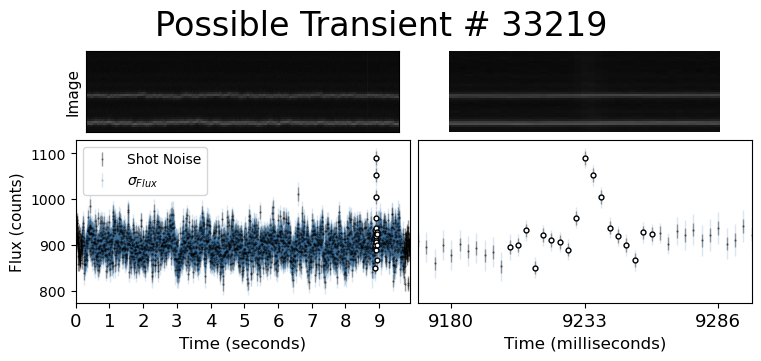

49.431034482758605


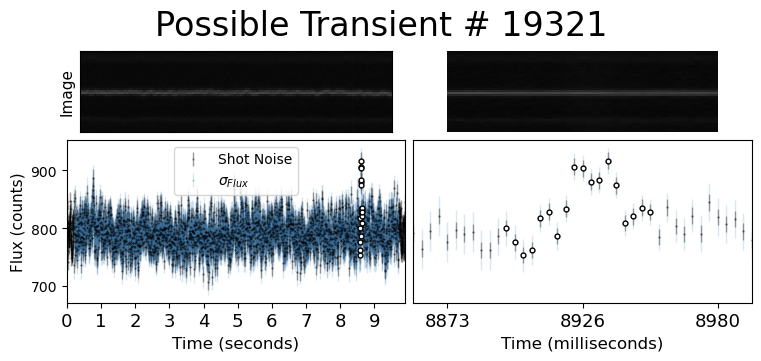

6.6785714285715585


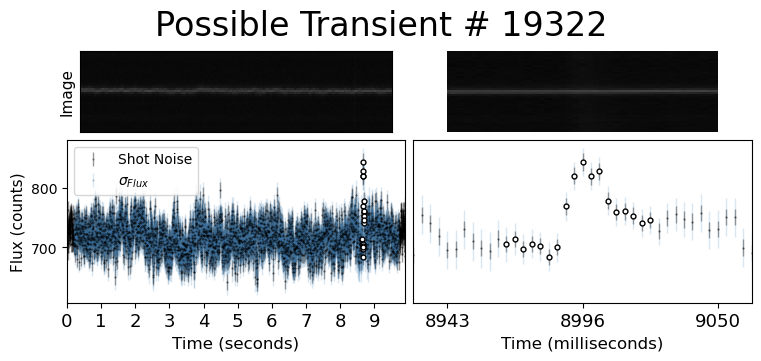

13.33333333333303


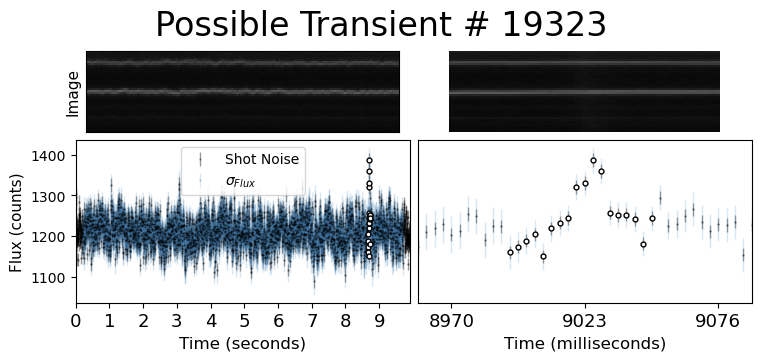

87.875


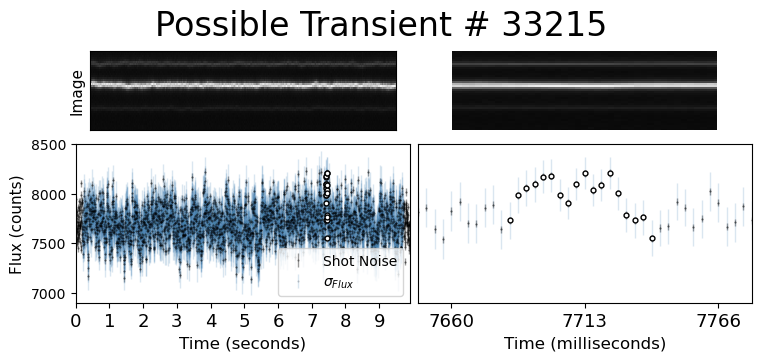

61.935897435897004


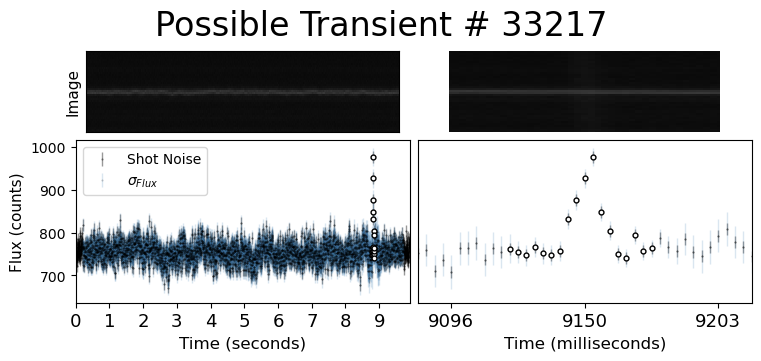

In [164]:
indices = show_simultaneous_ones(33219, df_last,threshold=100)

In [67]:
def plot_lcs_together(*rowindex, df, time_adjusted=True, hap=2, xmin=None, xmax=None):
    '''
    plots light curve with transient candidates, color coded to
    which part of the pipeline they were removed on
    give it lc_filename OR df and rowindex (make lc_filename=None)
    hap: half aperture for light curve, allowable from 2 to 5
    '''
    fig, ax = plt.subplots()
    for i, rindex in enumerate(rowindex):
        lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
        df_row = df.loc[rindex]
        lc_filename = 'lightcurve_'+df_row['filename'][:-1]+'_'+str(df_row['quadrant'])+'_'+f'{int(df_row["closest_x"]):04}'+'_'+f'{int(df_row["closest_y"]):04}'+'.csv'
        row_num = (int(df_row['row_from_nn'])+10)
        
        lightcurve_path = '/lustre/lrspec/ZTF_data/lightcurves/1020/'
        lc_df = pd.read_csv(lightcurve_path+lc_filename)
        
        
        timeseries = lc_df['flux_hap_'+str(hap)]
        to_subtract = i*1.5
        tot = (timeseries-np.min(timeseries))/(np.max(timeseries)-np.min(timeseries)) - to_subtract
        
        fluxerr = np.sqrt(timeseries / 6.2 + 8.5**2)/(np.max(timeseries)-np.min(timeseries))  # 6.2 electrons per photon, read noise is 8.5
        if time_adjusted==True:
            remove = int(df_row["closest_y"])
        else:
            remove = 0
        ax.errorbar(
            np.arange(len(tot))-remove,
            tot,
            yerr=fluxerr,
            color="black",
            ecolor="black",
            # elinewidth=1,
            linestyle="none",
            marker=".",
            # markersize=1,
            alpha=0.4,
            label="Shot Noise",
            # zorder=10
        )
    
        ax.plot(
            np.arange(len(tot))[row_num - 9 : row_num + 9] -remove,
            tot[row_num - 9 : row_num + 9],
            color="white",
            linestyle="none",
            marker=".",
            markersize=7,
            markeredgecolor="red",
            zorder=10,
        )
    if time_adjusted==True:
        ax.set_title("Lightcurve with time adjusted for star position "+str(rowindex[0]),fontsize=20)
    else:
        ax.set_title("Lightcurve with time NOT adjusted for star position"+str(rowindex[0]),fontsize=20)

    ax.set_ylabel("Flux (scaled)", fontsize=11)
    # ax.set_xlabel("Time (seconds)", fontsize=12)
    # ax.set_xticks(np.linspace(0, 3080 * 10 / 11, 10))
    # ax.set_xticklabels(
    #     np.round(np.linspace(0, 9, 10, dtype="int")), fontsize=13
    # )
    # ax.legend(bbox_to_anchor=(1.1, 1.05),fontsize=18)
    ax.set_xlim(xmin,xmax)
    fig.show()

In [207]:
f'{int(df_last.loc[19323]["closest_x"]):04}'

'0290'

In [191]:
indices

[19321, 19322, 19323, 33215, 33217]

In [261]:
fname = 'ztf_20221020138241_000686_zi_c02_x_0029.fits.fz'

In [263]:
direcname = '1020'
quad = 1
fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
    )
path = fpath + fname
hdul = fits.open(path)
# print(path)
file1_array = hdul[quad].data

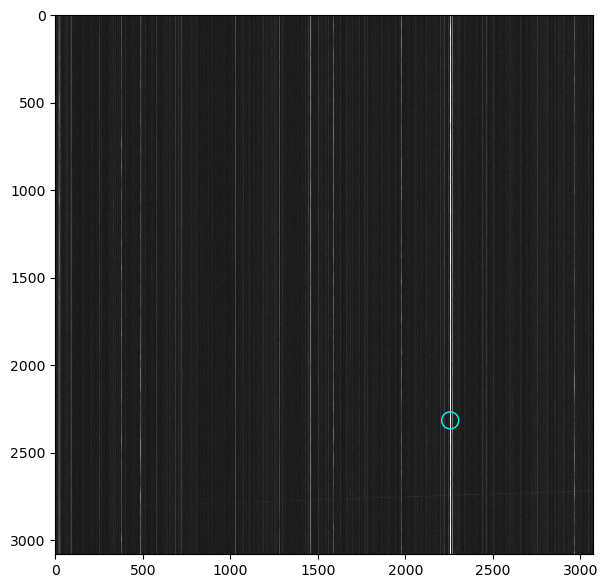

In [306]:
plt.imshow(np.log10(file1_array))
(19321, 19322, 19323, 33215, 33217)
for index in [33215]:
    plt.scatter(df_last.loc[index]['col_from_nn']+10, df_last.loc[index]['row_from_nn']+10, s=150,facecolor='none',color='cyan')#,markeredgecolor='blue')
# plt.plot(col_from_nn+10, row_from_nn+10, ms=50)

In [260]:
df_last.iloc[33217]

Unnamed: 0.2                                                33217
Unnamed: 0.1                                                33217
Unnamed: 0                                                  33217
0                                                          399996
1                                                              10
2                                                              10
3                                                             232
4                                                             232
filename                 ztf_20221020138241_000686_zi_c02_x_0029.
type                                                          pos
row_from_nn                                           2735.435897
col_from_nn                                           2213.153846
detection_size                                               39.0
quadrant                                                        1
sobel_ratio                                              8.139118
snr_center

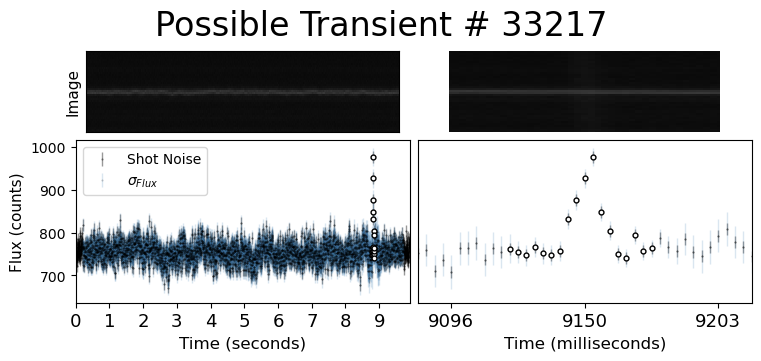

In [259]:
rff.plot_time_series_again_aperture(
    df_last,
    33217)

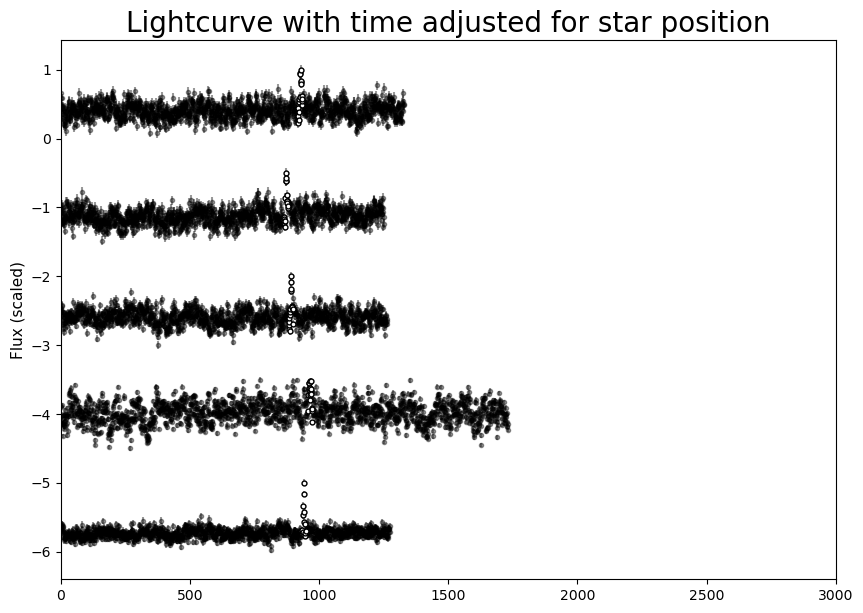

In [326]:
plot_lcs_together(19321, 19322, 19323, 33215, 33217, df=df_last, time_adjusted=True,xmin=0,xmax=3000)
#

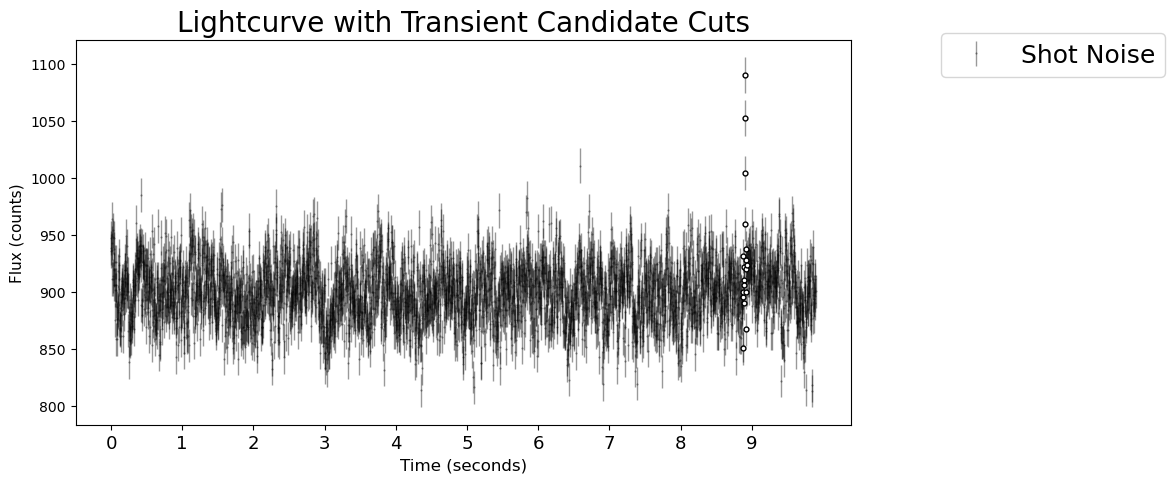

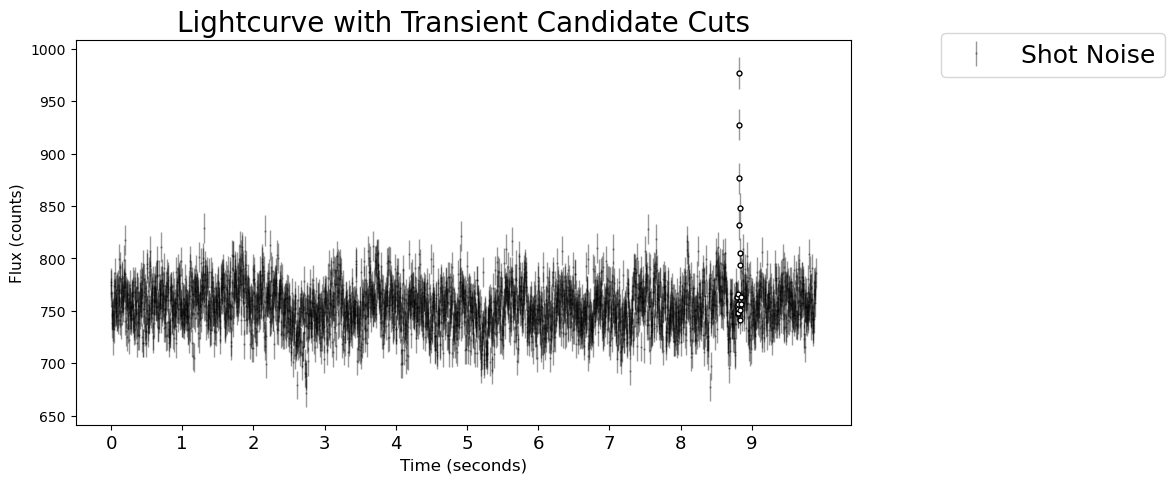

In [181]:
plot_lc_from_csv(None, df_last, 33219)
plot_lc_from_csv(None, df_last, 33217)

In [3]:
best_cands = pd.read_csv('/home/3155/best_cands')

In [4]:
best_cands = add_distance_from_start(best_cands)

In [8]:
best_cands

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,...,noise_local,noise_global,local_average_outside,height,FWHM,signal_local,has_two_streaks,has_two_streaks_prom20,has_two_streaks_prom15,distance_from_start
0,776,776,776,776,9074,2,2,11,11,ztf_20221020297847_000449_zr_c01_x_0008.,...,22.590435,32.054603,766.986678,108.024735,9.0,25.077692,False,False,False,-1083.250000
1,1389,1389,1389,1389,16380,309,309,636,636,ztf_20221020148032_000686_zg_c16_x_0005.,...,33.465428,37.921016,1151.866137,188.627551,10.0,34.542521,False,False,False,-879.363636
2,2022,2022,2022,2022,24294,22,22,79,79,ztf_20221020163819_000640_zg_c16_x_0025.,...,29.931357,37.682118,1267.977484,135.349310,13.0,36.438755,False,False,False,1036.428571
3,4117,4117,4117,4117,49392,31,31,231,231,ztf_20221020148032_000686_zg_c16_x_0014.,...,30.953517,34.980782,1119.936158,124.624388,11.0,32.072367,False,False,False,-955.333333
4,7038,7038,7038,7038,84108,17,17,75,75,ztf_20221020294271_000449_zr_c09_x_0009.,...,44.146551,59.385172,1383.459114,236.071663,13.0,44.642257,False,False,False,-2533.333333
5,7501,7501,7501,7501,89370,13,13,51,51,ztf_20221020294271_000449_zr_c14_x_0017.,...,33.208907,53.458823,1226.360753,325.812657,8.0,45.150082,False,False,False,-1724.800000
6,9090,9090,9090,9090,108373,11,11,37,37,ztf_20221020294271_000449_zr_c09_x_0011.,...,40.996936,54.012868,1404.537098,224.468983,14.0,46.205845,False,False,False,-814.250000
7,9399,9399,9399,9399,111744,36,36,101,101,ztf_20221020148032_000686_zg_c11_x_0026.,...,41.909017,45.263732,1266.050242,280.319285,12.0,49.052356,False,False,False,-310.586957
8,10591,10591,10591,10591,126793,1,1,13,13,ztf_20221020294271_000449_zr_c09_x_0018.,...,33.772347,45.540434,1491.616769,201.704781,17.0,51.337502,False,False,False,-1088.857143
9,13111,13111,13111,13111,158180,0,0,0,0,ztf_20221020154120_000640_zi_c13_x_0018.,...,23.178516,26.275247,650.224886,117.596831,8.0,23.659030,False,False,False,1870.200000


In [74]:
num_simultaneous_20_snrp1_fixed_crit = []
threshold=20
df_last_ = df_last[df_last['snr_local']>.1]
for i, row in best_cands.iterrows():
    same_file_df = df_last_[df_last_['filename']==row['filename']]
    
    print(row['filename'])
    binwidth = 15
    num = 0
    for i2, same_file_df_row in same_file_df.iterrows():
        num += np.abs(row['distance_from_start']-same_file_df_row['distance_from_start'])<threshold and row['closest_x']!=same_file_df_row['closest_x'] and row['type']==same_file_df_row['type']and row['quadrant']==same_file_df_row['quadrant']
    num_simultaneous_20_snrp1_fixed_crit.append(num)

ztf_20221020297847_000449_zr_c01_x_0008.
ztf_20221020148032_000686_zg_c16_x_0005.
ztf_20221020163819_000640_zg_c16_x_0025.
ztf_20221020148032_000686_zg_c16_x_0014.
ztf_20221020294271_000449_zr_c09_x_0009.
ztf_20221020294271_000449_zr_c14_x_0017.
ztf_20221020294271_000449_zr_c09_x_0011.
ztf_20221020148032_000686_zg_c11_x_0026.
ztf_20221020294271_000449_zr_c09_x_0018.
ztf_20221020154120_000640_zi_c13_x_0018.
ztf_20221020297847_000449_zr_c09_x_0012.
ztf_20221020163819_000640_zg_c10_x_0011.
ztf_20221020294271_000449_zr_c12_x_0023.
ztf_20221020297847_000449_zr_c09_x_0016.
ztf_20221020148032_000686_zg_c03_x_0019.
ztf_20221020297847_000449_zr_c03_x_0004.
ztf_20221020138241_000686_zi_c02_x_0029.
ztf_20221020138241_000686_zi_c02_x_0029.
ztf_20221020163819_000640_zg_c07_x_0000.
ztf_20221020148032_000686_zg_c01_x_0018.
ztf_20221020297847_000449_zr_c14_x_0015.
ztf_20221020138241_000686_zi_c08_x_0001.
ztf_20221020297847_000449_zr_c14_x_0019.
ztf_20221020148032_000686_zg_c07_x_0016.
ztf_202210201480

In [75]:
num_simultaneous_20_snrp1_fixed_crit

[0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 1,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0,
 0]

In [76]:
best_cands['num_simultaneous_20_p1'] = num_simultaneous_20_snrp1_fixed_crit

In [77]:
best_cands[best_cands['num_simultaneous_20_p1']>0]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,...,local_average_outside,height,FWHM,signal_local,has_two_streaks,has_two_streaks_prom20,has_two_streaks_prom15,distance_from_start,num_simultaneous_20_p1,num_simultaneous_image_20_snrp1
3,4117,4117,4117,4117,49392,31,31,231,231,ztf_20221020148032_000686_zg_c16_x_0014.,...,1119.936158,124.624388,11.0,32.072367,False,False,False,-955.333333,1,0
21,38676,38676,38676,38676,464300,26,26,104,104,ztf_20221020138241_000686_zi_c08_x_0001.,...,1522.483407,175.064567,15.0,42.855883,False,False,False,162.400000,1,1


In [85]:
best_cands

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,...,local_average_outside,height,FWHM,signal_local,has_two_streaks,has_two_streaks_prom20,has_two_streaks_prom15,distance_from_start,num_simultaneous_20_p1,num_simultaneous_image_20_snrp1
0,776,776,776,776,9074,2,2,11,11,ztf_20221020297847_000449_zr_c01_x_0008.,...,766.986678,108.024735,9.0,25.077692,False,False,False,-1083.250000,0,0
1,1389,1389,1389,1389,16380,309,309,636,636,ztf_20221020148032_000686_zg_c16_x_0005.,...,1151.866137,188.627551,10.0,34.542521,False,False,False,-879.363636,0,1
2,2022,2022,2022,2022,24294,22,22,79,79,ztf_20221020163819_000640_zg_c16_x_0025.,...,1267.977484,135.349310,13.0,36.438755,False,False,False,1036.428571,0,0
3,4117,4117,4117,4117,49392,31,31,231,231,ztf_20221020148032_000686_zg_c16_x_0014.,...,1119.936158,124.624388,11.0,32.072367,False,False,False,-955.333333,1,0
4,7038,7038,7038,7038,84108,17,17,75,75,ztf_20221020294271_000449_zr_c09_x_0009.,...,1383.459114,236.071663,13.0,44.642257,False,False,False,-2533.333333,0,0
5,7501,7501,7501,7501,89370,13,13,51,51,ztf_20221020294271_000449_zr_c14_x_0017.,...,1226.360753,325.812657,8.0,45.150082,False,False,False,-1724.800000,0,0
6,9090,9090,9090,9090,108373,11,11,37,37,ztf_20221020294271_000449_zr_c09_x_0011.,...,1404.537098,224.468983,14.0,46.205845,False,False,False,-814.250000,0,0
7,9399,9399,9399,9399,111744,36,36,101,101,ztf_20221020148032_000686_zg_c11_x_0026.,...,1266.050242,280.319285,12.0,49.052356,False,False,False,-310.586957,0,0
8,10591,10591,10591,10591,126793,1,1,13,13,ztf_20221020294271_000449_zr_c09_x_0018.,...,1491.616769,201.704781,17.0,51.337502,False,False,False,-1088.857143,0,0
9,13111,13111,13111,13111,158180,0,0,0,0,ztf_20221020154120_000640_zi_c13_x_0018.,...,650.224886,117.596831,8.0,23.659030,False,False,False,1870.200000,0,0


(40, 40)


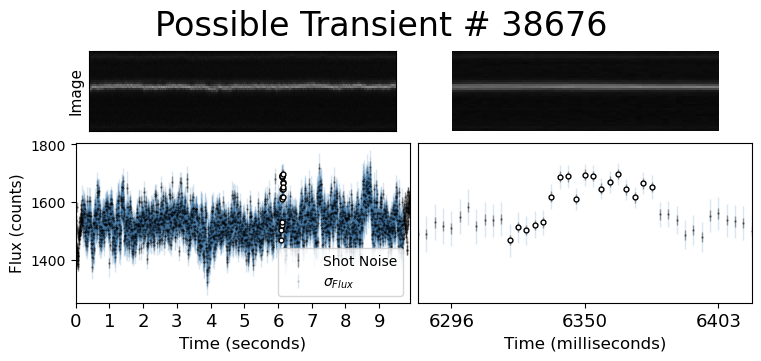

5.885714285714357


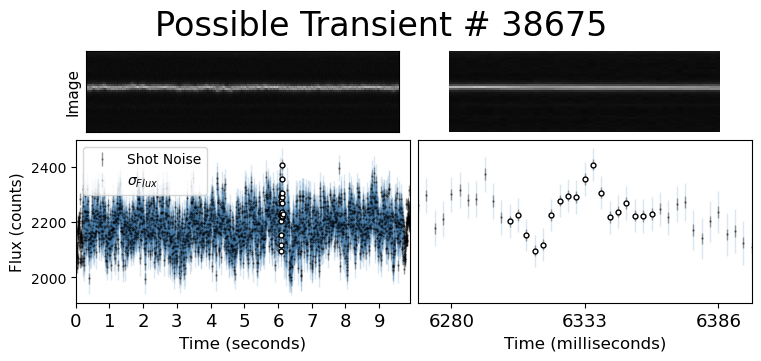

In [94]:
indices = show_simultaneous_ones(38676, df_last,df_last,threshold=20)


In [95]:
indices

[38675]

4117 2451 2100
4115 1321 2552


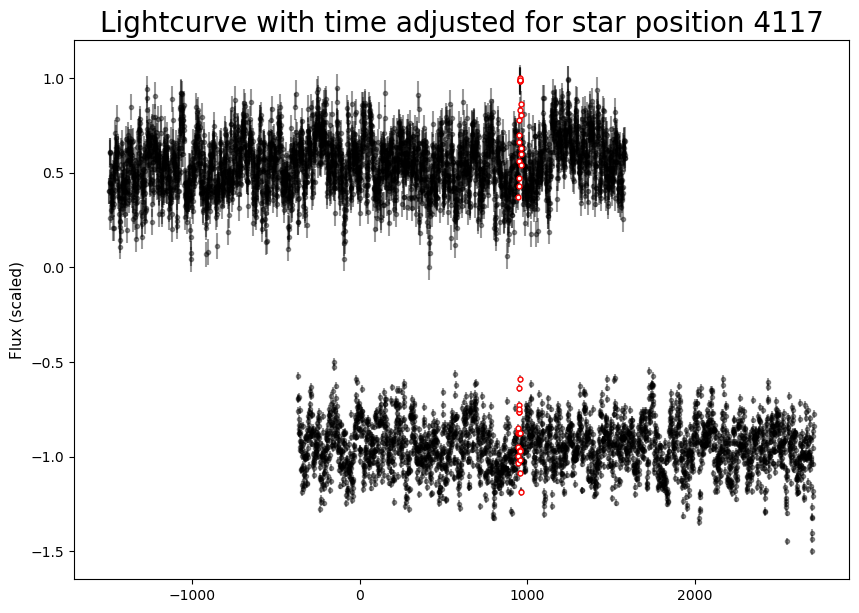

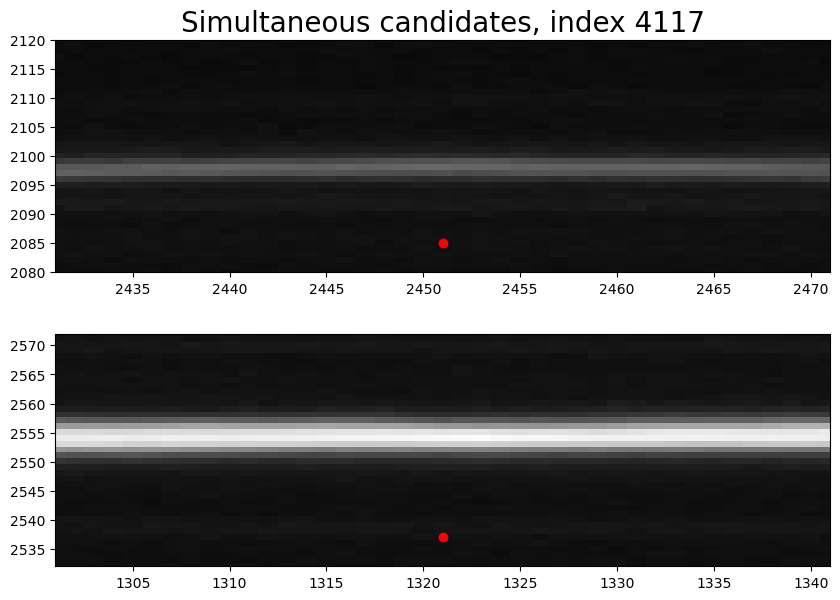

In [104]:
plot_lcs_together(4117,4115, time_adjusted=True, df=df_last)#,xmin=-1000,xmax=0)
plot_lcs_together_images(4117,4115, df=df_last)

38676 1905 2731
38675 1900 1796


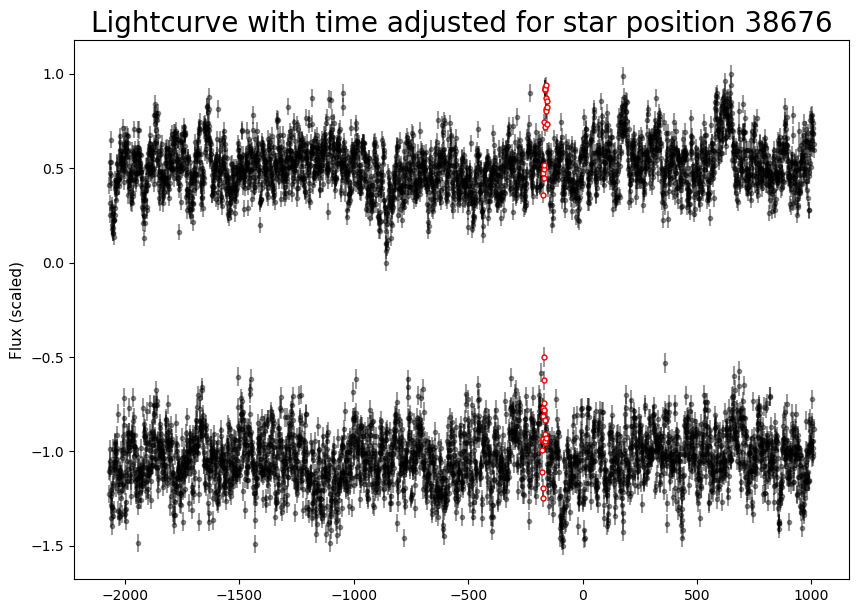

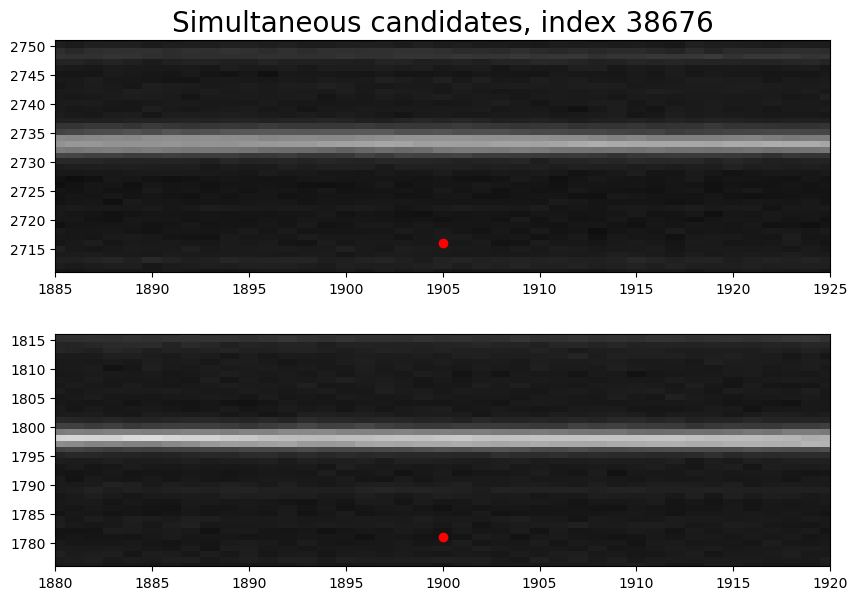

In [105]:
plot_lcs_together(38676,38675, time_adjusted=True, df=df_last)#,xmin=-1000,xmax=0)
plot_lcs_together_images(38676,38675, df=df_last)

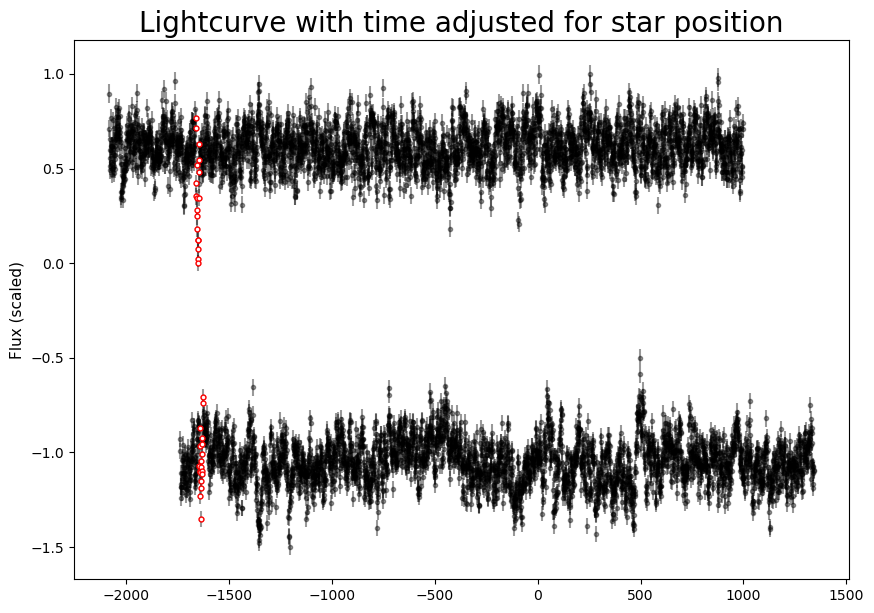

In [349]:
plot_lcs_together(39033,11685, time_adjusted=True, df=df_last) #xmin=-1000,xmax=1000)


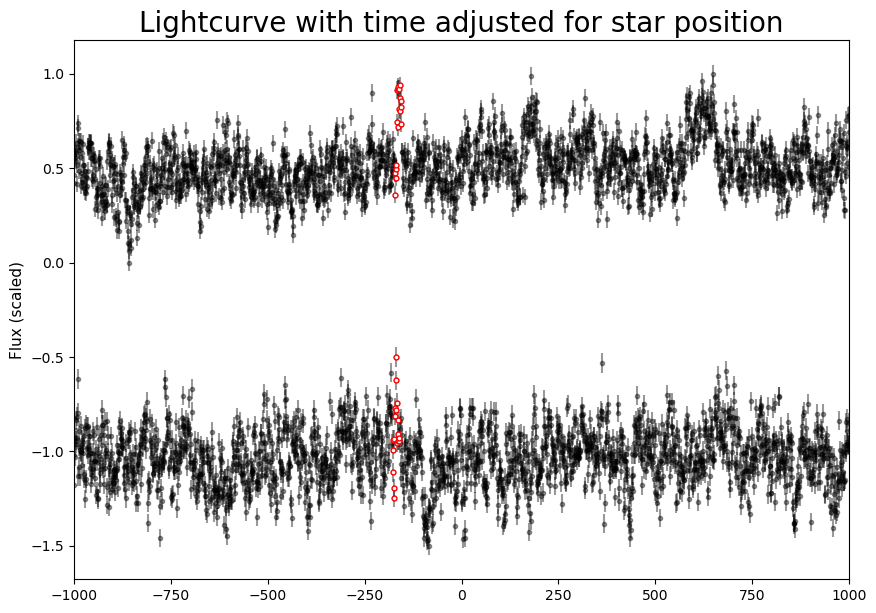

In [345]:
plot_lcs_together(38676,38675, time_adjusted=True, df=df_last, xmin=-1000,xmax=1000)


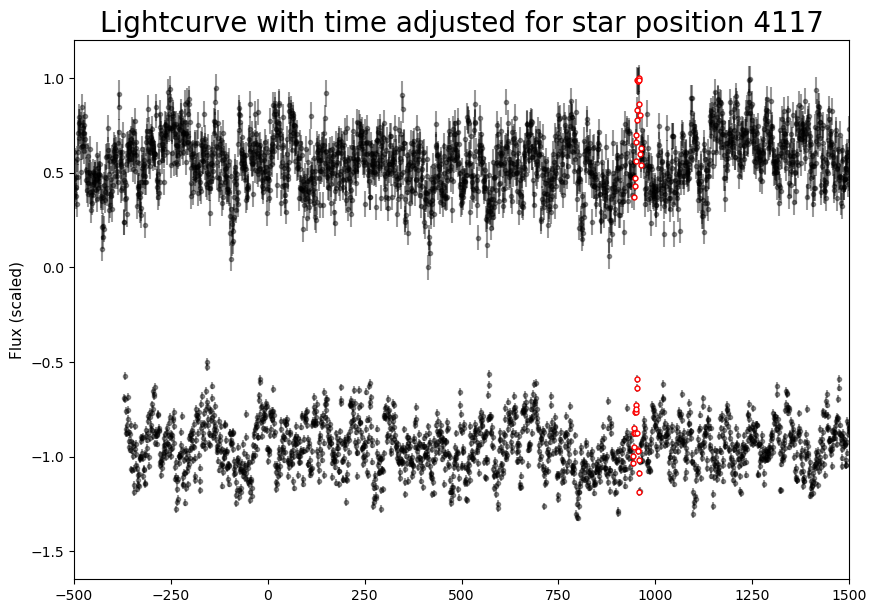

In [375]:
plot_lcs_together(4117,4115, time_adjusted=True, df=df_last, xmin=-500,xmax=1500)


In [366]:
best_cands = best_cands[best_cands['Unnamed: 0.3']!=33219]
best_cands = best_cands[best_cands['Unnamed: 0.3']!=33217]

In [61]:
num_simultaneous_image_20_snrp1 = []
threshold=20
df_last_ = df_last[df_last['snr_local']>.1]
for i, row in best_cands.iterrows():
    same_file_df = df_last_[df_last_['filename']==row['filename']]
    
    print(row['filename'])
    binwidth = 15
    num = 0
    for i2, same_file_df_row in same_file_df.iterrows():
        num += np.abs(row['row_from_nn']-same_file_df_row['row_from_nn'])<threshold and row['closest_x']!=same_file_df_row['closest_x'] and row['type']==same_file_df_row['type'] and row['quadrant']==same_file_df_row['quadrant']
    num_simultaneous_image_20_snrp1.append(num)

ztf_20221020297847_000449_zr_c01_x_0008.
ztf_20221020148032_000686_zg_c16_x_0005.
ztf_20221020163819_000640_zg_c16_x_0025.
ztf_20221020148032_000686_zg_c16_x_0014.
ztf_20221020294271_000449_zr_c09_x_0009.
ztf_20221020294271_000449_zr_c14_x_0017.
ztf_20221020294271_000449_zr_c09_x_0011.
ztf_20221020148032_000686_zg_c11_x_0026.
ztf_20221020294271_000449_zr_c09_x_0018.
ztf_20221020154120_000640_zi_c13_x_0018.
ztf_20221020297847_000449_zr_c09_x_0012.
ztf_20221020163819_000640_zg_c10_x_0011.
ztf_20221020294271_000449_zr_c12_x_0023.
ztf_20221020297847_000449_zr_c09_x_0016.
ztf_20221020148032_000686_zg_c03_x_0019.
ztf_20221020297847_000449_zr_c03_x_0004.
ztf_20221020138241_000686_zi_c02_x_0029.
ztf_20221020138241_000686_zi_c02_x_0029.
ztf_20221020163819_000640_zg_c07_x_0000.
ztf_20221020148032_000686_zg_c01_x_0018.
ztf_20221020297847_000449_zr_c14_x_0015.
ztf_20221020138241_000686_zi_c08_x_0001.
ztf_20221020297847_000449_zr_c14_x_0019.
ztf_20221020148032_000686_zg_c07_x_0016.
ztf_202210201480

In [62]:
best_cands['num_simultaneous_image_20_snrp1'] = num_simultaneous_image_20_snrp1

In [63]:
best_cands[best_cands['num_simultaneous_image_20_snrp1']>0]

,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,0,1,2,3,4,filename,...,local_average_outside,height,FWHM,signal_local,has_two_streaks,has_two_streaks_prom20,has_two_streaks_prom15,distance_from_start,num_simultaneous_20_p1,num_simultaneous_image_20_snrp1
1,1389,1389,1389,1389,16380,309,309,636,636,ztf_20221020148032_000686_zg_c16_x_0005.,...,1151.866137,188.627551,10.0,34.542521,False,False,False,-879.363636,0,1
16,33217,33217,33217,33217,399996,10,10,232,232,ztf_20221020138241_000686_zi_c02_x_0029.,...,757.456614,219.535695,5.0,25.974844,False,False,False,-940.435897,1,2
17,33219,33219,33219,33219,399998,12,12,243,243,ztf_20221020138241_000686_zi_c02_x_0029.,...,906.274684,183.650976,5.0,22.637941,True,False,False,-878.500000,2,1
21,38676,38676,38676,38676,464300,26,26,104,104,ztf_20221020138241_000686_zi_c08_x_0001.,...,1522.483407,175.064567,15.0,42.855883,False,False,False,162.400000,1,1


In [64]:
def get_simultaneous_image_ones(index, df_last=df_last, our_cands=best_cands, snr_limit=.1, threshold=20):
    indices = [index]
    df_last_ = df_last[df_last['snr_local']>snr_limit]
    row = df_last.loc[index]
    same_file_df = df_last_[df_last_['filename']==row['filename']]
    print(np.shape(same_file_df))
    # print(same_file_df)
    for i, row2 in same_file_df.iterrows():
        # print(i)
        if np.abs(row['row_from_nn']-row2['row_from_nn'])<threshold and row['closest_x']!=row2['closest_x'] and row['type']==row2['type']and row['quadrant']==row2['quadrant']:
            print(np.abs(row['row_from_nn']-row2['row_from_nn']))
            indices.append(i)
    return indices

In [386]:
indices = get_simultaneous_image_ones(1389)

(86, 40)
11.863636363636488


In [65]:
for i, row in best_cands[best_cands['num_simultaneous_image_20_snrp1']>0].iterrows():
    index = row['Unnamed: 0.3']
    print(index)
    indices = get_simultaneous_image_ones(index)
    print(indices)


1389
(86, 40)
11.863636363636488
[1389, 1388]
33217
(43, 40)
1.9358974358970045
8.322723253758795
[33217, 33216, 33218]
33219
(43, 40)
16.7413793103442
[33219, 33218]
38676
(40, 40)
4.885714285714357
[38676, 38675]


1389 2839 2836
1388 2827 611


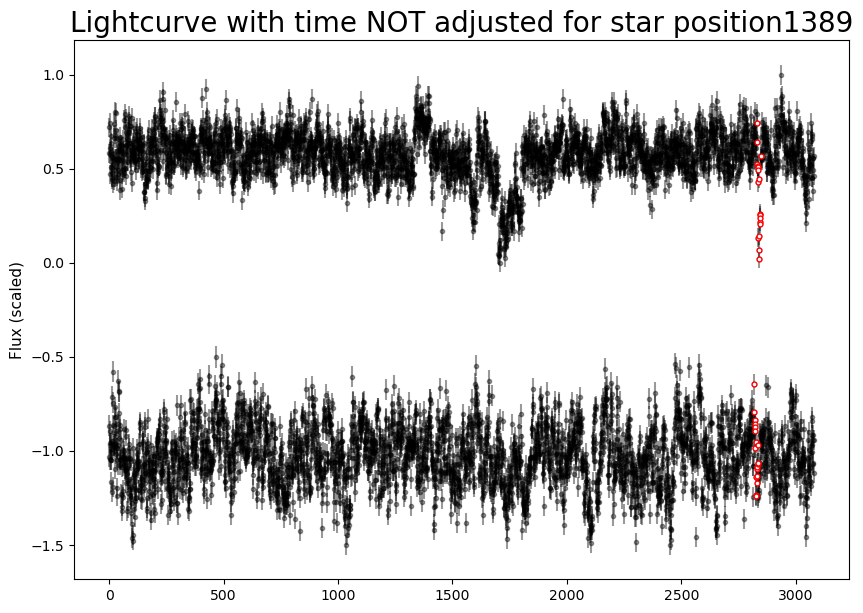

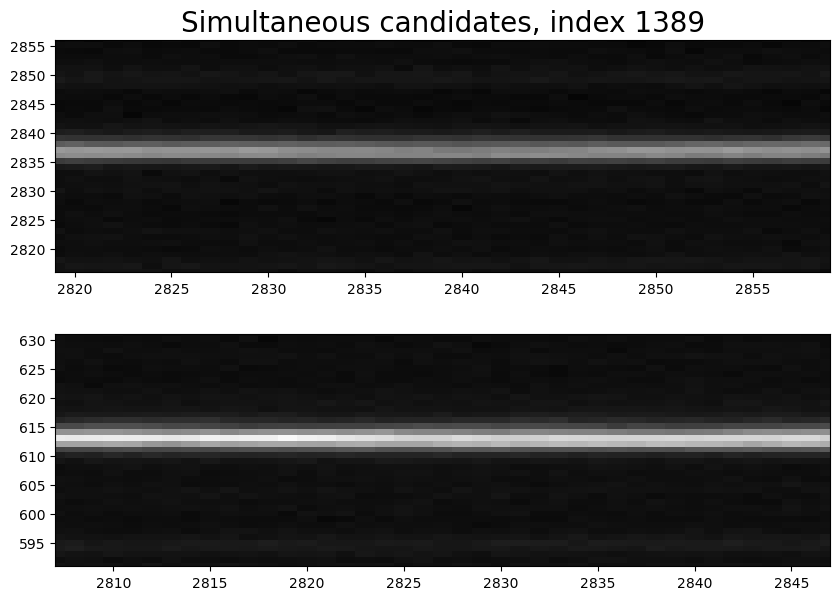

In [68]:
plot_lcs_together(1389, 1388, time_adjusted=False, df=df_last)#, xmin=-500,xmax=1500)
plot_lcs_together_images(1389, 1388, df=df_last)

33217 2745 2223
33216 2743 2271
33218 2753 1977


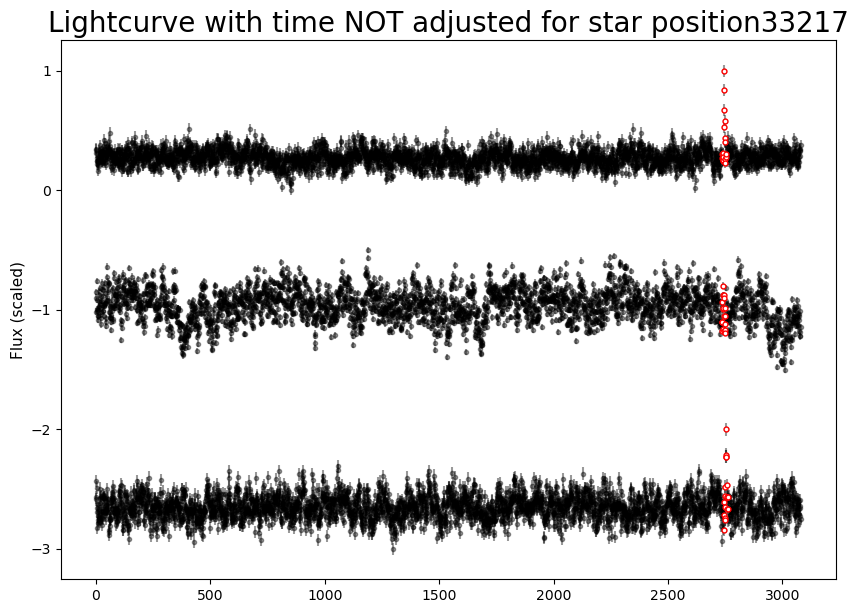

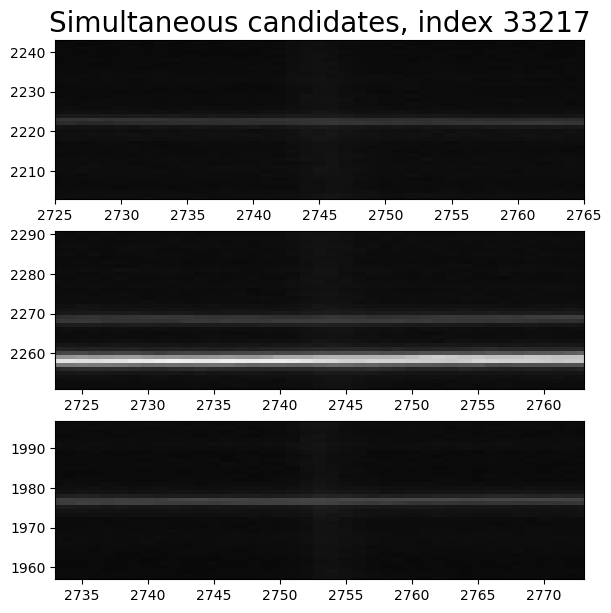

In [69]:
plot_lcs_together(33217, 33216, 33218, time_adjusted=False, df=df_last)#, xmin=-500,xmax=1500)
plot_lcs_together_images(33217, 33216, 33218, df=df_last)

33219 2770 1460
33218 2753 1977


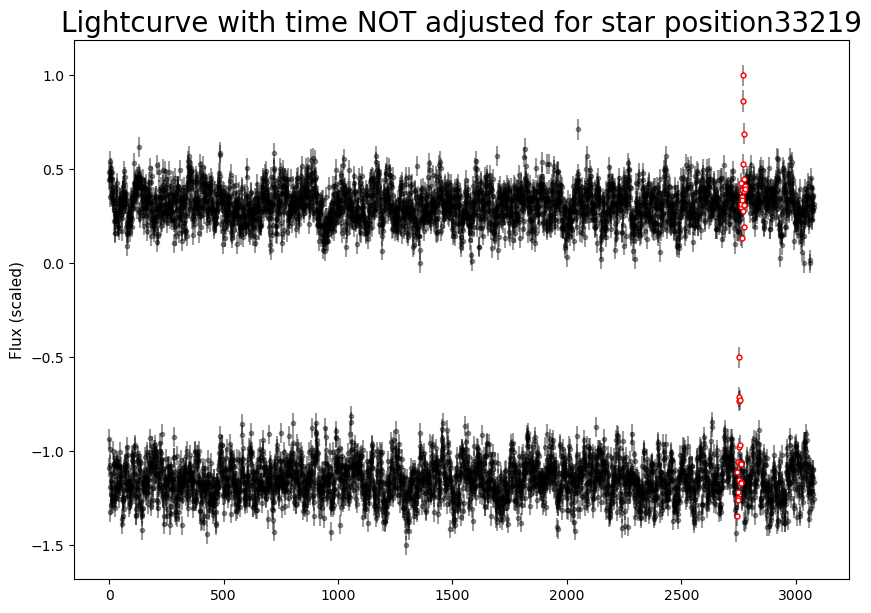

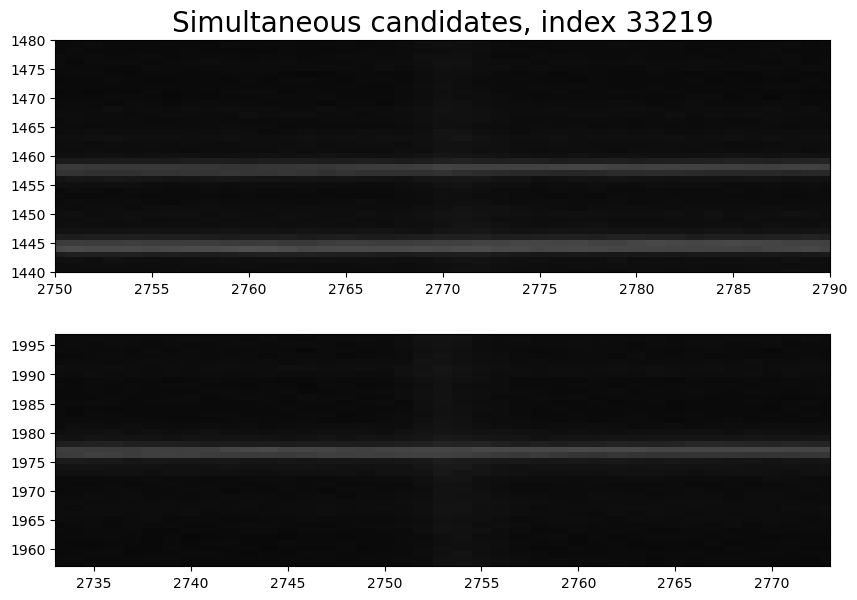

In [70]:
plot_lcs_together(33219, 33218, time_adjusted=False, df=df_last)#, xmin=-500,xmax=1500)
plot_lcs_together_images(33219, 33218, df=df_last)

38676 1905 2731
38675 1900 1796


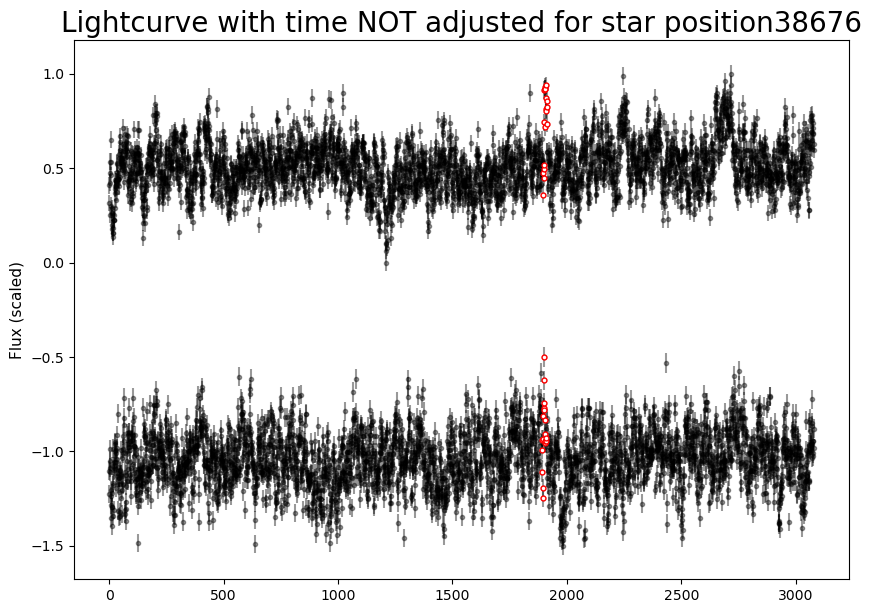

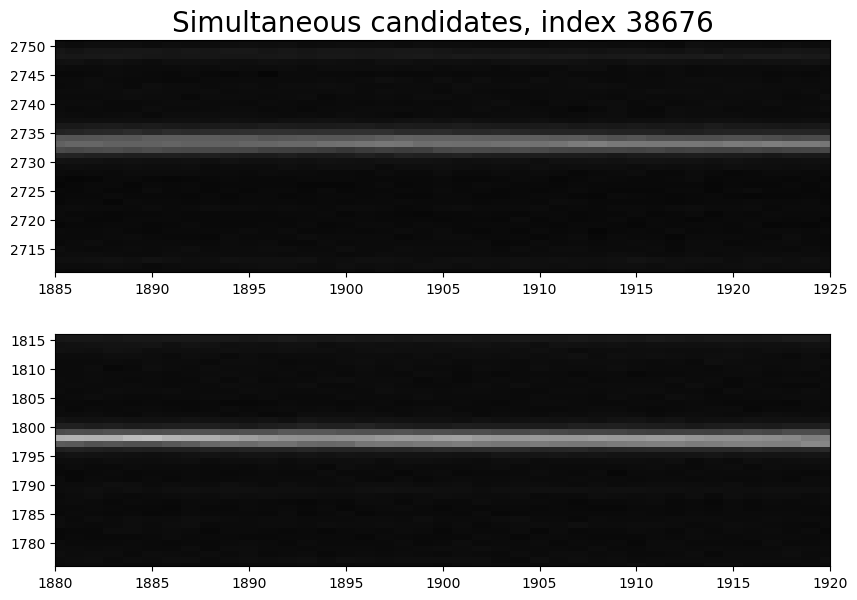

In [71]:

plot_lcs_together(38676, 38675, time_adjusted=False, df=df_last)#, xmin=-500,xmax=1500)
plot_lcs_together_images(38676, 38675, df=df_last)

In [398]:
best_cands = best_cands[best_cands['Unnamed: 0.3']!=7501]
best_cands = best_cands[best_cands['Unnamed: 0.3']!=29863]

In [102]:
def plot_lcs_together_images(*rowindex, df,line=True):
    '''
    plots light curve with transient candidates, color coded to
    which part of the pipeline they were removed on
    give it df and rowindex 
    hap: half aperture for light curve, allowable from 2 to 5
    '''
    fig, ax = plt.subplots(len(rowindex),1)
    ax[0].set_title("Simultaneous candidates, index "+str(rowindex[0]),fontsize=20)

    direcname = '1020'
    fpath = (
        "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"
        + direcname
        + "_minus_extras/"
        )
    fname = df.loc[rowindex[0]]["filename"] + "fits.fz"
    quad = int(df.loc[rowindex[0]]["quadrant"])
    path = fpath + fname
    hdul = fits.open(path)
    image = np.log1p(hdul[quad].data)
    for i, rindex in enumerate(rowindex):
        df_row = df.loc[rindex]
        row_num = int(df_row["row_from_nn"]) + 10
        column = int(df_row["col_from_nn"]) + 10
        print(rindex, row_num, column)
        ax[i].imshow(np.sqrt(image).T, aspect=0.3, cmap="gist_gray")
        ax[i].set_xlim(row_num - 20, row_num + 20)
        ax[i].set_ylim(column - 20, column + 20)
        if line:
            ax[i].scatter(row_num,column-15,color='red')

    fig.show()

38676 1905 2731
38675 1900 1796


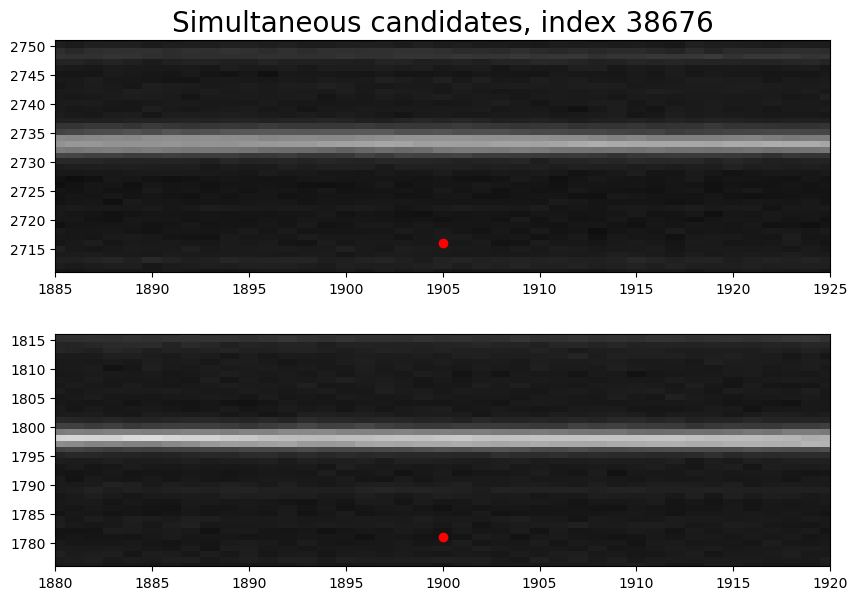

In [103]:
plot_lcs_together_images(38676, 38675, df=df_last)

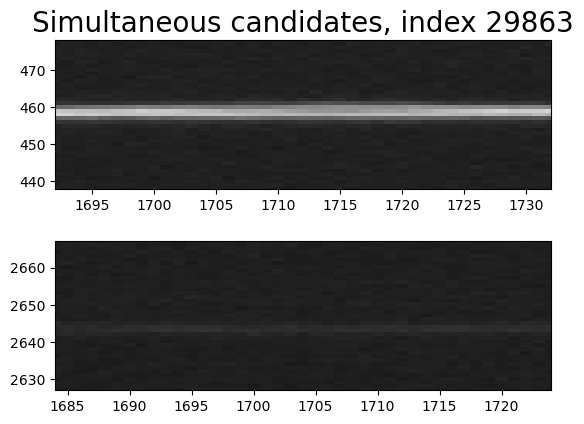

In [44]:

plot_lcs_together_images(29863, 41794, df=df_last)

In [46]:
df_last.loc[49690]

Unnamed: 0.2                                                49690
Unnamed: 0.1                                                49690
Unnamed: 0                                                  49690
0                                                          593871
1                                                             108
2                                                             108
3                                                             215
4                                                             215
filename                 ztf_20221020294271_000449_zr_c14_x_0017.
type                                                          neg
row_from_nn                                           2177.958333
col_from_nn                                              1322.375
detection_size                                               48.0
quadrant                                                        4
sobel_ratio                                             12.301595
snr_center

7501 2185 706
49690 2187 1332


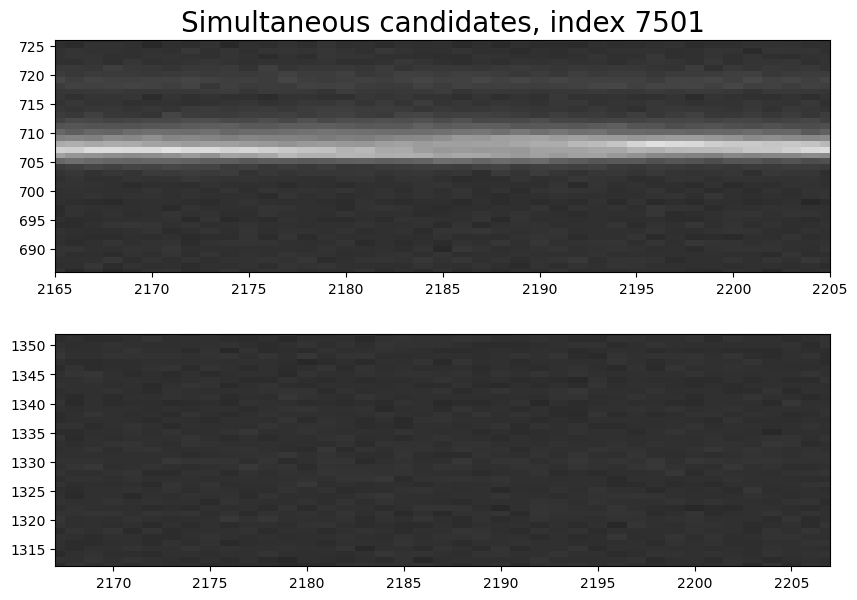

In [58]:
plot_lcs_together_images(7501,49690, df=df_last)

49690 2187 1332
7501 2185 706


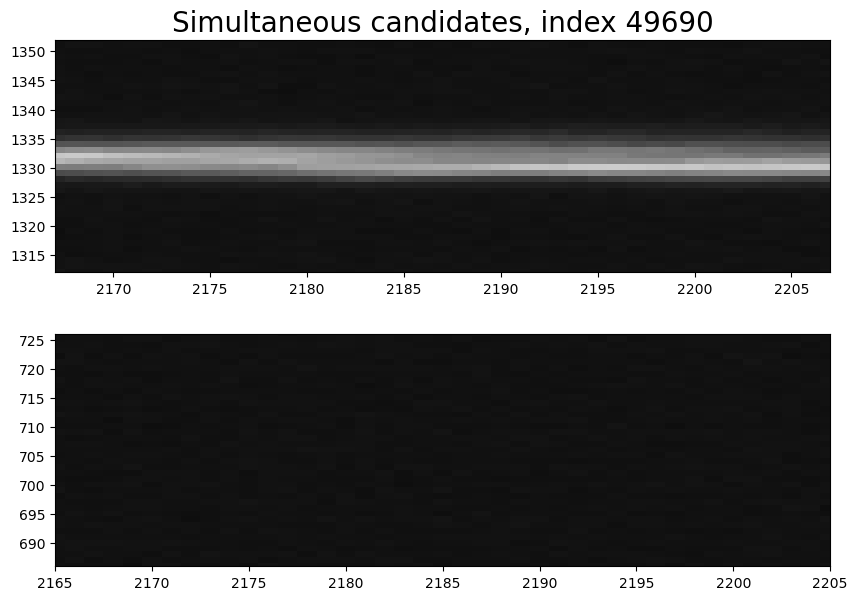

In [57]:

plot_lcs_together_images(49690, 7501,df=df_last)

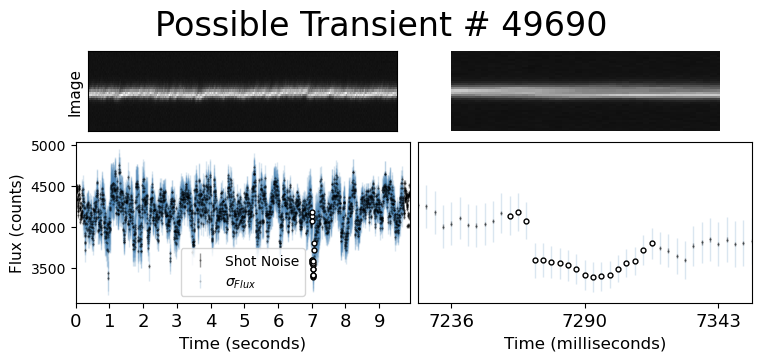

In [50]:
rff.plot_time_series_again_aperture(
    df_last,49690)

In [107]:
best_cands = best_cands[best_cands['Unnamed: 0.3']!=33217]
best_cands = best_cands[best_cands['Unnamed: 0.3']!=33219]

In [108]:
best_cands.to_csv('/home/3155/best_cands_nosim')